<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-07/lab-033-signal-characterisation.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 033 <br>
<hr/>

# Lab 033 — Signal characterisation

A time series $s_1,s_2,\dots,s_N$ is a sequence of measurements of one quantity taken at equal time intervals $\Delta t$. Before we try to forecast such a series with any model, linear or neural, we characterise the signal itself. We ask how long it remembers its past, which frequencies carry its power, how many past values are needed to fix the present state of the system that produced it, how fast two nearby states separate, and how many effective degrees of freedom the motion explores. The answers set what any forecasting method can achieve, and they guide the choice of the forecasting models that follow.

We work with three signals that are used throughout the time-series notebooks. The first is the $x$ coordinate of the Lorenz-63 model of thermal convection, a three-dimensional chaotic flow. The second is the Mackey–Glass delay equation for blood-cell production at three values of the feedback delay, which give a periodic orbit and two chaotic regimes. The third is the intensity of a chaotic far-infrared laser measured in the laboratory, the Santa Fe data set A. Section 1 generates the signals. Section 2 defines the time-series tasks and compares easy, chaotic and stochastic signals. Section 3 introduces the physics and the equations of the three benchmark signals. Sections 4 and 5 treat the linear statistics, the autocorrelation function (ACF) and the power spectral density (PSD), with the standard tools of signal processing. Section 6 reconstructs the state space from a single measured coordinate (delay embedding). Section 7 introduces deterministic chaos on the simplest example, the logistic map, and Section 8 computes the Lyapunov exponents of the flows and of the measured laser data. Section 9 turns them into an attractor dimension, checked on the dissipative baker's map whose dimension is known, and a prediction horizon. Section 10 decides from the record alone whether a signal is deterministic or noise with the same spectrum, with false nearest neighbours, a nearest-neighbour forecast, the surrogate data test, two estimators of the leading exponent and the correlation dimension. Section 11 collects all numbers in one table, and Section 12 states what they imply for forecasting.

All computations use JAX in double precision (`jax_enable_x64`). Where a standard library offers the same quantity (statsmodels for the ACF, scipy for periodograms, the Welch estimate and nearest-neighbour search) we compute it with both and compare.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`, and the whole notebook runs in a few minutes on a multi-core CPU.
> 2. `jax`, `scipy`, `statsmodels`, `pandas` and `matplotlib` are pre-installed in Colab.
> 3. The first code cell downloads the data file into a folder `data` next to the notebook.
> 4. Run the cells *in order*, since later cells use variables defined earlier.

In [ ]:
# data files of this notebook, downloaded from the course repository if they are not in ./data
import os, urllib.request
os.makedirs("data", exist_ok=True)
for name in ['santafe_laser.txt']:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/main/notebooks/lecture-07/data/{name}", f"data/{name}")

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
from functools import partial
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import scipy.signal
import scipy.stats
import scipy.optimize
from scipy.spatial import cKDTree
from statsmodels.tsa.stattools import acf as sm_acf

import jax
jax.config.update("jax_enable_x64", True)   # all signals and exponents in float64
import jax.numpy as jnp

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 10,
            "ytick.labelsize": 10, "legend.fontsize": 10, "lines.linewidth": 1.3, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
COL = {"lorenz": UJBlue, "mg15": "#F2A65A", "mg25": DSOrange, "mg35": "#8C2D04", "santafe": "#2E7D32"}
LABEL = {"lorenz": "Lorenz $x$", "mg15": r"MG $\tau_{\rm MG}=15$", "mg25": r"MG $\tau_{\rm MG}=25$",
         "mg35": r"MG $\tau_{\rm MG}=35$", "santafe": "Santa Fe"}
KEYS = ["lorenz", "mg15", "mg25", "mg35", "santafe"]

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    """Save a slide figure as PDF (for the slides) and PNG; it is created at its printed size."""
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

nums = {}                                   # every number a slide may quote
t_start = time.time()
print("jax", jax.__version__, "| devices", jax.devices(), "| float64", jax.config.jax_enable_x64)

jax 0.11.0 | devices [CpuDevice(id=0)] | float64 True


<hr/>
## 1. Signals and protocol

The generators below are shared by all time-series notebooks, so that every model is trained and tested on the same numbers. They integrate the equations with the fourth-order Runge–Kutta method (RK4) in `jax.lax.scan` and return $N=4000$ samples per signal. The last lines define the common protocol of the forecasting labs, a chronological split into a training block of 3000 samples, whose last 500 serve for validation, and a test block of the final 1000 samples, with rescaling to $[0,1]$ fitted on the first 2500 samples, the part of the training block on which models are fitted.

In [2]:
# Lorenz-63 with sigma = 10, rho = 28, beta = 8/3. RK4 with h = 0.01, one sample every 2 steps (dt = 0.02).
# Initial state (1, 1, 1); the first 2500 samples (50 time units) are discarded. We keep the x component.
def lorenz_rhs(u, sigma=10.0, rho=28.0, beta=8.0/3.0):
    x, y, z = u
    return jnp.array([sigma*(y - x), x*(rho - z) - y, x*y - beta*z])

def rk4_step(f, u, h):
    k1 = f(u); k2 = f(u + 0.5*h*k1); k3 = f(u + 0.5*h*k2); k4 = f(u + h*k3)
    return u + h/6.0*(k1 + 2*k2 + 2*k3 + k4)

@partial(jax.jit, static_argnums=(0, 1, 2))
def lorenz_trajectory(n_samples, sub=2, n_discard=2500, h=0.01):
    """Returns array (n_samples, 3) sampled every `sub` RK4 steps (dt = sub*h)."""
    def one_sample(u, _):
        u = jax.lax.fori_loop(0, sub, lambda i, v: rk4_step(lorenz_rhs, v, h), u)
        return u, u
    u0 = jnp.array([1.0, 1.0, 1.0])
    u, _ = jax.lax.scan(one_sample, u0, None, length=n_discard)
    _, traj = jax.lax.scan(one_sample, u, None, length=n_samples)
    return traj

# Mackey-Glass dx/dt = beta x(t-tau)/(1 + x(t-tau)^n) - gamma x with beta = 0.2, gamma = 0.1, n = 10.
# RK4 with h = 0.1; the delayed value at the half step is the linear interpolation of the two stored values.
# Constant history x = 1.2 on [-tau, 0]; the first 3000 fine steps are discarded and every 10th point is kept
# (unit sampling).
def mackey_glass(tau, n_samples, h=0.1, x0=1.2, transient=3000, every=10,
                 beta=0.2, gamma=0.1, n=10):
    lag = int(round(tau / h))
    f = lambda x, xd: beta * xd / (1.0 + xd**n) - gamma * x
    def step(buf, _):
        # buf = (x[i-lag], ..., x[i]) is the delay window, length lag+1
        x, xd0, xd1 = buf[-1], buf[0], buf[1]
        xdh = 0.5 * (xd0 + xd1)
        k1 = f(x, xd0); k2 = f(x + 0.5*h*k1, xdh); k3 = f(x + 0.5*h*k2, xdh); k4 = f(x + h*k3, xd1)
        xn = x + h/6.0*(k1 + 2*k2 + 2*k3 + k4)
        return jnp.concatenate([buf[1:], xn[None]]), xn
    n_steps = transient + n_samples * every
    _, xs = jax.lax.scan(step, jnp.full(lag + 1, x0), None, length=n_steps)
    x = np.concatenate([np.full(lag + 1, x0), np.asarray(xs)])
    return x[transient::every][:n_samples]

def santafe(path="data/santafe_laser.txt"):
    return np.loadtxt(path).astype(float)

# Common protocol of the lecture: N = 4000 samples per signal; training block = first 3000 samples
# (its last 500 = validation), test block = last 1000; rescaling to [0, 1] with the min/max of the first 2500 samples.
N_SAMPLES, N_TRAIN, N_VAL, TAU_MAX = 4000, 3000, 500, 50
def rescale01(s, n_train=N_TRAIN - N_VAL):
    lo, hi = s[:n_train].min(), s[:n_train].max()
    return (s - lo) / (hi - lo)

In [3]:
lor_states = np.asarray(lorenz_trajectory(N_SAMPLES))          # (4000, 3): x, y, z of Lorenz-63
sf_full = santafe()                                              # all measured samples of data set A
S = {"lorenz": lor_states[:, 0],
     "mg15": mackey_glass(15, N_SAMPLES), "mg25": mackey_glass(25, N_SAMPLES), "mg35": mackey_glass(35, N_SAMPLES),
     "santafe": sf_full[:N_SAMPLES]}
DT = {"lorenz": 0.02, "mg15": 1.0, "mg25": 1.0, "mg35": 1.0, "santafe": 1.0}   # sampling interval (time units)
UNIT = {"lorenz": "time unit", "mg15": "time unit", "mg25": "time unit", "mg35": "time unit", "santafe": "sample"}
for k in KEYS:
    assert S[k].shape == (N_SAMPLES,) and np.all(np.isfinite(S[k]))
    print(f"{LABEL[k]:22s} N = {len(S[k])}  mean = {S[k].mean():8.4f}  std = {S[k].std():8.4f}  "
          f"min = {S[k].min():8.4f}  max = {S[k].max():8.4f}")
print("Santa Fe record length:", len(sf_full))

Lorenz $x$             N = 4000  mean =  -0.4944  std =   7.8980  min = -18.0840  max =  17.9165
MG $\tau_{\rm MG}=15$  N = 4000  mean =   0.9370  std =   0.2163  min =   0.4919  max =   1.2827
MG $\tau_{\rm MG}=25$  N = 4000  mean =   0.9156  std =   0.2557  min =   0.2480  max =   1.3838
MG $\tau_{\rm MG}=35$  N = 4000  mean =   0.8859  std =   0.2926  min =   0.2069  max =   1.3932
Santa Fe               N = 4000  mean =  59.8158  std =  48.7465  min =   2.0000  max = 255.0000
Santa Fe record length: 10093


<hr/>
## 2. Time-series tasks and kinds of signals

### Recall and forecast

At the current step $k$ a model has seen the values $s_1,\dots,s_k$. Two tasks are defined by the target. In a recall task the target is a past value $y_k=s_{k-\tau}$, which tests memory. In a forecasting task the target is a future value $y_k=s_{k+\tau}$, and $\tau$ is called the horizon. The figure marks both on a stretch of the Santa Fe laser record, rescaled to $[-1,1]$ for the drawing.

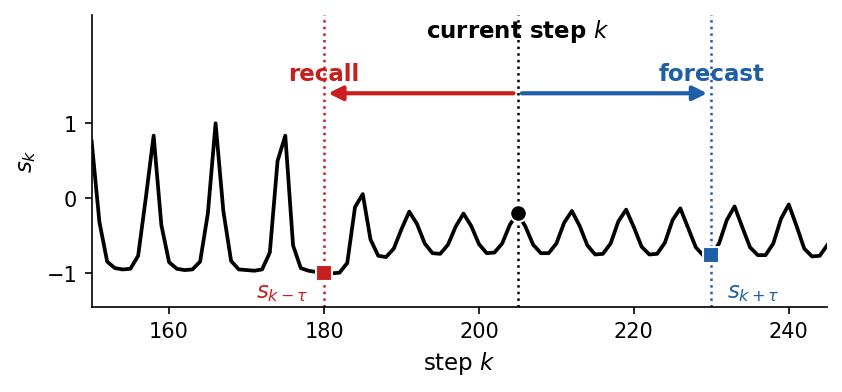

In [4]:
# a stretch of the Santa Fe record around a collapse, rescaled to [-1, 1] for the drawing only
seg = sf_full[150:246]
s_seg = 2 * (seg - seg.min()) / (seg.max() - seg.min()) - 1
k_seg = np.arange(150, 150 + len(seg))
K_NOW, TAU_DEMO = 205, 25                                 # current step k and the shift tau of the drawing
RED, BLUE = "#C81E1E", "#1F5FA8"                          # recall = red, forecast = blue
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.5), layout="constrained")
    ax.plot(k_seg, s_seg, color="k", lw=1.8, zorder=2)
    for x, col, mk in [(K_NOW, "k", "o"), (K_NOW - TAU_DEMO, RED, "s"), (K_NOW + TAU_DEMO, BLUE, "s")]:
        i = x - k_seg[0]
        ax.axvline(x, color=col, ls=":", lw=1.2, zorder=1)
        ax.plot(x, s_seg[i], mk, color=col, ms=8, mec="white", mew=1.0, zorder=4)
    ax.text(K_NOW, 2.05, "current step $k$", ha="center", va="bottom", fontsize=11, fontweight="bold")
    for x1, col, lab in [(K_NOW - TAU_DEMO, RED, "recall"), (K_NOW + TAU_DEMO, BLUE, "forecast")]:
        ax.annotate("", xy=(x1, 1.4), xytext=(K_NOW, 1.4),
                    arrowprops=dict(arrowstyle="-|>", lw=2.0, color=col, mutation_scale=14))
        ax.text(x1, 1.5, lab, color=col, ha="center", va="bottom", fontsize=11, fontweight="bold")
    ax.text(K_NOW - TAU_DEMO - 2, -1.25, r"$s_{k-\tau}$", color=RED, ha="right", va="center", fontsize=11)
    ax.text(K_NOW + TAU_DEMO + 2, -1.25, r"$s_{k+\tau}$", color=BLUE, ha="left", va="center", fontsize=11)
    ax.set_xlim(k_seg[0], k_seg[-1]); ax.set_ylim(-1.45, 2.45); ax.set_yticks([-1, 0, 1])
    ax.set_xlabel("step $k$"); ax.set_ylabel("$s_k$")
    save(fig, "fig_task_recall_forecast"); plt.show()

### Memory tasks

A memory task tests what a model keeps of its own input. The input $s_k$ is a sequence of independent random numbers, so no value can be inferred from the others, and the only way to output an old input is to have stored it. In the recall task on such an input the target is $y_k=s_{k-\tau}$. In the NARMA-$n$ task (nonlinear autoregressive moving average of order $n$, Atiya and Parlos 2000) a fixed nonlinear system driven by $s$ produces the target

$$
\begin{aligned}
y_k &= 0.3\,y_{k-1}+0.05\,y_{k-1}\sum_{i=1}^{n}y_{k-i}\\
&\quad+1.5\,s_{k-n}\,s_{k-1}+0.1,\qquad s_k\in[0,0.5].
\end{aligned}
$$

The model sees only $s$ and has to reproduce $y_k$ at every step. The product $s_{k-n}s_{k-1}$ needs a memory of $n$ steps and a nonlinear feature, and the terms $y_{k-1},\dots,y_{k-n}$ are built from still older inputs, so a larger $n$ gives a harder task. The figure shows one input sequence and its NARMA targets for $n=2,5,10$.

The two kinds of task are scored differently. A forecast is judged by the Pearson correlation $r$ between prediction and target and by the capacity $C=r^2$, which ask whether the forecast follows the shape of the signal. The recall task uses the same capacity $C(\tau)$, and its sum over $\tau$ is the memory capacity. NARMA asks for the values themselves, so it is scored by the normalised mean-square error

$$\mathrm{NMSE}=\frac{\sum_k (y_k-\hat y_k)^2}{\sum_k (y_k-\bar y)^2},$$

which is 0 for a perfect output and 1 for the constant output $\hat y_k=\bar y$.

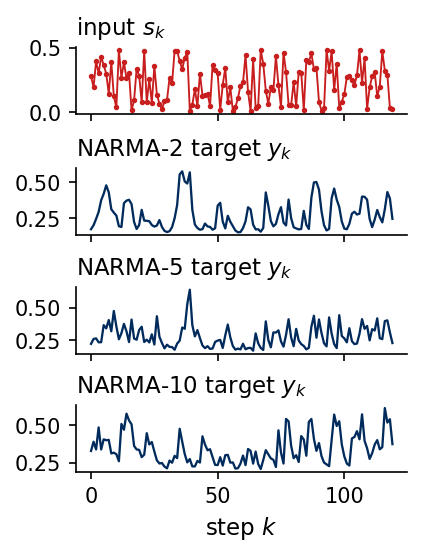

In [5]:
# memory tasks: independent random input s_k in [0, 0.5] and the NARMA-n targets driven by it
def narma(s, n):
    """NARMA-n target y driven by the input s (Atiya and Parlos 2000 form)."""
    y = np.zeros_like(s)
    for k in range(n, len(s)):
        y[k] = 0.3 * y[k-1] + 0.05 * y[k-1] * y[k-n:k].sum() + 1.5 * s[k-n] * s[k-1] + 0.1
    return y

rng_mem = np.random.default_rng(1)
s_mem = rng_mem.uniform(0, 0.5, 1200)
WASH, SHOW = 200, 120                                     # discarded transient, steps shown
k_show = np.arange(SHOW)
RED = "#C81E1E"
with mpl.rc_context(SLIDE_RC):
    # drawn for half the width of a slide, next to the text of the task
    fig, axs = plt.subplots(4, 1, figsize=(2.7, 3.6), sharex=True, layout="constrained")
    axs[0].plot(k_show, s_mem[WASH:WASH + SHOW], color=RED, lw=0.9, marker="o", ms=1.6)
    axs[0].set_title(r"input $s_k$", loc="left")
    for ax, n in zip(axs[1:], (2, 5, 10)):
        y_mem = narma(s_mem, n)
        assert np.all(np.isfinite(y_mem)) and y_mem.max() < 10, f"NARMA-{n} diverged"
        ax.plot(k_show, y_mem[WASH:WASH + SHOW], color=UJNavy, lw=1.1)
        ax.set_title(rf"NARMA-{n} target $y_k$", loc="left")
    for ax in axs:
        ax.locator_params(axis="y", nbins=2)
    axs[-1].set_xlabel("step $k$")
    save(fig, "fig_memory_tasks"); plt.show()


### Signals that are easy to forecast

Some signals can be forecast exactly once their rule is recognised. A constant is forecast by its last value (persistence). A periodic signal with period $P$ is forecast by the value one period earlier, $\hat s_{k+\tau}=s_{k+\tau-P}$ for $\tau\le P$. A quasi-periodic signal, a sum of sines whose frequencies have an irrational ratio, never repeats exactly. A sum of two sines nevertheless obeys an exact linear recurrence of order four, $s_k=\sum_{j=1}^{4}a_js_{k-j}$, because each sine $\sin(\omega k)$ satisfies $s_k=2\cos\omega\,s_{k-1}-s_{k-2}$. We fit the four coefficients by least squares on the past and iterate the recurrence. In the figure the past is black, the true continuation grey and the forecast dashed blue.

constant        max forecast error over 40 steps: 0.0e+00
periodic        max forecast error over 40 steps: 7.2e-15
quasi-periodic  max forecast error over 40 steps: 7.4e-12
fitted recurrence coefficients: [ 3.864533 -5.732744  3.864533 -1.      ]


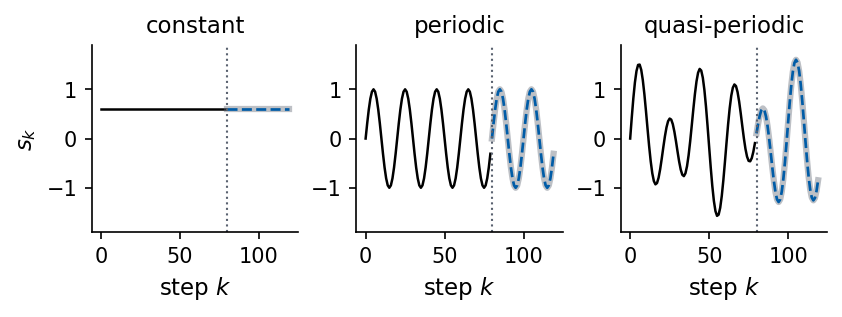

In [6]:
# three predictable signals: a constant, a periodic and a quasi-periodic one, each forecast from its past
k = np.arange(120); K0 = 80                                # the past is k < 80, the forecast covers k >= 80
P_DEMO = 20                                                # period of the periodic signal
GOLD = (1 + np.sqrt(5)) / 2                                # an irrational ratio of the two frequencies
sig_const = np.full(k.shape, 0.6)
sig_per = np.sin(2 * np.pi * k / P_DEMO)
sig_qp = np.sin(2 * np.pi * k / P_DEMO) + 0.6 * np.sin(2 * np.pi * k / (P_DEMO * GOLD))

fc_const = np.full(k.shape, sig_const[K0 - 1])             # persistence: the last value
fc_per = sig_per.copy()
for i in range(K0, len(k)):
    fc_per[i] = fc_per[i - P_DEMO]                          # repeat the value one period ago

# a sum of two sines obeys an exact linear recurrence of order 4; fit it on the past by least squares, then iterate
p = 4
X = np.stack([sig_qp[p - 1 - j:K0 - 1 - j] for j in range(p)], axis=1)
coef = np.linalg.lstsq(X, sig_qp[p:K0], rcond=None)[0]
fc_qp = sig_qp.copy()
for i in range(K0, len(k)):
    fc_qp[i] = coef @ fc_qp[i - 1:i - 1 - p:-1]
for name, s_, f_ in [("constant", sig_const, fc_const), ("periodic", sig_per, fc_per), ("quasi-periodic", sig_qp, fc_qp)]:
    print(f"{name:15s} max forecast error over 40 steps: {np.abs(s_[K0:] - f_[K0:]).max():.1e}")
print("fitted recurrence coefficients:", np.round(coef, 6))
nums["qp_coef"] = coef.tolist()
nums["trivial_err"] = {name: float(np.abs(s_[K0:] - f_[K0:]).max()) for name, s_, f_ in
                       [("constant", sig_const, fc_const), ("periodic", sig_per, fc_per), ("quasi-periodic", sig_qp, fc_qp)]}
nums["trivial_steps"] = int(len(k) - K0)

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.0), layout="constrained", sharex=True)
    for ax, s_, f_, title in zip(axs, (sig_const, sig_per, sig_qp), (fc_const, fc_per, fc_qp),
                                 ("constant", "periodic", "quasi-periodic")):
        ax.plot(k[:K0], s_[:K0], color="k", lw=1.2)
        ax.plot(k[K0:], s_[K0:], color=UJGray, lw=3.0, alpha=0.4)
        ax.plot(k[K0:], f_[K0:], "--", color=UJBlue, lw=1.3)
        ax.axvline(K0, color=UJGray, ls=":", lw=1.0)
        ax.set_title(title); ax.set_xlabel("step $k$"); ax.set_ylim(-1.9, 1.9)
    axs[0].set_ylabel("$s_k$")
    save(fig, "fig_trivial_signals"); plt.show()

All three forecasts are exact to round-off. Such signals are trivial forecasting tasks, and a useful benchmark must be harder. Two kinds of signals are hard for different reasons. A chaotic signal is produced by known deterministic equations, without any randomness, and still cannot be forecast far ahead because small errors grow exponentially (Sections 7 to 9). A stochastic signal is irregular because each new value contains a random part that no model can know in advance.

### Stochastic processes

A stochastic process is a family of random variables $s_k$ indexed by time. The simplest one is white noise, independent values $\varepsilon_k$ with zero mean and variance $\sigma^2$. Its best forecast is the mean, and no model can do better. Summing white noise gives the random walk $s_k=s_{k-1}+\varepsilon_k$, the discrete version of Brownian motion. Its variance grows as $k\sigma^2$, so it is not stationary, and its best forecast is the last value. The autoregressive process AR(1), $s_k=\phi s_{k-1}+\varepsilon_k$ with $|\phi|<1$, lies in between. It forgets its past at the rate $\phi$ per step, has the stationary variance $\sigma^2/(1-\phi^2)$, and its best forecast $\hat s_{k+\tau}=\phi^\tau s_k$ relaxes to the mean. It is the discrete form of the Ornstein–Uhlenbeck process, the velocity of a Brownian particle with friction. A process is (weakly) stationary when its mean and its covariances $\mathrm{cov}(s_k,s_{k+n})$ do not depend on $k$. The figure shows 20 realisations of each process (grey, one in blue) with $\sigma=1$ and $\phi=0.9$. The dashed lines are $\pm2$ standard deviations of the process, constant for white noise and AR(1) and growing as $2\sqrt{k}$ for the random walk.

random walk: ensemble std at k = 99 and 299: 8.4, 13.3 (sqrt(k+1) = 10.0, 17.3); 20 realisations only
AR(1) with phi = 0.9: stationary std 1/sqrt(1 - phi^2) = 2.29, sample std over all realisations 2.33


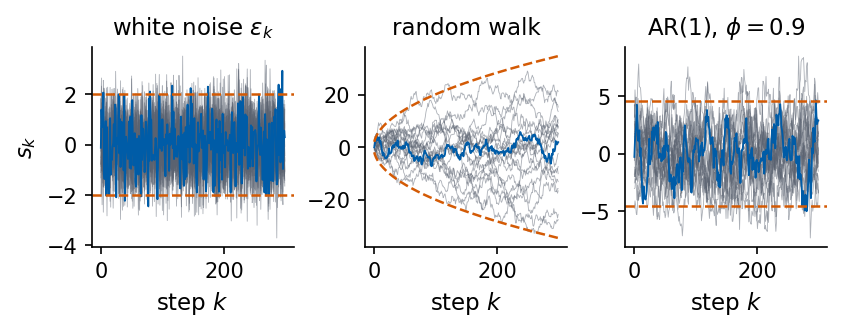

In [7]:
# three stochastic processes driven by independent Gaussian increments eps_k ~ N(0, 1)
PHI = 0.9                                                  # AR(1) coefficient
n_real, n_step = 20, 300
eps = np.asarray(jax.random.normal(jax.random.key(11), (n_real, n_step)))
white = eps
walk = np.cumsum(eps, axis=1)                              # s_k = s_{k-1} + eps_k, s_0 = eps_0
ar1 = np.zeros_like(eps)
ar1[:, 0] = eps[:, 0] / np.sqrt(1 - PHI**2)                # start in the stationary distribution
for i in range(1, n_step):
    ar1[:, i] = PHI * ar1[:, i - 1] + eps[:, i]
kk = np.arange(n_step)
print(f"random walk: ensemble std at k = 99 and 299: {walk[:, 99].std():.1f}, {walk[:, 299].std():.1f}"
      f" (sqrt(k+1) = {np.sqrt(100):.1f}, {np.sqrt(300):.1f}); 20 realisations only")
print(f"AR(1) with phi = {PHI}: stationary std 1/sqrt(1 - phi^2) = {1/np.sqrt(1 - PHI**2):.2f},"
      f" sample std over all realisations {ar1.std():.2f}")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.1), layout="constrained", sharex=True)
    for ax, data, title in zip(axs, (white, walk, ar1),
                               (r"white noise $\varepsilon_k$", "random walk", f"AR(1), $\\phi={PHI}$")):
        for r_ in range(1, n_real):
            ax.plot(kk, data[r_], color=UJGray, lw=0.4, alpha=0.5)
        ax.plot(kk, data[0], color=UJBlue, lw=0.9)
        ax.set_title(title); ax.set_xlabel("step $k$")
    axs[1].plot(kk, 2 * np.sqrt(kk + 1), "--", color=DSOrange, lw=1.2)
    axs[1].plot(kk, -2 * np.sqrt(kk + 1), "--", color=DSOrange, lw=1.2)
    for s_ in (+1, -1):
        axs[2].axhline(s_ * 2 / np.sqrt(1 - PHI**2), color=DSOrange, ls="--", lw=1.2)
        axs[0].axhline(s_ * 2, color=DSOrange, ls="--", lw=1.2)
    axs[0].set_ylabel("$s_k$")
    save(fig, "fig_stochastic_processes"); plt.show()

### Persistence and the conditional mean

The AR(1) process with a nonzero mean $\mu$, $s_k=\mu+\phi\,(s_{k-1}-\mu)+\varepsilon_k$, shows that the simplest forecast need not be the best one, even when it follows the target closely. Persistence repeats the last value, $\hat s_{k+1}=s_k$. The conditional mean $\hat s_{k+1}=\mu+\phi\,(s_k-\mu)$ is the expected next value given the past, and since $\varepsilon_{k+1}$ is independent of the past, no forecast can have a smaller mean squared error. Divided by the variance of the process, the normalised mean squared error (NMSE) of persistence is $2(1-\phi)$ and that of the conditional mean is $1-\phi^2$. Both forecasts are affine functions of $s_k$, so both have the same Pearson correlation $\phi$ with the target, and its square $r^2=\phi^2$ cannot tell them apart. We check the three numbers on a simulated record of $2\times10^5$ samples with $\phi=0.8$ and $\mu=3$.

In [8]:
# AR(1) with mean mu: persistence against the conditional mean, one step ahead
PHI_F, MU_F, N_F = 0.8, 3.0, 200_000

@partial(jax.jit, static_argnums=1)
def ar1_mean_series(key, n):
    """s_k = mu + phi (s_{k-1} - mu) + eps_k, eps ~ N(0, 1), started in the stationary distribution."""
    eps = jax.random.normal(key, (n,))
    x0 = MU_F + eps[0] / jnp.sqrt(1 - PHI_F**2)
    return jnp.concatenate([x0[None], jax.lax.scan(lambda x, e: (MU_F + PHI_F * (x - MU_F) + e,) * 2, x0, eps[1:])[1]])

s_f = np.asarray(ar1_mean_series(jax.random.key(13), N_F))
target_f, last_f = s_f[1:], s_f[:-1]
forecasts_f = {"persistence": last_f, "conditional mean": MU_F + PHI_F * (last_f - MU_F)}
theory_f = {"persistence": 2 * (1 - PHI_F), "conditional mean": 1 - PHI_F**2}
nums["ar1_forecast"] = {}
for name, f in forecasts_f.items():
    nmse = np.mean((target_f - f) ** 2) / np.var(target_f)
    r2 = np.corrcoef(f, target_f)[0, 1] ** 2
    nums["ar1_forecast"][name] = {"nmse": float(nmse), "r2": float(r2), "nmse_theory": theory_f[name]}
    print(f"{name:17s}: NMSE {nmse:.4f} (theory {theory_f[name]:.4f}), r^2 {r2:.4f} (phi^2 = {PHI_F**2:.2f})")

persistence      : NMSE 0.3993 (theory 0.4000), r^2 0.6406 (phi^2 = 0.64)
conditional mean : NMSE 0.3594 (theory 0.3600), r^2 0.6406 (phi^2 = 0.64)


Persistence has the NMSE 0.399 and the conditional mean 0.359, close to the theoretical values 0.40 and 0.36, while both forecasts have $r^2=0.641\approx\phi^2$. The difference of the errors is $(1-\phi)^2=0.04$ of the variance. Persistence follows every rise and fall of the target, and its error comes from overshooting, since it does not relax towards the mean. A score built on the correlation alone rewards the shape of a forecast, and the mean squared error also tests its level and amplitude.

### Memory and frequencies of the kinds of signals

Two statistics introduced in Sections 4 and 5 already separate these kinds of signals, the autocorrelation function (ACF) $\rho(n)$, which measures how strongly the signal remembers its value $n$ steps ago, and the power spectral density (PSD), which shows how its variance is distributed over frequencies. The figures show both in two rows. The top row holds three signals of known type, a periodic signal with period 20, white noise and AR(1) with $\phi=0.9$. The bottom row holds the three chaotic signals of this lab, Lorenz $x$, Mackey–Glass with $\tau_{\rm MG}=25$ and the Santa Fe laser, which are described in Section 3. Dashed lines are the exact results, $\rho(n)=\phi^n$ and $S(f)=2\sigma^2/|1-\phi e^{-2\pi if}|^2$ for AR(1) and the flat $S(f)=2\sigma^2$ for white noise (one-sided densities with unit sampling rate).

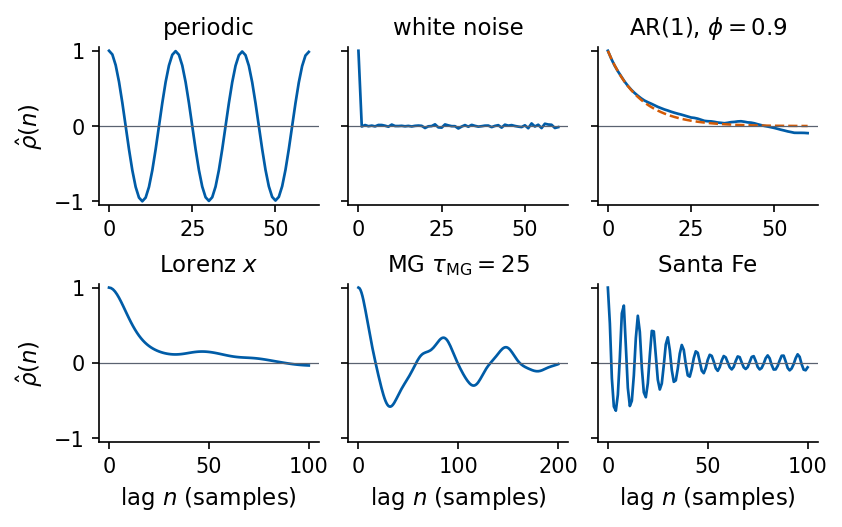

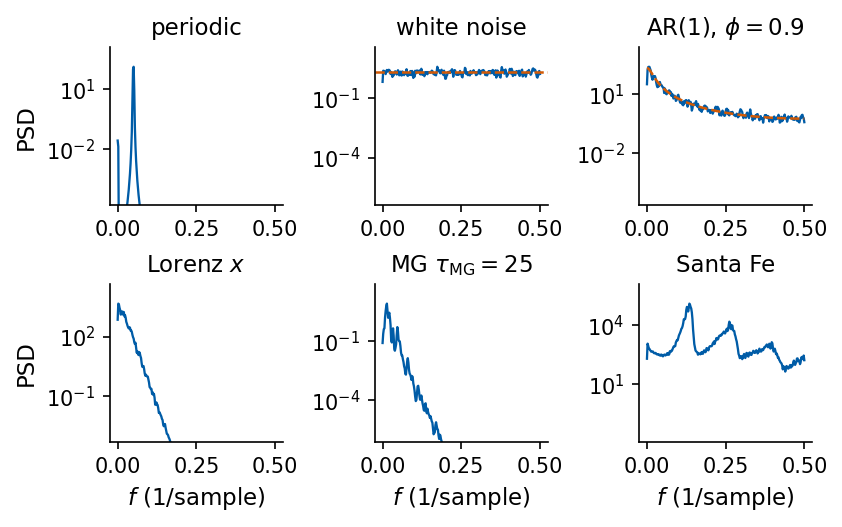

periodic signal: Welch peak at f = 0.0508 (1/P = 0.0500)


In [9]:
# ACF and power spectrum of three signals of known type and three chaotic signals, N = 4000 samples each
N_K = 4000
kinds = {"periodic": np.sin(2 * np.pi * np.arange(N_K) / P_DEMO),
         "white noise": np.asarray(jax.random.normal(jax.random.key(12), (N_K,)))}
e_ = np.asarray(jax.random.normal(jax.random.key(13), (N_K,)))
a_ = np.zeros(N_K); a_[0] = e_[0] / np.sqrt(1 - PHI**2)
for i in range(1, N_K):
    a_[i] = PHI * a_[i - 1] + e_[i]
kinds[f"AR(1), $\\phi={PHI}$"] = a_
chaotic = {"Lorenz $x$": S["lorenz"], LABEL["mg25"]: S["mg25"], "Santa Fe": S["santafe"]}
LAGS_CHAOS = {"Lorenz $x$": 100, LABEL["mg25"]: 200, "Santa Fe": 100}   # lags in samples, a few correlation times each

def acf_simple(x, n_lags):
    """rho_hat(n) = sum_k (x_k - m)(x_{k+n} - m) / sum_k (x_k - m)^2."""
    x = x - x.mean()
    return np.array([np.dot(x[:len(x) - n], x[n:]) for n in range(n_lags + 1)]) / np.dot(x, x)

# top row: signals of known type; bottom row: the chaotic signals of this lab
LAGS = 60
rows = [[(name, x, LAGS) for name, x in kinds.items()],
        [(name, x, LAGS_CHAOS[name]) for name, x in chaotic.items()]]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.4), layout="constrained", sharey=True)
    for ax_row, row in zip(axs, rows):
        for ax, (name, x, n_lag) in zip(ax_row, row):
            r_ = acf_simple(x, n_lag)
            ax.plot(np.arange(n_lag + 1), r_, color=UJBlue, lw=1.3)
            if name.startswith("AR"):
                ax.plot(np.arange(n_lag + 1), PHI ** np.arange(n_lag + 1), "--", color=DSOrange, lw=1.2)
            ax.axhline(0, color=UJGray, lw=0.6)
            ax.set_title(name)
    for ax in axs[1]:
        ax.set_xlabel("lag $n$ (samples)")
    for ax in axs[:, 0]:
        ax.set_ylabel(r"$\hat\rho(n)$")
    axs[0, 0].set_ylim(-1.05, 1.05)
    save(fig, "fig_kinds_acf"); plt.show()

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.4), layout="constrained")
    for ax_row, row in zip(axs, rows):
        for ax, (name, x, _) in zip(ax_row, row):
            f, P = scipy.signal.welch(x - x.mean(), fs=1.0, nperseg=512)
            ax.semilogy(f, P, color=UJBlue, lw=1.1)
            if name.startswith("AR"):        # exact one-sided PSD of AR(1): 2 / |1 - phi e^{-2 pi i f}|^2
                ax.semilogy(f, 2 / np.abs(1 - PHI * np.exp(-2j * np.pi * f))**2, "--", color=DSOrange, lw=1.2)
            if name == "white noise":
                ax.axhline(2.0, color=DSOrange, ls="--", lw=1.2)
            ax.set_ylim(P.max() * 1e-7, P.max() * 10)
            ax.set_title(name); ax.set_xticks([0, 0.25, 0.5])
    for ax in axs[1]:
        ax.set_xlabel("$f$ (1/sample)")
    for ax in axs[:, 0]:
        ax.set_ylabel("PSD")
    save(fig, "fig_kinds_psd"); plt.show()
f_qp, P_qp = scipy.signal.welch(kinds["periodic"], fs=1.0, nperseg=512)
print(f"periodic signal: Welch peak at f = {f_qp[np.argmax(P_qp)]:.4f} (1/P = {1/P_DEMO:.4f})")

The comparison uses six signals, shown below over their first 300 samples. The top row holds three signals whose type is known by construction, a sine wave with period 20, white noise and the AR(1) process with $\phi=0.9$. The bottom row holds the three chaotic signals of this notebook, the $x$ coordinate of Lorenz-63, Mackey–Glass with $\tau_{\rm MG}=25$ and the Santa Fe laser.

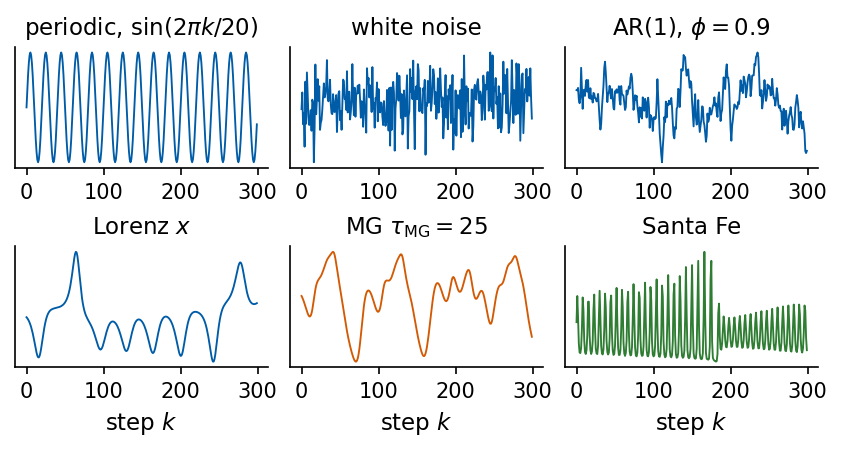

In [10]:
# the six test signals of the ACF and PSD comparison: three of known type (top) and the three chaotic signals (bottom)
six = [("periodic, $\\sin(2\\pi k/20)$", kinds["periodic"], UJBlue),
       ("white noise", kinds["white noise"], UJBlue),
       (f"AR(1), $\\phi={PHI}$", kinds[f"AR(1), $\\phi={PHI}$"], UJBlue),
       ("Lorenz $x$", S["lorenz"], COL["lorenz"]),
       (LABEL["mg25"], S["mg25"], COL["mg25"]),
       ("Santa Fe", S["santafe"], COL["santafe"])]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 2.9), layout="constrained")
    for ax, (name, x, col) in zip(axs.ravel(), six):
        ax.plot(np.arange(300), x[:300], color=col, lw=0.9)
        ax.set_title(name); ax.set_yticks([])
    for ax in axs[1]:
        ax.set_xlabel("step $k$")
    save(fig, "fig_six_signals"); plt.show()


The periodic signal keeps its correlation forever and puts its power into one line at $f=1/20$ (with leakage of the Welch window around it). White noise forgets immediately and has a flat spectrum. AR(1) forgets exponentially and has a smooth spectrum concentrated at low frequencies. Lorenz $x$ forgets more slowly than AR(1) and has a broad spectrum without sharp lines, so from the ACF and the PSD alone it resembles a coloured random process. Telling chaos apart from noise requires the tools of Sections 6 to 9 (and the surrogate test of Appendix A).

<hr/>
## 3. Physics of the three signals

### Lorenz-63 convection model

A horizontal fluid layer heated from below starts to convect when the temperature difference across it exceeds a threshold (Rayleigh–Bénard convection). Lorenz kept only the three lowest Fourier modes of the velocity and temperature fields and obtained [E. N. Lorenz, J. Atmos. Sci. **20**, 130 (1963), [doi:10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2](https://doi.org/10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2)]
$$
\dot x=\sigma(y-x),\qquad \dot y=x(\rho-z)-y,\qquad \dot z=xy-\beta z .
$$
Here $x$ measures the rate of convective circulation, $y$ the horizontal temperature difference between rising and sinking fluid, and $z$ the deviation of the vertical temperature profile from linear conduction. The Prandtl number $\sigma$ is the ratio of viscosity to thermal diffusivity, $\rho$ is the normalised Rayleigh number (the heating), and $\beta$ is a geometric factor of the convection rolls. We use the standard values $\sigma=10$, $\rho=28$, $\beta=8/3$, and we observe only $x(t)$, sampled every $\Delta t=0.02$ time units.

For $\rho>1$ the vector field $\mathbf F(\mathbf u)$, $\mathbf u=(x,y,z)$, has three fixed points $\mathbf F(\mathbf u^*)=0$, the conducting state at the origin and two states of steady convection $C_\pm=(\pm\sqrt{\beta(\rho-1)},\pm\sqrt{\beta(\rho-1)},\rho-1)$ with opposite senses of rotation. Their stability follows from the eigenvalues of the Jacobian $J_{ij}=\partial F_i/\partial u_j$ at the fixed point. A small perturbation grows along every eigenvector whose eigenvalue has a positive real part. We obtain $J$ with `jax.jacfwd` and locate numerically the value $\rho_c$ at which $C_\pm$ lose stability.

In [11]:
sigma, rho, beta = 10.0, 28.0, 8.0 / 3.0
jac_rhs = jax.jacfwd(lorenz_rhs)                     # Jacobian J = dF/du of the vector field, shape (3, 3)

def fixed_points(rho):
    c = np.sqrt(beta * (rho - 1.0))
    return {"origin": np.zeros(3), "C+": np.array([c, c, rho - 1.0]), "C-": np.array([-c, -c, rho - 1.0])}

for name, u in fixed_points(rho).items():
    assert np.allclose(lorenz_rhs(jnp.array(u)), 0.0, atol=1e-12)      # F(u*) = 0
    ev = np.linalg.eigvals(np.asarray(jac_rhs(jnp.array(u))))
    print(f"{name:7s} u* = {np.round(u, 3)}   eigenvalues of J: {np.round(np.sort_complex(ev), 3)}")

# the largest real part of the eigenvalues at C+ as a function of rho; its zero is the loss of stability
def max_re(r):
    u = fixed_points(r)["C+"]
    return np.linalg.eigvals(np.asarray(jax.jacfwd(lambda v: lorenz_rhs(v, rho=r))(jnp.array(u)))).real.max()
rho_c = scipy.optimize.brentq(max_re, 15.0, 28.0)
ev_c = np.linalg.eigvals(np.asarray(jac_rhs(jnp.array(fixed_points(rho)["C+"]))))
omega_c = np.abs(ev_c.imag).max()
nums["lorenz_rho_c"] = rho_c
nums["lorenz_Cplus_eig"] = [float(ev_c.real.min()), float(ev_c.real.max()), float(omega_c)]
nums["lorenz_div"] = -(sigma + 1 + beta)
nums["lorenz_origin_eig"] = np.sort(np.linalg.eigvals(np.asarray(jac_rhs(jnp.zeros(3)))).real).tolist()
nums["lorenz_turn_rate"] = float(omega_c / (2 * np.pi))          # turns per time unit around C+ or C-
print(f"C+ and C- lose stability at rho_c = {rho_c:.3f}")
print(f"at rho = 28: complex pair at C+ has Re = {ev_c.real.max():.4f}, Im = {omega_c:.4f}, "
      f"rotation frequency Im/(2 pi) = {omega_c/(2*np.pi):.4f} per time unit")
print(f"trace of J (= div F, the same at every point) = {np.trace(np.asarray(jac_rhs(jnp.array([1., 2., 3.])))):.4f}"
      f" ; -(sigma + 1 + beta) = {-(sigma + 1 + beta):.4f}")

origin  u* = [0. 0. 0.]   eigenvalues of J: [-22.828+0.j  -2.667+0.j  11.828+0.j]
C+      u* = [ 8.485  8.485 27.   ]   eigenvalues of J: [-13.855 +0.j      0.094-10.195j   0.094+10.195j]
C-      u* = [-8.485 -8.485 27.   ]   eigenvalues of J: [-13.855 +0.j      0.094-10.195j   0.094+10.195j]
C+ and C- lose stability at rho_c = 24.737
at rho = 28: complex pair at C+ has Re = 0.0940, Im = 10.1945, rotation frequency Im/(2 pi) = 1.6225 per time unit
trace of J (= div F, the same at every point) = -13.6667 ; -(sigma + 1 + beta) = -13.6667


At $\rho=28$ the origin has one unstable direction (eigenvalue 11.828), and $C_\pm$ have one strongly contracting direction (eigenvalue $-13.855$) and a complex pair $0.094\pm10.195\,i$. The trajectory therefore spirals outwards around $C_+$ or $C_-$ with angular frequency 10.19, which is $1.62$ rotations per time unit, until it is thrown over to the other lobe. Both convective states lose stability at $\rho_c=24.737$. The trace of $J$ equals $-(\sigma+1+\beta)=-13.667$ at every point, a fact we use in Section 7.

The left panel of the figure shows the attractor in the full state space with $C_\pm$ marked by dots, the right panel the observed coordinate $x(t)$ over 20 time units. The dashed lines are the values $\pm\sqrt{\beta(\rho-1)}$ of $x$ at $C_\pm$. The signal oscillates around one of them with growing amplitude and jumps irregularly to the other.

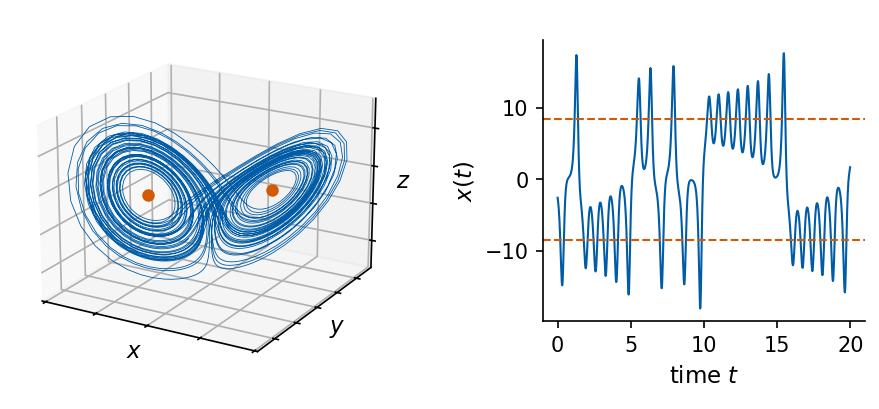

In [12]:
t_lor = np.arange(N_SAMPLES) * DT["lorenz"]
fp = fixed_points(rho)
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.6))
    ax = fig.add_axes([-0.04, 0.0, 0.46, 1.0], projection="3d")
    ax.plot(*lor_states[:2500].T, lw=0.4, color=UJBlue)
    for name in ("C+", "C-"):
        ax.scatter(*fp[name], color=DSOrange, s=25, zorder=5)
    ax.set_xlabel("$x$", labelpad=-12); ax.set_ylabel("$y$", labelpad=-12); ax.set_zlabel("$z$", labelpad=-12)
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([]); ax.view_init(elev=20, azim=-60)
    ax2 = fig.add_axes([0.6, 0.2, 0.39, 0.72])
    ax2.plot(t_lor[:1000], S["lorenz"][:1000], color=UJBlue, lw=1.0)
    for s_ in (+1, -1):
        ax2.axhline(s_ * np.sqrt(beta * (rho - 1)), color=DSOrange, ls="--", lw=1.0)
    ax2.set_xlabel("time $t$"); ax2.set_ylabel("$x(t)$")
    save(fig, "fig_lorenz_attractor"); plt.show()

### Mackey–Glass delay equation

Mackey and Glass modelled the concentration $x(t)$ of circulating blood cells, whose production is regulated by the concentration at an earlier time, because new cells need a maturation time $\tau_{\rm MG}$ [M. C. Mackey and L. Glass, Science **197**, 287 (1977), [doi:10.1126/science.267326](https://doi.org/10.1126/science.267326)],
$$
\dot x(t)=\frac{\beta\,x(t-\tau_{\rm MG})}{1+x(t-\tau_{\rm MG})^{n}}-\gamma\,x(t).
$$
The cells decay at rate $\gamma$, and the production term grows for small delayed concentration and is suppressed for large delayed concentration, with sharpness set by $n$. We use $\beta=0.2$ (unrelated to the Lorenz $\beta$), $\gamma=0.1$, $n=10$ and vary only the delay. To integrate the equation from time $t$ onwards we need the whole history $x(t')$ for $t'\in[t-\tau_{\rm MG},t]$, so the state of the system is a function on an interval and the state space is infinite-dimensional. The RK4 scheme with step $h=0.1$ stores this history as the vector $(x_{i-L},\dots,x_i)$ of length $L+1$ with $L=\tau_{\rm MG}/h$, the delay window in the generator code. As the delay grows, the fixed point loses stability in a Hopf bifurcation to a limit cycle, and at larger delays the motion becomes chaotic. We use $\tau_{\rm MG}=15$, 25 and 35, which give a limit cycle and two chaotic signals. Section 9 shows that the attractor at 35 has the higher dimension, while nearby states separate faster at 25, so a longer delay does not make the signal less predictable. The signal is sampled once per time unit.

The upper row of the figure shows 600 samples of each signal and the lower row the plane $(x(t-\tau_{\rm MG}),x(t))$. For $\tau_{\rm MG}=15$ the curve closes after two loops of different size, and for $\tau_{\rm MG}=25$ and 35 it fills a band that becomes wider with the delay.

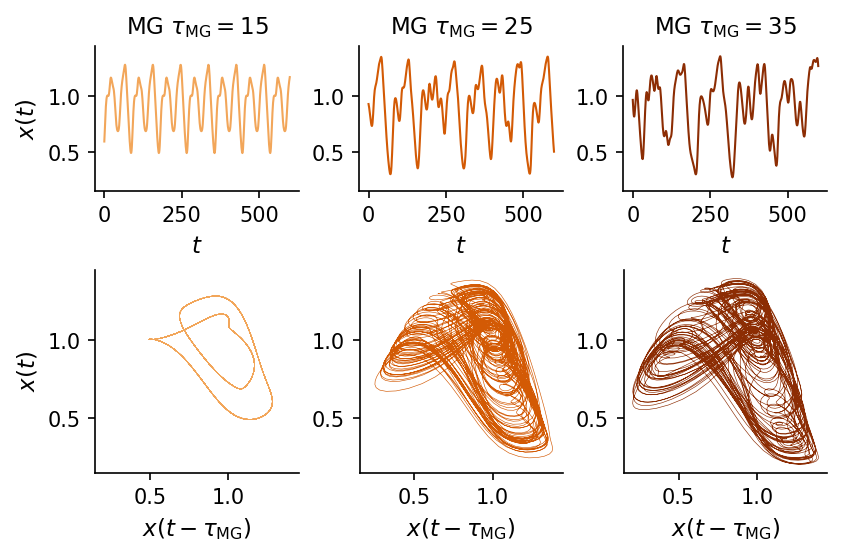

In [13]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.6), layout="constrained",
                            gridspec_kw=dict(height_ratios=[1, 1.4]))
    for c, (k, tau) in enumerate([("mg15", 15), ("mg25", 25), ("mg35", 35)]):
        x = S[k]
        axs[0, c].plot(np.arange(600), x[:600], color=COL[k], lw=1.0)
        axs[0, c].set_title(LABEL[k]); axs[0, c].set_xlabel("$t$"); axs[0, c].set_ylim(0.15, 1.45)
        axs[1, c].plot(x[:-tau], x[tau:], color=COL[k], lw=0.3)     # unit sampling, so the delay is tau samples
        axs[1, c].set_xlabel(r"$x(t-\tau_{\rm MG})$"); axs[1, c].set_aspect("equal")
        axs[1, c].set_xlim(0.15, 1.45); axs[1, c].set_ylim(0.15, 1.45)
    axs[0, 0].set_ylabel("$x(t)$"); axs[1, 0].set_ylabel("$x(t)$")
    save(fig, "fig_mackey_glass_taus"); plt.show()

The lower panels plot $x(t-\tau_{\rm MG})$ against $x(t)$, a two-dimensional projection of the orbit in which the delay of the plot equals the delay of the equation. For $\tau_{\rm MG}=15$ the orbit is a limit cycle, a closed curve that the signal traces again in every period, and its projection is a single closed line. The state of a delay equation is not a point but the whole history $x(s)$ for $t-\tau_{\rm MG}\le s\le t$, so its phase space has infinitely many dimensions, and a longer delay leaves room for more active directions. For $\tau_{\rm MG}=25$ and $35$ the orbit is chaotic and never closes. Its attractor has the Kaplan–Yorke dimensions 3.16 and 3.41 computed in Section 9, larger than 2, and a set of dimension larger than 2 projected onto a plane covers an area. Successive loops pass close to each other without coinciding, and together they fill a band that looks like a surface. The growth of the attractor dimension with the delay was found by Farmer [J. D. Farmer, Physica D **4**, 366 (1982), [doi:10.1016/0167-2789(82)90042-2](https://doi.org/10.1016/0167-2789(82)90042-2)].

The kinds of attractor, the sets on which the motion settles after a transient, are easiest to see in three systems. A damped pendulum loses energy and comes to rest, so its attractor is a fixed point. The Van der Pol oscillator $\ddot x=(1-x^2)\dot x-x$ pumps energy in at small amplitude and removes it at large amplitude. Orbits started inside and outside (grey) both end on the same closed curve (orange), a limit cycle, which the motion traces once per period. Lorenz-63 settles on a strange attractor. It is strange in two senses. The motion on it is chaotic, the orbit never closes and nearby orbits separate, and the set itself is a fractal, a sheet folded over and over with a dimension that is not a whole number.

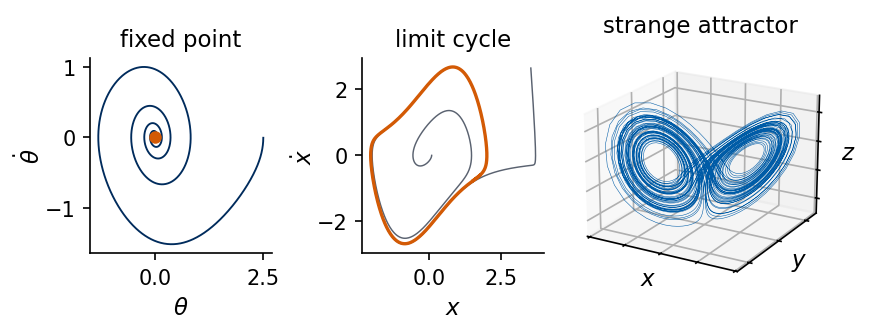

In [14]:
# three kinds of attractor: fixed point (damped pendulum), limit cycle (Van der Pol oscillator), strange attractor (Lorenz-63)
def rk4_orbit(f, u0, dt, n):
    """RK4 orbit of u' = f(u) from u0; returns n states."""
    u = np.array(u0, float); out = np.empty((n, len(u)))
    for i in range(n):
        k1 = f(u); k2 = f(u + 0.5 * dt * k1); k3 = f(u + 0.5 * dt * k2); k4 = f(u + dt * k3)
        u = u + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4); out[i] = u
    return out
pendulum = lambda u: np.array([u[1], -np.sin(u[0]) - 0.25 * u[1]])        # theta'' = -sin(theta) - 0.25 theta'
van_der_pol = lambda u: np.array([u[1], (1 - u[0]**2) * u[1] - u[0]])     # x'' = (1 - x^2) x' - x
pend = rk4_orbit(pendulum, [2.5, 0.0], 0.01, 6000)
vdp_in, vdp_out = rk4_orbit(van_der_pol, [0.1, 0.0], 0.01, 4000), rk4_orbit(van_der_pol, [3.5, 3.0], 0.01, 4000)
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.0))
    ax1 = fig.add_axes([0.10, 0.22, 0.22, 0.65])
    ax1.plot(pend[:, 0], pend[:, 1], color=UJNavy, lw=0.9)
    ax1.plot(0, 0, "o", color=DSOrange, ms=5)
    ax1.set_xlabel(r"$\theta$"); ax1.set_ylabel(r"$\dot\theta$", labelpad=0); ax1.set_title("fixed point")
    ax2 = fig.add_axes([0.43, 0.22, 0.22, 0.65])
    ax2.plot(*vdp_in.T, color=UJGray, lw=0.7); ax2.plot(*vdp_out.T, color=UJGray, lw=0.7)
    ax2.plot(*vdp_in[-700:].T, color=DSOrange, lw=1.6)                     # the last period: the cycle itself
    ax2.set_xlabel("$x$"); ax2.set_ylabel(r"$\dot x$", labelpad=0); ax2.set_title("limit cycle")
    ax3 = fig.add_axes([0.68, 0.0, 0.32, 1.0], projection="3d")
    ax3.plot(*lor_states[:3000].T, lw=0.25, color=UJBlue)
    ax3.set_title("strange attractor", pad=-2)
    ax3.set_xticklabels([]); ax3.set_yticklabels([]); ax3.set_zticklabels([])
    for setter, lab in zip((ax3.set_xlabel, ax3.set_ylabel, ax3.set_zlabel), ("$x$", "$y$", "$z$")):
        setter(lab, labelpad=-12)
    ax3.view_init(elev=20, azim=-60)
    save(fig, "fig_attractor_types"); plt.show()


The fixed point of the damped pendulum $\ddot\theta=-\sin\theta-\gamma\dot\theta$ attracts the nearby states, and the Jacobian of its vector field $\mathbf F(\theta,\dot\theta)=(\dot\theta,\,-\sin\theta-\gamma\dot\theta)$ shows how. At a rest state $\theta^*$ the Jacobian is
$$
J=\begin{pmatrix}0&1\\-\cos\theta^*&-\gamma\end{pmatrix},
$$
and a small deviation evolves as $e^{\mu t}$ with $\mu$ an eigenvalue of $J$, a root of $\mu^2+\gamma\mu+\cos\theta^*=0$. We compute the eigenvalues with `jax.jacfwd` at the hanging position $\theta^*=0$ and the upright position $\theta^*=\pi$, for $\gamma=0.2$. The figure above uses $\gamma=0.25$, and the conclusions hold for every $0<\gamma<2$.

In [15]:
# linear stability of the two rest states of the damped pendulum
GAMMA_P = 0.2
pend_field = lambda u: jnp.array([u[1], -jnp.sin(u[0]) - GAMMA_P * u[1]])
PEND_EIG = {}
for name, th in (("hanging", 0.0), ("upright", np.pi)):
    PEND_EIG[name] = np.linalg.eigvals(np.asarray(jax.jacfwd(pend_field)(jnp.array([th, 0.0]))))
    print(f"{name:8s} theta* = {th:.4f}: eigenvalues of J {np.round(np.sort_complex(PEND_EIG[name]), 4)}")
print(f"closed form at the hanging position: -gamma/2 +- i sqrt(1 - gamma^2/4) = {-GAMMA_P/2:.4f} +- {np.sqrt(1 - GAMMA_P**2/4):.4f} i;"
      f" the amplitude falls by the factor e in 2/gamma = {2/GAMMA_P:.0f} time units")
nums["pendulum_eig"] = {k: [[float(z.real), float(z.imag)] for z in v] for k, v in PEND_EIG.items()}

hanging  theta* = 0.0000: eigenvalues of J [-0.1-0.995j -0.1+0.995j]
upright  theta* = 3.1416: eigenvalues of J [-1.105+0.j  0.905+0.j]
closed form at the hanging position: -gamma/2 +- i sqrt(1 - gamma^2/4) = -0.1000 +- 0.9950 i; the amplitude falls by the factor e in 2/gamma = 10 time units


At the hanging position the eigenvalues are the complex pair $-0.1\pm0.995\,i$. The imaginary part is the angular frequency of the swing, hardly changed by the friction, and the negative real part makes the amplitude fall as $e^{-\gamma t/2}$, by the factor $e$ in $2/\gamma=10$ time units. The deviation circles the rest state while it shrinks, a stable spiral, the fixed point of the figure. At the upright position the eigenvalues are real with opposite signs, $0.905$ and $-1.105$, so a deviation grows along one direction and decays along the other, a saddle, the balanced pendulum that falls at the slightest disturbance.

### Santa Fe laser data

The third signal is measured. It is the output intensity of a far-infrared ammonia (NH$_3$) laser in a regime of chaotic pulsations, data set A of the Santa Fe Institute time-series competition. The chaotic pulsations of this laser are described by Hübner, Abraham and Weiss [U. Hübner, N. B. Abraham and C. O. Weiss, Phys. Rev. A **40**, 6354 (1989), [doi:10.1103/PhysRevA.40.6354](https://doi.org/10.1103/PhysRevA.40.6354)]. A single-mode laser is described semiclassically by the Maxwell–Bloch equations for the cavity field $E$, the polarisation $P$ of the medium and the population inversion $D$,
$$
\dot E=-\gamma_c(E-gP),\qquad \dot P=-\gamma_\perp(P-ED),\qquad \dot D=-\gamma_\parallel(D-D_0+EP),
$$
with cavity decay rate $\gamma_c$, polarisation decay rate $\gamma_\perp$, inversion relaxation rate $\gamma_\parallel$, coupling $g$ and pump $D_0$. After a linear rescaling these equations have the algebraic form of Lorenz-63. In most lasers the three rates differ by orders of magnitude, the fast variables follow the slow ones, and the dynamics reduce to one or two dimensions where chaos cannot occur. In the NH$_3$ laser the three rates are comparable, all three variables stay active, and chaotic pulsations appear as the pump is raised. The detector measures the intensity $I\propto E^2$, one scalar projection of the three-dimensional state.

The data are integers, recorded by an 8-bit converter, and the measurement noise and the finite resolution are part of the signal. We characterise the first 4000 of the 10093 samples. The sampling interval is one sample, and we quote all times in samples.

all samples integer: True; range 0 .. 255; distinct values 243 of 256 possible 8-bit levels


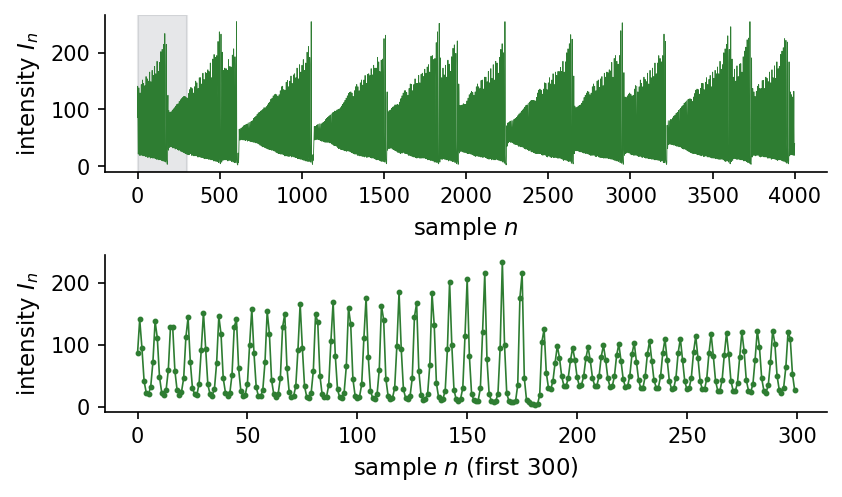

In [16]:
sf = S["santafe"]
is_int = np.all(sf_full == np.round(sf_full))
print(f"all samples integer: {is_int}; range {sf_full.min():.0f} .. {sf_full.max():.0f}; "
      f"distinct values {len(np.unique(sf_full))} of 256 possible 8-bit levels")
nums["santafe_len_full"] = int(len(sf_full))
nums["santafe_distinct_levels"] = int(len(np.unique(sf_full)))
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 3.2), layout="constrained")
    axs[0].plot(np.arange(N_SAMPLES), sf, color=COL["santafe"], lw=0.4)
    axs[0].axvspan(0, 300, color=UJGray, alpha=0.15)
    axs[0].set_ylabel("intensity $I_n$"); axs[0].set_xlabel("sample $n$")
    axs[1].plot(np.arange(300), sf[:300], "-o", color=COL["santafe"], lw=0.8, ms=1.8)
    axs[1].set_ylabel("intensity $I_n$"); axs[1].set_xlabel("sample $n$ (first 300)")
    save(fig, "fig_santafe_trace"); plt.show()

All 10093 values are integers between 0 and 255 and 243 of the 256 levels occur. The zoom (lower panel, the shaded part of the upper one) shows the characteristic cycle. The pulsations grow slowly over about 20 periods while the pump rebuilds the inversion, the field then depletes the inversion and the pulsation collapses within a few samples, after which the build-up starts again.

The figure below collects the five signals on a common scale. Each is rescaled to $[0,1]$ with the minimum and maximum of its training block, and the dotted and dashed lines mark the ends of the training part (sample 2500) and of the validation part (sample 3000). The table lists the sampling interval $\Delta t$, the duration $N\Delta t$ of the record, the Nyquist frequency $f_{\rm Ny}=1/(2\Delta t)$ (the highest frequency a sampled signal can represent) and the frequency resolution $1/(N\Delta t)$. Lorenz times are in model time units and Mackey–Glass times in the units of the equation.

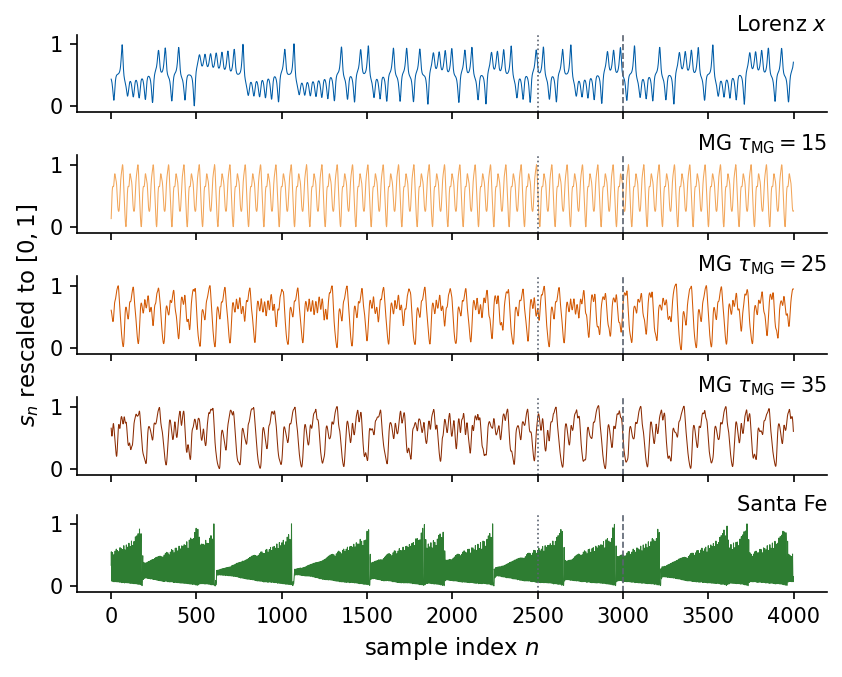

,sampling interval,record length (time),Nyquist frequency,resolution 1/(N dt),unit
signal,,,,,
Lorenz $x$,0.02,80.0,25.0,0.01250,time unit
MG $\tau_{\rm MG}=15$,1.00,4000.0,0.5,0.00025,time unit
MG $\tau_{\rm MG}=25$,1.00,4000.0,0.5,0.00025,time unit
MG $\tau_{\rm MG}=35$,1.00,4000.0,0.5,0.00025,time unit
Santa Fe,1.00,4000.0,0.5,0.00025,sample


In [17]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(5, 1, figsize=(5.5, 4.4), sharex=True, layout="constrained")
    for ax, k in zip(axs, KEYS):
        ax.plot(np.arange(N_SAMPLES), rescale01(S[k]), color=COL[k], lw=0.5)
        ax.axvline(N_TRAIN - N_VAL, color=UJGray, lw=0.8, ls=":"); ax.axvline(N_TRAIN, color=UJGray, lw=0.8, ls="--")
        ax.set_yticks([0, 1]); ax.set_ylim(-0.1, 1.15)
        ax.text(1.0, 1.0, LABEL[k], transform=ax.transAxes, ha="right", va="bottom", fontsize=10)
    axs[2].set_ylabel(r"$s_n$ rescaled to $[0,1]$")
    axs[-1].set_xlabel("sample index $n$")
    save(fig, "fig_signals_overview"); plt.show()

rows = []
for k in KEYS:
    dt = DT[k]
    rows.append({"signal": LABEL[k], "sampling interval": dt, "record length (time)": N_SAMPLES * dt,
                 "Nyquist frequency": 1 / (2 * dt), "resolution 1/(N dt)": 1 / (N_SAMPLES * dt), "unit": UNIT[k]})
display(pd.DataFrame(rows).set_index("signal"))

<hr/>
## 4. Autocorrelation function

All linear statistics assume that the signal is **stationary**, which means that its statistical properties do not depend on the origin of time. The mean $\mu=\langle s(t)\rangle$ is constant and the autocovariance
$$
R(\tau)=\big\langle\,(s(t)-\mu)\,(s(t+\tau)-\mu)\,\big\rangle
$$
depends only on the lag $\tau$, with $R(-\tau)=R(\tau)$. The brackets denote an average over an ensemble of realisations of the process. The autocorrelation function (ACF) is the normalised autocovariance $\rho(\tau)=R(\tau)/R(0)$, with $\rho(0)=1$ and $|\rho(\tau)|\le1$.

From one record of $N$ samples we can only form time averages. The standard estimator at lag $k$ (in samples) is
$$
\hat\rho(k)=\frac{\sum_{n=1}^{N-k}(s_n-\bar s)(s_{n+k}-\bar s)}{\sum_{n=1}^{N}(s_n-\bar s)^2},\qquad \bar s=\frac1N\sum_{n=1}^N s_n .
$$
Replacing the ensemble average by a time average assumes ergodicity, that one long record visits all states with their ensemble weights. Our signals are stationary after the discarded transients, and the Santa Fe record is treated as stationary although its slow build-up cycles make 4000 samples a short record. The numerator divides by $N$ and runs over $N-k$ terms, so $\hat\rho$ is biased towards zero at large $k$. In return it is a positive-definite sequence, which makes it the Fourier partner of the periodogram in Section 5.

The JAX implementation below computes all lags at once with `jax.vmap`, and we compare it with `statsmodels.tsa.stattools.acf` with the same normalisation (`adjusted=False`).

In [18]:
@partial(jax.jit, static_argnums=1)
def acf_jax(x, max_lag):
    """rho_hat(k) = sum_{n<N-k} (x_n - xbar)(x_{n+k} - xbar) / sum_n (x_n - xbar)^2,  k = 0..max_lag."""
    x = x - x.mean()
    N = x.shape[0]
    n = jnp.arange(N)
    def num(k):
        # x_n x_{n+k}, with the wrapped-around terms (n >= N-k) masked out
        return jnp.sum(jnp.where(n < N - k, x * jnp.roll(x, -k), 0.0))
    return jax.vmap(num)(jnp.arange(max_lag + 1)) / jnp.dot(x, x)

MAX_LAG = 400
RHO = {k: np.asarray(acf_jax(jnp.asarray(S[k]), MAX_LAG)) for k in KEYS}
for k in KEYS:
    ref = sm_acf(S[k], nlags=MAX_LAG, adjusted=False, fft=False)
    print(f"{LABEL[k]:22s} max |rho_JAX - rho_statsmodels| = {np.abs(RHO[k] - ref).max():.2e}")
    assert np.abs(RHO[k] - ref).max() < 1e-10

Lorenz $x$             max |rho_JAX - rho_statsmodels| = 2.22e-16
MG $\tau_{\rm MG}=15$  max |rho_JAX - rho_statsmodels| = 5.55e-16
MG $\tau_{\rm MG}=25$  max |rho_JAX - rho_statsmodels| = 3.33e-16
MG $\tau_{\rm MG}=35$  max |rho_JAX - rho_statsmodels| = 3.33e-16
Santa Fe               max |rho_JAX - rho_statsmodels| = 2.22e-16


Both implementations agree to machine precision. A single number for the memory of a signal, the correlation time, has several definitions that agree only for a simple exponential decay. We compute the first zero crossing of $\hat\rho$, the first lag at which $\hat\rho<1/e$, and, for oscillating ACFs, the first lag at which the envelope (the sequence of local maxima of $\hat\rho$) falls below $1/e$.

Lorenz $x$             first zero   89 samples =    1.78 time units | 1/e   15 samples =    0.30 time units | envelope 1/e   47 samples =    0.94 time units
MG $\tau_{\rm MG}=15$  first zero   11 samples =   11.00 time units | 1/e    9 samples =    9.00 time units | envelope 1/e none
MG $\tau_{\rm MG}=25$  first zero   18 samples =   18.00 time units | 1/e   12 samples =   12.00 time units | envelope 1/e   85 samples =   85.00 time units
MG $\tau_{\rm MG}=35$  first zero   24 samples =   24.00 time units | 1/e   15 samples =   15.00 time units | envelope 1/e  174 samples =  174.00 time units
Santa Fe               first zero    2 samples =    2.00 samples | 1/e    2 samples =    2.00 samples | envelope 1/e   30 samples =   30.00 samples


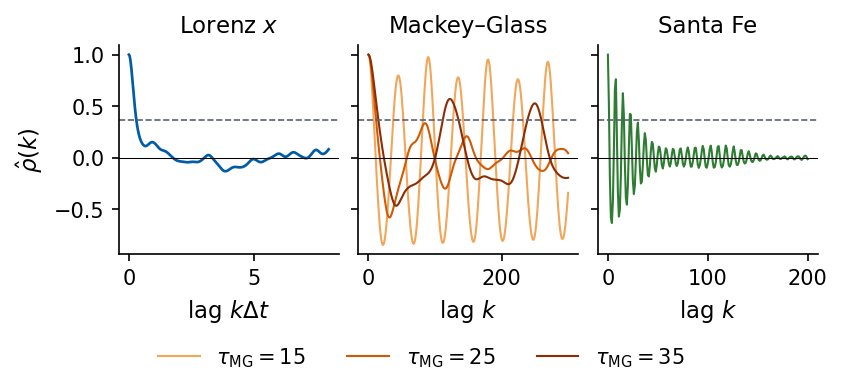

In [19]:
def correlation_times(rho):
    """First zero crossing, first drop below 1/e, and the lag where the envelope (the local maxima of rho)
    first falls below 1/e. All in samples; None if not reached within the computed lags."""
    zero = int(np.argmax(rho <= 0)) if np.any(rho <= 0) else None
    e1 = int(np.argmax(rho < np.exp(-1))) if np.any(rho < np.exp(-1)) else None
    pk, _ = scipy.signal.find_peaks(rho)
    below = pk[rho[pk] < np.exp(-1)]
    env = int(below[0]) if len(below) else None
    return zero, e1, env

CT = {}
for k in KEYS:
    CT[k] = correlation_times(RHO[k])
    z, e, env = CT[k]
    fmt = lambda v: "none" if v is None else f"{v:4d} samples = {v*DT[k]:7.2f} {UNIT[k]}s"
    print(f"{LABEL[k]:22s} first zero {fmt(z)} | 1/e {fmt(e)} | envelope 1/e {fmt(env)}")
nums["corr_times_samples"] = {k: list(CT[k]) for k in KEYS}

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.5), layout="constrained", sharey=True)
    lags = np.arange(MAX_LAG + 1)
    axs[0].plot(lags * DT["lorenz"], RHO["lorenz"], color=COL["lorenz"])
    axs[0].set_xlabel(r"lag $k\Delta t$"); axs[0].set_title(LABEL["lorenz"])
    for k in ("mg15", "mg25", "mg35"):
        axs[1].plot(lags[:301], RHO[k][:301], color=COL[k], label=k[2:], lw=1.0)
    axs[1].set_xlabel("lag $k$"); axs[1].set_title("Mackey–Glass")
    axs[2].plot(lags[:201], RHO["santafe"][:201], color=COL["santafe"], lw=1.0)
    axs[2].set_xlabel("lag $k$"); axs[2].set_title(LABEL["santafe"])
    for ax in axs:
        ax.axhline(0, color="k", lw=0.5); ax.axhline(np.exp(-1), color=UJGray, lw=0.8, ls="--")
    axs[0].set_ylabel(r"$\hat\rho(k)$")
    h, l = axs[1].get_legend_handles_labels()
    fig.legend(h, [r"$\tau_{\rm MG}=$" + s for s in l], loc="outside lower center", ncol=3, fontsize=10)
    save(fig, "fig_acf_signals"); plt.show()

The three definitions measure different things. For Lorenz $x$, $\hat\rho$ drops below $1/e$ after 15 samples (0.30 time units) but crosses zero only after 89 samples (1.78 time units), because the sign of $x$, the lobe, is remembered much longer than the phase of the rotation around $C_\pm$. The Mackey–Glass ACF oscillates. For $\tau_{\rm MG}=15$ the oscillation does not decay at all (the envelope never falls below $1/e$), which is the signature of a periodic signal. For $\tau_{\rm MG}=25$ and 35 the envelope reaches $1/e$ after 85 and 174 samples, so the chaotic signals forget their phase slowly. The Santa Fe ACF oscillates with the pulsation period, crosses zero after 2 samples, and its envelope decays to $1/e$ after 30 samples. In each panel the dashed line marks $1/e$.

<hr/>
## 5. Power spectrum

### Discrete Fourier transform and periodogram

The ACF tells us how long a signal remembers, the power spectral density (PSD) tells us at which frequencies its variance sits. For a stationary signal the two are a Fourier pair (Wiener–Khinchin theorem, see the textbook of H. Kantz and T. Schreiber, *Nonlinear Time Series Analysis*, 2nd ed., Cambridge University Press, 2003),
$$
S(f)=\int_{-\infty}^{\infty}R(\tau)\,e^{-2\pi i f\tau}\,d\tau,\qquad
R(\tau)=\int_{-\infty}^{\infty}S(f)\,e^{2\pi i f\tau}\,df ,
$$
and at $\tau=0$ the second relation states that the total power equals the variance, $\int S(f)\,df=R(0)$.

For $N$ samples at spacing $\Delta t$ the discrete Fourier transform (DFT) of the demeaned series is
$$
X_q=\sum_{n=0}^{N-1}(s_n-\bar s)\,e^{-2\pi i qn/N},\qquad f_q=\frac{q}{N\Delta t},\quad q=0,1,\dots,N-1 ,
$$
computed by the fast Fourier transform (FFT) in $O(N\log N)$ operations. The frequencies are spaced by the resolution $\Delta f=1/(N\Delta t)$, and only $|f_q|\le f_{\rm Ny}=1/(2\Delta t)$ is meaningful because $q$ and $q-N$ describe the same sampled oscillation. A component above $f_{\rm Ny}$ would appear at a wrong, lower frequency (aliasing). The periodogram
$$
\hat S(f_q)=\frac{\Delta t}{N}\,|X_q|^2
$$
estimates the two-sided density. Real signals have $X_{-q}=X_q^*$, so we keep $f_q\ge0$ and double all bins except $f=0$ and $f_{\rm Ny}$ (the one-sided PSD). With this normalisation Parseval's theorem gives the discrete sum rule $\sum_q\hat S(f_q)\,\Delta f=\frac1N\sum_n(s_n-\bar s)^2$, the variance of the record. The unit of $\hat S$ is (unit of $s$)$^2$ per unit of frequency, and frequencies are in cycles per time unit for Lorenz and Mackey–Glass and in cycles per sample for Santa Fe.

We implement the periodogram with `jnp.fft.rfft`, compare it with `scipy.signal.periodogram` and check the sum rule.

The idea of the spectrum is shown first on a signal whose content we know. Two sine waves with frequencies $f_1=0.05$ and $f_2=0.15$ per sample and amplitudes 1 and 0.5 are added, together with a little white noise. The periodogram of the sum has a sharp peak at each of the two frequencies, with heights in the ratio of the squared amplitudes, $1:0.25$, on top of a flat floor that comes from the noise. The spectrum takes the measured signal apart into the oscillations it contains and tells how much variance each one carries. The record has 2000 samples, so both frequencies lie exactly on the grid $f_q=q/N$ of the discrete Fourier transform and no power leaks into neighbouring frequencies.

peak height ratio S(f2)/S(f1) = 0.238 (squared amplitude ratio 0.250)


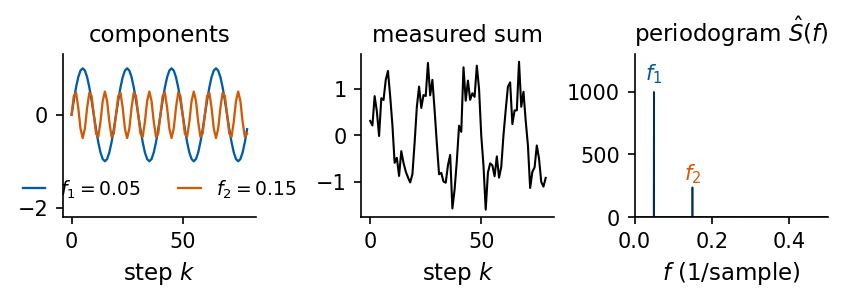

In [20]:
# sketch of the power spectrum: two sine components, their noisy sum, and the periodogram of the sum
N_SK, F1, F2, A1, A2 = 2000, 0.05, 0.15, 1.0, 0.5           # f * N integer: both lines fall on the frequency grid
k_sk = np.arange(N_SK)
comp1, comp2 = A1 * np.sin(2 * np.pi * F1 * k_sk), A2 * np.sin(2 * np.pi * F2 * k_sk)
s_sk = comp1 + comp2 + 0.3 * np.asarray(jax.random.normal(jax.random.key(7), (N_SK,)))
f_sk = np.fft.rfftfreq(N_SK, 1.0)[1:]
P_sk = (2.0 / N_SK) * np.abs(np.fft.rfft(s_sk - s_sk.mean()))[1:] ** 2      # one-sided periodogram, dt = 1
peak_ratio = P_sk[np.argmin(np.abs(f_sk - F2))] / P_sk[np.argmin(np.abs(f_sk - F1))]
print(f"peak height ratio S(f2)/S(f1) = {peak_ratio:.3f} (squared amplitude ratio {A2**2 / A1**2:.3f})")
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 1.9), layout="constrained")
    show = slice(0, 80)
    axs[0].plot(k_sk[show], comp1[show], color=UJBlue, lw=1.1, label=f"$f_1={F1}$")
    axs[0].plot(k_sk[show], comp2[show], color=DSOrange, lw=1.1, label=f"$f_2={F2}$")
    axs[0].set_title("components"); axs[0].set_xlabel("step $k$")
    axs[0].legend(loc="lower center", ncol=2, fontsize=9, handlelength=1.2)
    axs[0].set_ylim(-2.2, 1.3)
    axs[1].plot(k_sk[show], s_sk[show], color="k", lw=1.0)
    axs[1].set_title("measured sum"); axs[1].set_xlabel("step $k$")
    axs[2].plot(f_sk, P_sk, color=UJNavy, lw=0.8)
    for f0, c, lab in ((F1, UJBlue, "$f_1$"), (F2, DSOrange, "$f_2$")):
        axs[2].text(f0, P_sk[np.argmin(np.abs(f_sk - f0))] * 1.05, lab, color=c, ha="center", va="bottom", fontsize=10)
    axs[2].set_ylim(0, P_sk.max() * 1.3)
    axs[2].set_title(r"periodogram $\hat S(f)$"); axs[2].set_xlabel("$f$ (1/sample)"); axs[2].set_xlim(0, 0.5)
    save(fig, "fig_psd_sketch"); plt.show()
nums["psd_sketch_peak_ratio"] = float(peak_ratio)


In [21]:
def periodogram_jax(x, dt):
    """One-sided periodogram. X_q = sum_n (x_n - xbar) e^{-2 pi i q n / N},  S_q = (dt/N) |X_q|^2 at f_q = q/(N dt),
    doubled for 0 < f_q < f_Nyquist so that sum_q S_q df = variance (df = 1/(N dt))."""
    x = jnp.asarray(x) - jnp.mean(x)
    N = x.shape[0]
    X = jnp.fft.rfft(x)                          # q = 0 .. N/2
    S2 = dt / N * jnp.abs(X) ** 2                # two-sided density at f_q >= 0
    w = jnp.ones_like(S2).at[1:].set(2.0)
    if N % 2 == 0:
        w = w.at[-1].set(1.0)                    # the Nyquist bin appears once
    return jnp.fft.rfftfreq(N, dt), w * S2

for k in KEYS:
    f, P = periodogram_jax(S[k], DT[k])
    f_sp, P_sp = scipy.signal.periodogram(S[k], fs=1 / DT[k], window="boxcar", detrend="constant", scaling="density")
    df = 1 / (N_SAMPLES * DT[k])
    print(f"{LABEL[k]:22s} max rel. diff to scipy {np.abs(P - P_sp).max() / P_sp.max():.1e} | "
          f"sum S df = {float(P.sum() * df):.6f}  variance = {S[k].var():.6f}")

Lorenz $x$             max rel. diff to scipy 2.8e-16 | sum S df = 62.379006  variance = 62.379006
MG $\tau_{\rm MG}=15$  max rel. diff to scipy 5.5e-18 | sum S df = 0.046802  variance = 0.046802
MG $\tau_{\rm MG}=25$  max rel. diff to scipy 2.0e-16 | sum S df = 0.065382  variance = 0.065382
MG $\tau_{\rm MG}=35$  max rel. diff to scipy 1.7e-16 | sum S df = 0.085611  variance = 0.085611
Santa Fe               max rel. diff to scipy 3.8e-16 | sum S df = 2376.225302  variance = 2376.225302


### Wiener–Khinchin theorem for the estimates

The theorem has an exact finite-$N$ counterpart. With the biased autocovariance estimate $\hat R(k)=\frac1N\sum_{n}(s_n-\bar s)(s_{n+k}-\bar s)$ for $|k|<N$, the periodogram at every frequency equals
$$
\hat S(f)=\Delta t\sum_{k=-(N-1)}^{N-1}\hat R(k)\,e^{-2\pi i f k\Delta t}.
$$
We compute $\hat R$ through a zero-padded FFT, check it against its definition at a few lags, Fourier transform it, and compare with the periodogram on the grid $f_q$.

In [22]:
def autocov_biased(x):
    """R_hat(k) = (1/N) sum_{n<N-k} (x_n - xbar)(x_{n+k} - xbar) for k = 0..N-1 (via zero-padded FFT)."""
    x = jnp.asarray(x) - jnp.mean(x)
    N = x.shape[0]
    X = jnp.fft.fft(x, 2 * N)                    # zero padding to 2N removes the wrap-around
    return jnp.fft.ifft(jnp.abs(X) ** 2).real[:N] / N

for k in KEYS:
    x = S[k]; N = len(x); dt = DT[k]
    R = np.asarray(autocov_biased(x))
    # direct check of R_hat against the definition at a few lags
    xc = x - x.mean()
    assert all(abs(R[j] - np.dot(xc[:N - j], xc[j:]) / N) < 1e-9 * R[0] for j in (0, 1, 7, 100))
    # Fourier transform of R_hat over k = -(N-1)..N-1, evaluated on the grid f_q = q/(N dt)
    r_circ = np.concatenate([R, [0.0], R[:0:-1]])                 # length 2N, lags 0..N-1, (N), -(N-1)..-1
    S_wk = dt * np.fft.fft(r_circ).real[::2][: N // 2 + 1]       # every second bin = the N-point grid
    S_pg = dt / N * np.abs(np.fft.rfft(xc)) ** 2                  # two-sided periodogram
    print(f"{LABEL[k]:22s} max |S_WK - S_periodogram| / max S = {np.abs(S_wk - S_pg).max() / S_pg.max():.1e}")

Lorenz $x$             max |S_WK - S_periodogram| / max S = 2.8e-16
MG $\tau_{\rm MG}=15$  max |S_WK - S_periodogram| / max S = 1.8e-16
MG $\tau_{\rm MG}=25$  max |S_WK - S_periodogram| / max S = 3.9e-16
MG $\tau_{\rm MG}=35$  max |S_WK - S_periodogram| / max S = 2.6e-16
Santa Fe               max |S_WK - S_periodogram| / max S = 5.8e-16


The two sides agree to round-off for all five signals, so the ACF estimate and the periodogram carry the same information about the record.

### Spectral leakage and windows

The DFT treats the record as one period of an infinitely repeated signal. If a sinusoid does not complete an integer number of cycles in the record, the periodic continuation has a jump, and the jump spreads power over all frequencies (spectral leakage). Multiplying the data by a window $w_n$ that goes smoothly to zero at both ends removes the jump. The Hann window $w_n=\tfrac12-\tfrac12\cos(2\pi n/N)$ is the common choice, and the windowed periodogram is $\hat S(f_q)=\Delta t\,|\sum_n w_n(s_n-\bar s)e^{-2\pi iqn/N}|^2/\sum_n w_n^2$. The price is a wider main peak, the frequency resolution decreases by about a factor of two. The left panel shows a sinusoid with 40.5 cycles in 512 samples (orange line at its frequency), the right panel the Mackey–Glass signal at $\tau_{\rm MG}=15$, both normalised to the maximum, without window (rectangular) and with the Hann window.

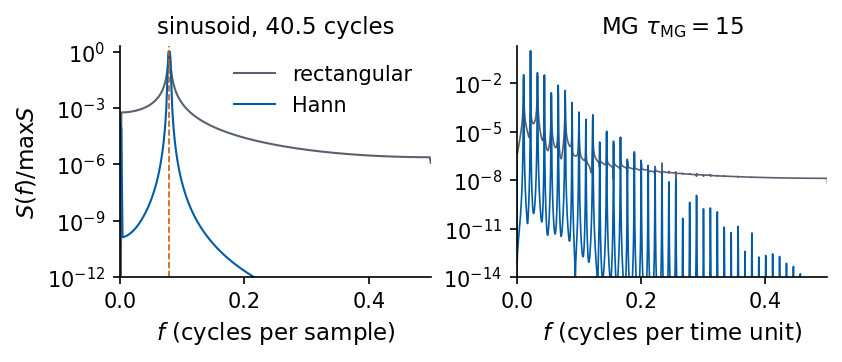

rectangular  sinusoid: largest leakage at |f - f0| > 0.1 is 4.2e-05 of the peak
Hann         sinusoid: largest leakage at |f - f0| > 0.1 is 6.7e-12 of the peak


In [23]:
n_ = np.arange(512)
f0 = 40.5 / 512                                   # 40.5 cycles in the record: not on the frequency grid
sine = np.sin(2 * np.pi * f0 * n_)
win = {"rectangular": np.ones(512), "Hann": scipy.signal.windows.hann(512, sym=False)}

def windowed_periodogram(x, w, dt=1.0):
    """S_q = dt |sum_n w_n (x_n - xbar) e^{-2 pi i q n/N}|^2 / sum_n w_n^2  (one-sided, density)."""
    f, P = scipy.signal.periodogram(x, fs=1 / dt, window=w, detrend="constant", scaling="density")
    return f, P

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained")
    for (name, w), c in zip(win.items(), (UJGray, UJBlue)):
        f, P = windowed_periodogram(sine, w)
        axs[0].semilogy(f, P / P.max(), color=c, lw=1.0, label=name)
        f, P = windowed_periodogram(S["mg15"], scipy.signal.windows.hann(N_SAMPLES, sym=False) if name == "Hann" else np.ones(N_SAMPLES))
        axs[1].semilogy(f, P / P.max(), color=c, lw=0.8, label=name)
    axs[0].axvline(f0, color=DSOrange, lw=0.8, ls="--")
    axs[0].set_xlim(0, 0.5); axs[0].set_ylim(1e-12, 2); axs[0].set_xlabel("$f$ (cycles per sample)")
    axs[0].set_ylabel(r"$S(f)/\max S$"); axs[0].set_title("sinusoid, 40.5 cycles"); axs[0].legend(loc="upper right")
    axs[1].set_xlim(0, 0.5); axs[1].set_ylim(1e-14, 2); axs[1].set_xlabel("$f$ (cycles per time unit)")
    axs[1].set_title(LABEL["mg15"])
    save(fig, "fig_leakage"); plt.show()
for name, w in win.items():
    f, P = windowed_periodogram(sine, w)
    far = np.abs(f - f0) > 0.1
    print(f"{name:12s} sinusoid: largest leakage at |f - f0| > 0.1 is {P[far].max() / P.max():.1e} of the peak")

Far from the peak, the rectangular window leaves a floor at $4\times10^{-5}$ of the peak, the Hann window at $7\times10^{-12}$. For the periodic Mackey–Glass signal the floor of the rectangular window ($\sim10^{-8}$) hides all harmonics beyond the first few, while the Hann window reveals a comb of lines over more than ten decades.

### Variance of the periodogram and the Welch method

The periodogram has a serious statistical flaw. At each frequency $\hat S(f_q)$ fluctuates around the true $S(f_q)$ with a standard deviation equal to its mean, for any record length, because a longer record gives more frequency bins with the same scatter. For Gaussian white noise $\hat S$ follows an exponential distribution, and we check this with $N=4000$ samples of unit variance, whose one-sided PSD is $S=2$. The Welch method trades resolution for variance. The record is cut into $K$ segments of length $L$ overlapping by $L/2$, each segment is demeaned and Hann-windowed, and the $K$ periodograms are averaged. The resolution becomes $1/(L\Delta t)$ and the relative scatter drops roughly as $1/\sqrt K$. We implement Welch in JAX, compare with `scipy.signal.welch`, and measure the scatter.

Lorenz $x$             segments 6, max rel. diff JAX vs scipy.signal.welch 4.6e-16
MG $\tau_{\rm MG}=15$  segments 6, max rel. diff JAX vs scipy.signal.welch 2.7e-16
MG $\tau_{\rm MG}=25$  segments 6, max rel. diff JAX vs scipy.signal.welch 2.6e-16
MG $\tau_{\rm MG}=35$  segments 6, max rel. diff JAX vs scipy.signal.welch 1.9e-16
Santa Fe               segments 6, max rel. diff JAX vs scipy.signal.welch 3.0e-16


white noise, raw periodogram : mean 1.982 (true 2), relative std 0.987
white noise, Welch L=1024    : mean 1.954 (true 2), relative std 0.451
white noise, Welch L=256     : mean 1.976 (true 2), relative std 0.190


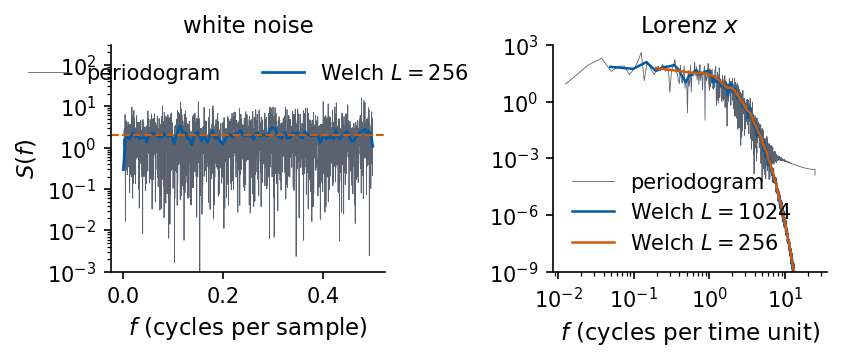

In [24]:
def welch_jax(x, dt, nperseg):
    """Welch estimate. Segments of length L = nperseg with 50% overlap, each demeaned and multiplied by the
    periodic Hann window w; S = average over segments of dt |sum_n w_n x_n e^{-2 pi i q n/L}|^2 / sum_n w_n^2."""
    x = jnp.asarray(x)
    step = nperseg // 2
    n_seg = (x.shape[0] - nperseg) // step + 1
    idx = jnp.arange(nperseg)[None, :] + step * jnp.arange(n_seg)[:, None]     # (n_seg, L) sample indices
    seg = x[idx]
    seg = seg - seg.mean(axis=1, keepdims=True)
    w = 0.5 - 0.5 * jnp.cos(2 * jnp.pi * jnp.arange(nperseg) / nperseg)        # periodic Hann window
    P = dt * jnp.abs(jnp.fft.rfft(seg * w, axis=1)) ** 2 / jnp.sum(w ** 2)
    P = P.mean(axis=0)
    P = P.at[1:-1].multiply(2.0) if nperseg % 2 == 0 else P.at[1:].multiply(2.0)  # one-sided
    return jnp.fft.rfftfreq(nperseg, dt), P, n_seg

for k in KEYS:
    f, P, nseg = welch_jax(S[k], DT[k], 1024)
    f_sp, P_sp = scipy.signal.welch(S[k], fs=1 / DT[k], window="hann", nperseg=1024, noverlap=512,
                                    detrend="constant", scaling="density")
    print(f"{LABEL[k]:22s} segments {nseg}, max rel. diff JAX vs scipy.signal.welch {np.abs(P - P_sp).max() / P_sp.max():.1e}")

# variance of the raw periodogram: white Gaussian noise, true one-sided density 2 sigma^2 dt = 2
noise = np.asarray(jax.random.normal(jax.random.key(0), (N_SAMPLES,)))
f_r, P_r = periodogram_jax(noise, 1.0); P_r = np.asarray(P_r)[1:-1]
stats = {"raw periodogram": P_r}
for L in (1024, 256):
    stats[f"Welch L={L}"] = np.asarray(welch_jax(noise, 1.0, L)[1])[1:-1]
for name, P in stats.items():
    print(f"white noise, {name:16s}: mean {P.mean():.3f} (true 2), relative std {P.std() / P.mean():.3f}")
nums["white_relstd"] = {name: float(P.std() / P.mean()) for name, P in stats.items()}

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained")
    axs[0].semilogy(f_r[1:-1], P_r, color=UJGray, lw=0.4, label="periodogram")
    fw, Pw, _ = welch_jax(noise, 1.0, 256)
    axs[0].semilogy(fw, Pw, color=UJBlue, lw=1.3, label="Welch $L=256$")
    axs[0].axhline(2.0, color=DSOrange, ls="--", lw=1.0)
    axs[0].set_xlabel("$f$ (cycles per sample)"); axs[0].set_ylabel("$S(f)$"); axs[0].set_title("white noise")
    axs[0].set_ylim(1e-3, 300); axs[0].legend(loc="upper center", ncol=2, fontsize=10)
    f, P = periodogram_jax(S["lorenz"], DT["lorenz"])
    axs[1].loglog(f[1:], P[1:], color=UJGray, lw=0.4, label="periodogram")
    for L, c in ((1024, UJBlue), (256, DSOrange)):
        fw, Pw, _ = welch_jax(S["lorenz"], DT["lorenz"], L)
        axs[1].loglog(fw[1:], Pw[1:], color=c, lw=1.2, label=f"Welch $L={L}$")
    axs[1].set_xlabel("$f$ (cycles per time unit)"); axs[1].set_title(LABEL["lorenz"]); axs[1].legend(fontsize=10, loc="lower left")
    axs[1].set_ylim(1e-9, 1e3)
    save(fig, "fig_welch"); plt.show()

For white noise the relative standard deviation is 0.987 for the raw periodogram, 0.451 for Welch with $L=1024$ (6 segments) and 0.190 for $L=256$. The right panel shows the same trade-off on Lorenz $x$ on logarithmic axes. The raw periodogram scatters by orders of magnitude between neighbouring bins, and its high-frequency tail flattens at about $10^{-4}$, the leakage floor of the rectangular window. The Welch estimates are smooth and follow the steep decay down to $10^{-9}$, and the shorter segments ($L=256$) give the smoother curve with the coarser frequency grid. From here on we use Welch with $L=1024$, which resolves $1/1024$ cycles per sample.

### Spectra of the five signals

We now look for peaks with `scipy.signal.find_peaks` on $\log_{10}\hat S$ and keep the peaks that stand out by more than one decade above their surroundings (prominence 1).

In [25]:
L_W = 1024
PSD = {k: tuple(np.asarray(a) for a in welch_jax(S[k], DT[k], L_W)[:2]) for k in KEYS}

def spectral_peaks(f, P, prominence=1.0, n_max=6):
    """Local maxima of log10 S standing out by more than `prominence` decades; the n_max highest."""
    idx, prop = scipy.signal.find_peaks(np.log10(P), prominence=prominence)
    idx = idx[np.argsort(P[idx])[::-1][:n_max]]
    return np.sort(idx)

rows = []
PEAKS = {}
for k in KEYS:
    f, P = PSD[k]
    pk = spectral_peaks(f[1:], P[1:]) + 1
    PEAKS[k] = pk
    for i in pk:
        rows.append({"signal": LABEL[k], "f (per " + UNIT[k] + ")": f[i], "period (" + UNIT[k] + "s)": 1 / f[i],
                     "period (samples)": 1 / (f[i] * DT[k]), "S(f)/S_max": P[i] / P.max()})
peak_table = pd.DataFrame(rows)
display(peak_table.round(4))
nums["psd_peaks"] = {k: [float(PSD[k][0][i]) for i in PEAKS[k]] for k in KEYS}

,signal,f (per time unit),period (time units),period (samples),S(f)/S_max,f (per sample)
0,MG $\tau_{\rm MG}=15$,0.0107,93.0909,93.0909,0.0392,NaN
1,MG $\tau_{\rm MG}=15$,0.0225,44.5217,44.5217,1.0000,NaN
2,MG $\tau_{\rm MG}=15$,0.0332,30.1176,30.1176,0.0601,NaN
3,MG $\tau_{\rm MG}=15$,0.0449,22.2609,22.2609,0.0263,NaN
4,MG $\tau_{\rm MG}=15$,0.0664,15.0588,15.0588,0.0064,NaN
5,MG $\tau_{\rm MG}=15$,0.0781,12.8000,12.8000,0.0043,NaN
6,MG $\tau_{\rm MG}=25$,0.0137,73.1429,73.1429,1.0000,NaN
7,MG $\tau_{\rm MG}=25$,0.0332,30.1176,30.1176,0.0661,NaN
8,MG $\tau_{\rm MG}=25$,0.0469,21.3333,21.3333,0.0739,NaN
9,MG $\tau_{\rm MG}=25$,0.0801,12.4878,12.4878,0.0016,NaN


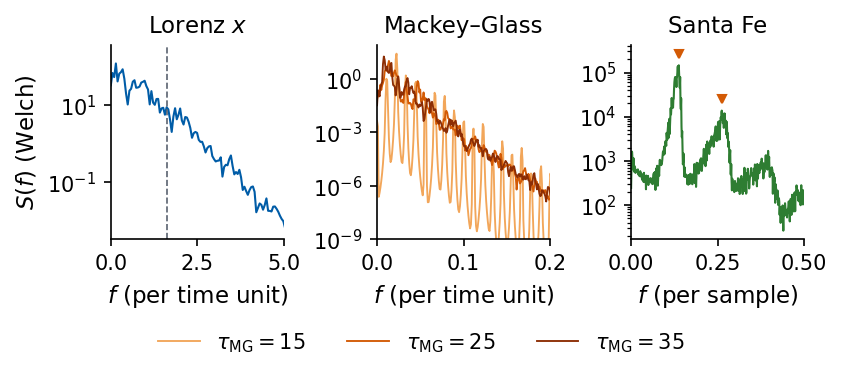

In [26]:
def ylim_visible(f, P, fmax, pad=3.0):
    v = P[(f > 0) & (f <= fmax)]
    return v.min() / pad, v.max() * pad
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.4), layout="constrained")
    f, P = PSD["lorenz"]
    axs[0].semilogy(f, P, color=COL["lorenz"], lw=1.0)
    axs[0].axvline(omega_c / (2 * np.pi), color=UJGray, ls="--", lw=0.8)
    axs[0].set_xlim(0, 5); axs[0].set_ylim(*ylim_visible(f, P, 5)); axs[0].set_xlabel("$f$ (per time unit)")
    axs[0].set_title(LABEL["lorenz"])
    lo, hi = np.inf, 0
    for k in ("mg15", "mg25", "mg35"):
        f, P = PSD[k]
        axs[1].semilogy(f, P, color=COL[k], lw=0.9, label=k[2:])
        a, b = ylim_visible(f, P, 0.2); lo, hi = min(lo, a), max(hi, b)
    axs[1].set_xlim(0, 0.2); axs[1].set_ylim(max(lo, 1e-9), hi); axs[1].set_xlabel("$f$ (per time unit)")
    axs[1].set_title("Mackey–Glass")
    f, P = PSD["santafe"]
    axs[2].semilogy(f, P, color=COL["santafe"], lw=1.0)
    axs[2].plot(f[PEAKS["santafe"]], P[PEAKS["santafe"]] * 1.8, "v", color=DSOrange, ms=4)
    axs[2].set_xlim(0, 0.5); axs[2].set_xlabel("$f$ (per sample)"); axs[2].set_title(LABEL["santafe"])
    axs[0].set_ylabel("$S(f)$ (Welch)")
    h, l = axs[1].get_legend_handles_labels()
    fig.legend(h, [r"$\tau_{\rm MG}=$" + s for s in l], loc="outside lower center", ncol=3, fontsize=10)
    save(fig, "fig_psd_signals"); plt.show()

The two statistics are two views of the same second-order structure, related by the Wiener–Khinchin theorem, and the slide figure below puts them side by side. A peak of the autocorrelation at lag $k=P$ means that the signal resembles itself after $P$ samples, and the power spectrum shows the same repetition as a peak at $f=1/P$ and, for a non-sinusoidal shape, at its multiples. For the Santa Fe laser the autocorrelation returns near its maximum every 7 to 8 samples, and the spectrum has its main peak at $f\approx0.14$ per sample with a second one near $2f$. The flashes are sharp pulses, not sine waves, so their power is spread over the harmonics, and the irregular growth and collapse of the amplitude broadens every peak. The slow decay of the autocorrelation envelope and the width of the spectral peaks measure the same loss of memory.

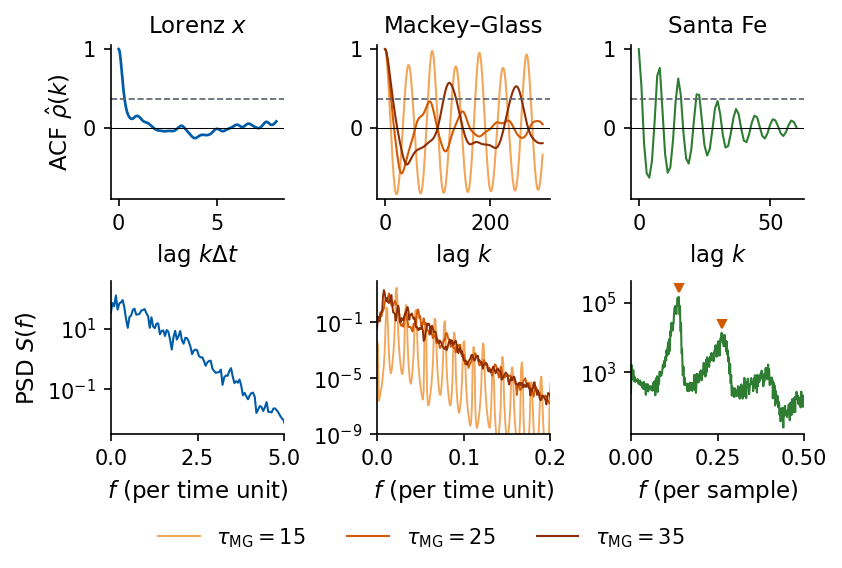

In [27]:
# slide figure: ACF (top row) and Welch PSD (bottom row) of the signals, drawn at slide size
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.7), layout="constrained")
    lags = np.arange(MAX_LAG + 1)
    axs[0, 0].plot(lags * DT["lorenz"], RHO["lorenz"], color=COL["lorenz"])
    axs[0, 0].set_xlabel(r"lag $k\Delta t$"); axs[0, 0].set_title(LABEL["lorenz"])
    for k in ("mg15", "mg25", "mg35"):
        axs[0, 1].plot(lags[:301], RHO[k][:301], color=COL[k], label=k[2:], lw=1.0)
    axs[0, 1].set_xlabel("lag $k$"); axs[0, 1].set_title("Mackey–Glass")
    axs[0, 2].plot(lags[:61], RHO["santafe"][:61], color=COL["santafe"], lw=1.0)
    axs[0, 2].set_xlabel("lag $k$"); axs[0, 2].set_title(LABEL["santafe"])
    for ax in axs[0]:
        ax.axhline(0, color="k", lw=0.5); ax.axhline(np.exp(-1), color=UJGray, lw=0.8, ls="--"); ax.set_ylim(-0.9, 1.05)
    axs[0, 0].set_ylabel(r"ACF $\hat\rho(k)$")
    f, P = PSD["lorenz"]
    axs[1, 0].semilogy(f, P, color=COL["lorenz"], lw=1.0)
    axs[1, 0].set_xlim(0, 5); axs[1, 0].set_ylim(*ylim_visible(f, P, 5)); axs[1, 0].set_xlabel("$f$ (per time unit)")
    lo, hi = np.inf, 0
    for k in ("mg15", "mg25", "mg35"):
        f, P = PSD[k]
        axs[1, 1].semilogy(f, P, color=COL[k], lw=0.9)
        a, b = ylim_visible(f, P, 0.2); lo, hi = min(lo, a), max(hi, b)
    axs[1, 1].set_xlim(0, 0.2); axs[1, 1].set_ylim(max(lo, 1e-9), hi); axs[1, 1].set_xlabel("$f$ (per time unit)")
    f, P = PSD["santafe"]
    axs[1, 2].semilogy(f, P, color=COL["santafe"], lw=1.0)
    axs[1, 2].plot(f[PEAKS["santafe"]], P[PEAKS["santafe"]] * 1.8, "v", color=DSOrange, ms=4)
    axs[1, 2].set_xlim(0, 0.5); axs[1, 2].set_xlabel("$f$ (per sample)")
    axs[1, 0].set_ylabel(r"PSD $S(f)$")
    h, l = axs[0, 1].get_legend_handles_labels()
    fig.legend(h, [r"$\tau_{\rm MG}=$" + s for s in l], loc="outside lower center", ncol=3, fontsize=10)
    save(fig, "fig_acf_psd_signals"); plt.show()


The figure shows the Welch PSD of each signal on a logarithmic scale. For Lorenz $x$ the dashed line marks the rotation frequency $1.62$ per time unit around $C_\pm$. To interpret the peaks of the Mackey–Glass and Santa Fe spectra we locate them on a finer frequency grid.

In [28]:
for k, tau in (("mg15", 15), ("mg25", 25), ("mg35", 35)):
    f, P = PSD[k]
    i_max = np.argmax(P[1:]) + 1
    print(f"{LABEL[k]:22s} highest Welch peak f = {f[i_max]:.5f} +- {0.5/L_W:.5f}, period {1/f[i_max]:6.1f} = {1/f[i_max]/tau:.2f} tau_MG")

# MG15: the maxima of x(t) take two values, so the orbit closes after two oscillations
x = S["mg15"]
pk, _ = scipy.signal.find_peaks(x)
print("MG15 heights of the maxima (rounded):", np.unique(np.round(x[pk], 3)))
mismatch = np.array([np.abs(x[T:] - x[:-T]).mean() for T in range(20, 121)])
T_best = 20 + int(np.argmin(mismatch))
print(f"MG15 shift T minimising <|x(t+T) - x(t)|> over T = 20..120: T = {T_best} (mismatch {mismatch.min():.4f});"
      f" at T = {T_best//2}: {np.abs(x[T_best//2:] - x[:-(T_best//2)]).mean():.4f}")
f, P = windowed_periodogram(x, scipy.signal.windows.hann(N_SAMPLES, sym=False))
i1 = np.argmax(P[(f > 0.005) & (f < 0.015)]) + np.argmax(f > 0.005)
i2 = np.argmax(P[1:]) + 1
print(f"MG15 full-record Hann periodogram: lowest line f = {f[i1]:.5f} (period {1/f[i1]:.1f}),"
      f" strongest line f = {f[i2]:.5f} (period {1/f[i2]:.2f} = {1/f[i2]/15:.3f} tau_MG), ratio {f[i2]/f[i1]:.3f}")
nums["mg15_period"] = float(1 / f[i1]); nums["mg15_strong_period"] = float(1 / f[i2])
# finer location of the dominant peak of the chaotic cases (full-record Hann periodogram, smoothed over 9 bins)
for k, tau in (("mg25", 25), ("mg35", 35)):
    f, P = windowed_periodogram(S[k], scipy.signal.windows.hann(N_SAMPLES, sym=False))
    Ps = np.convolve(P, np.ones(9) / 9, mode="same")
    band = (f > 0.004) & (f < 0.03)
    i = np.argmax(np.where(band, Ps, 0))
    print(f"{LABEL[k]:22s} smoothed full-record peak f = {f[i]:.5f}, period {1/f[i]:.1f} = {1/f[i]/tau:.2f} tau_MG")
    nums[f"{k}_peak_period"] = float(1 / f[i])
# Santa Fe: pulsation peak and the second peak
f, P = PSD["santafe"]
p1, p2 = f[PEAKS["santafe"][0]], f[PEAKS["santafe"][1]]
print(f"Santa Fe peaks f1 = {p1:.4f} (period {1/p1:.2f} samples), f2 = {p2:.4f}; f2/f1 = {p2/p1:.3f}")
nums["santafe_pulse_period"] = float(1 / p1); nums["santafe_f2_over_f1"] = float(p2 / p1)

MG $\tau_{\rm MG}=15$  highest Welch peak f = 0.02246 +- 0.00049, period   44.5 = 2.97 tau_MG
MG $\tau_{\rm MG}=25$  highest Welch peak f = 0.01367 +- 0.00049, period   73.1 = 2.93 tau_MG
MG $\tau_{\rm MG}=35$  highest Welch peak f = 0.00781 +- 0.00049, period  128.0 = 3.66 tau_MG
MG15 heights of the maxima (rounded): [1.006 1.167 1.168 1.281 1.282 1.283]
MG15 shift T minimising <|x(t+T) - x(t)|> over T = 20..120: T = 90 (mismatch 0.0040); at T = 45: 0.1201
MG15 full-record Hann periodogram: lowest line f = 0.01125 (period 88.9), strongest line f = 0.02225 (period 44.94 = 2.996 tau_MG), ratio 1.978
MG $\tau_{\rm MG}=25$  smoothed full-record peak f = 0.01375, period 72.7 = 2.91 tau_MG
MG $\tau_{\rm MG}=35$  smoothed full-record peak f = 0.00750, period 133.3 = 3.81 tau_MG
Santa Fe peaks f1 = 0.1377 (period 7.26 samples), f2 = 0.2617; f2/f1 = 1.901


The three types of spectra differ in a way that the time traces only suggest.

The Mackey–Glass signal at $\tau_{\rm MG}=15$ has a **line spectrum**. Its lowest line lies at $f_1=0.01125$ (period 88.9), and all other lines are integer multiples of it. The strongest line is the second harmonic $2f_1$ with period $44.94\approx3\tau_{\rm MG}$, and the maxima of $x(t)$ take two alternating heights, so the orbit closes after two oscillations of period close to $3\tau_{\rm MG}$. The shift $T=90$ maps the signal onto itself with mean mismatch 0.004 (the residue comes from the integer grid of shifts), while the shift $T=45$ leaves a mismatch of 0.12. This is a periodic orbit of twice the basic oscillation period.

For $\tau_{\rm MG}=25$ and 35 the lines merge into a **broadband** spectrum with broad peaks. The dominant peak of $\tau_{\rm MG}=25$ has period 72.7 $=2.91\,\tau_{\rm MG}$, close to the period of about $3\tau_{\rm MG}$ of the basic oscillation of the periodic signal at $\tau_{\rm MG}=15$. For $\tau_{\rm MG}=35$ the highest peak of our record lies at period 133.3 $=3.81\,\tau_{\rm MG}$ (128 in the Welch estimate, whose resolution is $\pm5\times10^{-4}$ in frequency), so the relation to $3\tau_{\rm MG}$ does not hold for this record at the resolution available.

The Lorenz spectrum is broadband without any line. The power is roughly flat up to about one cycle per time unit and decays steeply at higher frequencies, by about ten decades up to 12 cycles per time unit. The rotation around $C_\pm$ (dashed line) produces no peak, because its amplitude grows during each sequence of rotations and the irregular jumps between the lobes interrupt it. The jumps add power at low frequencies.

The Santa Fe spectrum has a sharp **pulsation peak** at $f_1=0.1377$ cycles per sample (period 7.26 samples) and a second peak at $f_2=0.2617$, slightly below $2f_1$ ($f_2/f_1=1.90$). A third broad hump lies near 0.4 cycles per sample. The rise of $\hat S$ towards $f=0$ comes from the slow build-up and collapse cycles, which last a few hundred samples.

<hr/>
## 6. Delay embedding

### Phase space from one coordinate

A harmonic oscillator has the state $(x,v)$, but suppose we measure only the position $x(t)=\cos\omega t$. The finite difference $(x_k-x_{k-1})/\Delta t$ approximates the velocity, so the pair $(x_k,x_{k-\kappa})$ carries the same information as $(x,v)$. The figure shows the measured signal, the true phase portrait and the delay portrait with $\kappa=20$ samples, a deformed copy of the same closed curve. For Lorenz-63 the same works with derivatives up to second order. From $\dot x=\sigma(y-x)$ we get $y=x+\dot x/\sigma$, then $\dot y=\dot x+\ddot x/\sigma$ and from $\dot y=x(\rho-z)-y$ we get $z=\rho-(\dot y+y)/x$, so $(x,\dot x,\ddot x)$ determine $(x,y,z)$ wherever $x\neq0$. Delays approximate these derivatives and are less sensitive to noise. This observation is due to N. H. Packard, J. P. Crutchfield, J. D. Farmer and R. S. Shaw, Phys. Rev. Lett. **45**, 712 (1980), [doi:10.1103/PhysRevLett.45.712](https://doi.org/10.1103/PhysRevLett.45.712).

max |finite difference - v| = 0.025 (dt = 0.05)


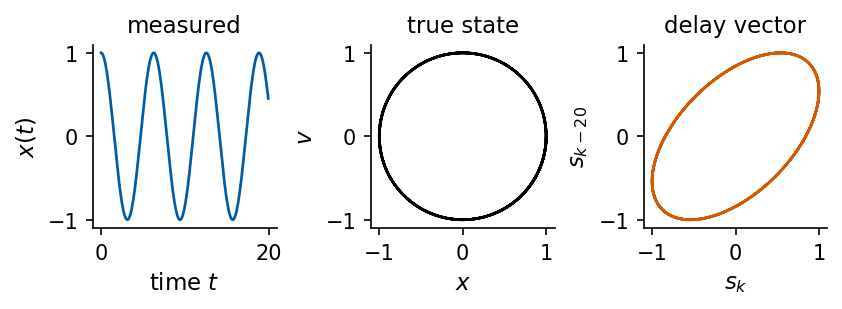

In [29]:
# harmonic oscillator x(t) = cos(omega t): the true phase portrait (x, v) and the delay portrait (x_k, x_{k-κ})
OMEGA, DT_OSC, L_OSC = 1.0, 0.05, 20                       # one period has 2 pi / (omega dt) = 126 samples; delay κ = 20 samples
t_osc = np.arange(400) * DT_OSC
x_osc, v_osc = np.cos(OMEGA * t_osc), -OMEGA * np.sin(OMEGA * t_osc)
v_fd = (x_osc[1:] - x_osc[:-1]) / DT_OSC                  # finite difference of the measured coordinate
print(f"max |finite difference - v| = {np.abs(v_fd - v_osc[1:]).max():.3f} (dt = {DT_OSC})")
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 1.95), layout="constrained")
    axs[0].plot(t_osc, x_osc, color=UJBlue); axs[0].set_xlabel("time $t$"); axs[0].set_ylabel("$x(t)$")
    axs[0].set_title("measured")
    axs[1].plot(x_osc, v_osc, color="k"); axs[1].set_xlabel("$x$"); axs[1].set_ylabel("$v$"); axs[1].set_aspect("equal")
    axs[1].set_title("true state")
    axs[2].plot(x_osc[L_OSC:], x_osc[:-L_OSC], color=DSOrange); axs[2].set_xlabel("$s_k$"); axs[2].set_ylabel(f"$s_{{k-{L_OSC}}}$")
    axs[2].set_aspect("equal"); axs[2].set_title("delay vector")
    save(fig, "fig_delay_oscillator"); plt.show()

The same construction works for a chaotic flow. For Lorenz-63 we record only $x(t)$ and plot the delay vector $(x_k, x_{k-\kappa}, x_{k-2\kappa})$ with $\kappa=10$ samples, which is $0.2$ time units. The two lobes of the attractor reappear in a deformed but recognisable form. How to choose $\kappa$ and the number of delays is the subject of the next subsections.

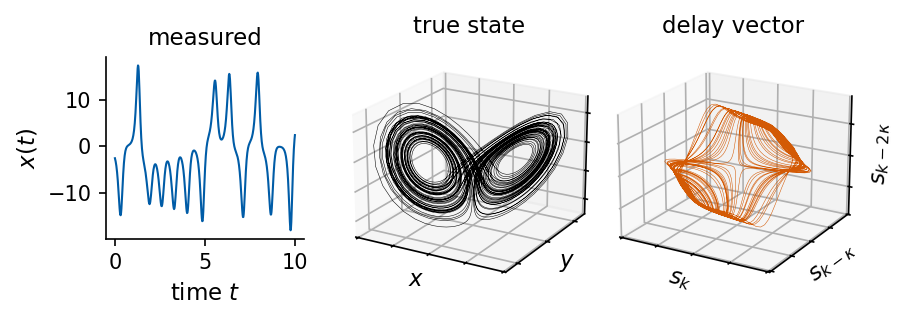

In [30]:
# Lorenz-63: measured x(t), the true state (x, y, z) and the delay vector (x_k, x_{k-κ}, x_{k-2κ})
L_LOR, N_SHOW = 10, 3000                                   # delay of 10 samples = 0.2 time units
x_l = S["lorenz"]
Y_lor = np.stack([x_l[2 * L_LOR:], x_l[L_LOR:-L_LOR], x_l[:-2 * L_LOR]], axis=1)
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 1.95))
    ax0 = fig.add_axes([0.08, 0.24, 0.24, 0.62])
    ax0.plot(np.arange(500) * DT["lorenz"], x_l[:500], color=UJBlue, lw=1.0)
    ax0.set_xlabel("time $t$"); ax0.set_ylabel("$x(t)$"); ax0.set_title("measured")
    for c, (Y, title, labs, col) in enumerate([(lor_states[:N_SHOW], "true state", ("$x$", "$y$", "$z$"), "k"),
                                               (Y_lor[:N_SHOW], "delay vector", ("$s_k$", r"$s_{k-\kappa}$", r"$s_{k-2\kappa}$"), DSOrange)]):
        ax = fig.add_axes([0.36 + 0.32 * c, 0.0, 0.32, 0.95], projection="3d")
        ax.plot(*Y.T, lw=0.25, color=col)
        ax.set_title(title, pad=-4)
        ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
        for setter, lab in zip((ax.set_xlabel, ax.set_ylabel, ax.set_zlabel), labs):
            setter(lab, labelpad=-12)
        ax.view_init(elev=20, azim=-60)
    save(fig, "fig_delay_lorenz"); plt.show()


### Poincaré map

A continuous orbit can be reduced to a sequence of points. We choose a surface $\Sigma$ in phase space that the flow crosses transversally, a Poincaré section, and record the state at each crossing in one direction. The Poincaré map sends one crossing to the next,

$$P:\ \Sigma\to\Sigma,\qquad \mathbf x_{n+1}=P(\mathbf x_n).$$

A periodic orbit crosses $\Sigma$ at the same places again and again, so it appears as a finite set of points, a fixed point or a short cycle of $P$. A quasi-periodic orbit fills a closed curve, and a chaotic orbit gives infinitely many points that never repeat [H. Poincaré, *Les méthodes nouvelles de la mécanique céleste*, Gauthier-Villars (1892–1899); E. N. Lorenz, J. Atmos. Sci. **20**, 130 (1963), [doi:10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2](https://doi.org/10.1175/1520-0469(1963)020%3C0130:DNF%3E2.0.CO;2)].

For a measured signal a convenient section is $\dot s=0$ with $\ddot s<0$, the local maxima. The map of successive maxima $M_{n+1}$ against $M_n$ is the one Lorenz used for the maxima of $z$. Each maximum is located by a parabola through the largest sample and its two neighbours. The figure shows Mackey–Glass at $\tau_{\rm MG}=15$ and $\tau_{\rm MG}=35$ and the maxima of $z$ of Lorenz-63, each from a long run of the same equations.

MG $\tau_{\rm MG}=15$         1336 maxima, distinct values (rounded to 1e-3): 6
MG $\tau_{\rm MG}=35$         1247 maxima, distinct values (rounded to 1e-3): 511
Lorenz-63, maxima of $z$      1063 maxima, distinct values (rounded to 1e-3): 1009
MG 15 maxima groups (mean, count): [(1.006, 446), (1.168, 445), (1.283, 445)]


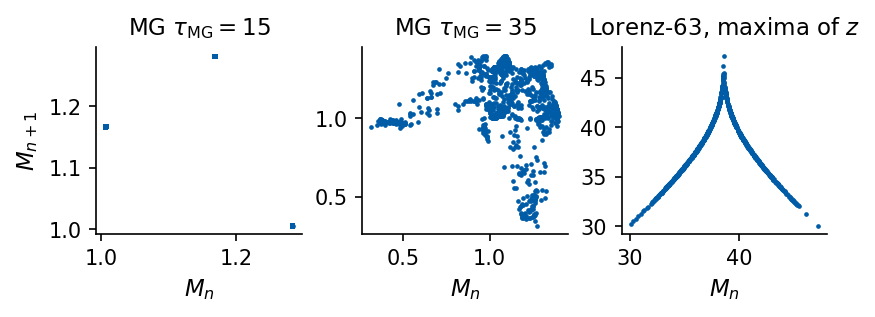

In [31]:
# Poincare map at the section ds/dt = 0, d2s/dt2 < 0: successive local maxima M_{n+1} against M_n
def local_maxima(x):
    """Values of the local maxima of a sampled signal, refined by a parabola through three samples."""
    k = np.flatnonzero((x[1:-1] > x[:-2]) & (x[1:-1] >= x[2:])) + 1
    a, b, c = x[k - 1], x[k], x[k + 1]
    den = a - 2 * b + c
    return b - 0.125 * (c - a) ** 2 / np.where(den != 0, den, -1e-300)

N_POINC = 40000
poinc = {r"MG $\tau_{\rm MG}=15$": mackey_glass(15, N_POINC),
         r"MG $\tau_{\rm MG}=35$": mackey_glass(35, N_POINC),
         "Lorenz-63, maxima of $z$": np.asarray(lorenz_trajectory(N_POINC))[:, 2]}
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.0), layout="constrained")
    for ax, (name, x) in zip(axs, poinc.items()):
        M = local_maxima(x)
        ax.plot(M[:-1], M[1:], ".", ms=2.5, color=UJBlue)
        ax.set_title(name); ax.set_xlabel("$M_n$")
        print(f"{name:28s} {len(M):5d} maxima, distinct values (rounded to 1e-3): {len(np.unique(np.round(M, 3)))}")
        nums.setdefault("poincare_maxima", {})[name] = int(len(M))
    axs[0].set_ylabel("$M_{n+1}$")
    # the maxima of the periodic MG 15 orbit fall into a few groups; their mean values
    v15 = np.sort(local_maxima(poinc[r"MG $\tau_{\rm MG}=15$"]))
    groups15 = np.split(v15, np.flatnonzero(np.diff(v15) > 0.05) + 1)
    nums["mg15_maxima_values"] = [float(g.mean()) for g in groups15]
    print("MG 15 maxima groups (mean, count):", [(round(float(g.mean()), 3), len(g)) for g in groups15])
    save(fig, "fig_poincare_maxima"); plt.show()


The three panels separate the kinds of motion at a glance. For $\tau_{\rm MG}=15$ the 1336 maxima take only three values, visited in turn, so the Poincaré map has a cycle of period 3 and the orbit is periodic with three maxima per period. For $\tau_{\rm MG}=35$ the 1247 maxima never repeat and spread over a two-dimensional region of the plane. Its attractor has the Kaplan–Yorke dimension 3.41 computed in Section 9, against 2.06 for Lorenz-63, so a single maximum does not fix the next one. The maxima of $z$ of Lorenz-63 also never repeat, but they lie on a thin cusp. The Lorenz attractor is strongly contracting, close to a surface, and the next maximum is almost a function of the previous one, a one-dimensional map with a slope steeper than 1 on both branches. This stretching is the origin of the positive Lyapunov exponent.

A single measured value does not fix the state of the system. The figure marks two moments at which the Lorenz signal has the same value, near $x=4.6$, once rising and once falling. The next values differ, although the measured value is the same, because the unmeasured coordinates $y$ and $z$ differ. To forecast $s_{k+1}$ we therefore need some past values, and the question is how many past values, and how far apart, are enough to fix the state.

x = 4.62 at k = 266 (next step +0.63) and x = 4.64 at k = 325 (next step -1.24)


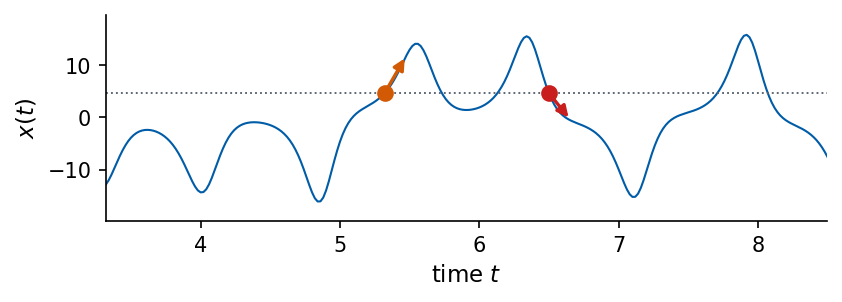

In [32]:
# one value does not fix the state: two moments of Lorenz x with the same value and opposite next steps
x_h = S["lorenz"][:1500]
dx = np.diff(x_h)
target = 5.0
near = np.flatnonzero(np.abs(x_h[:-1] - target) < 0.4)
ups, dns = near[dx[near] > 0], near[dx[near] < 0]
# a rising and a falling sample, close in time, whose values agree to within 0.1
pairs = [(i, j) for i in ups for j in dns if 0 < j - i < 60 and abs(x_h[i] - x_h[j]) < 0.1]
k_up, k_dn = pairs[0]
print(f"x = {x_h[k_up]:.2f} at k = {k_up} (next step +{dx[k_up]:.2f}) and x = {x_h[k_dn]:.2f} at k = {k_dn} (next step {dx[k_dn]:.2f})")
nums["hook"] = {"x_up": float(x_h[k_up]), "k_up": int(k_up), "dx_up": float(dx[k_up]),
                "x_dn": float(x_h[k_dn]), "k_dn": int(k_dn), "dx_dn": float(dx[k_dn])}
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 1.9), layout="constrained")
    t_h = np.arange(len(x_h)) * DT["lorenz"]
    ax.plot(t_h, x_h, color=UJBlue, lw=1.0)
    ax.axhline(x_h[k_up], color=UJGray, ls=":", lw=0.9)
    for kk, c in ((k_up, DSOrange), (k_dn, "#C81E1E")):
        ax.plot(t_h[kk], x_h[kk], "o", color=c, ms=7, zorder=4)
        ax.annotate("", xy=(t_h[kk + 8], x_h[kk + 8]), xytext=(t_h[kk], x_h[kk]),
                    arrowprops=dict(arrowstyle="-|>", color=c, lw=1.6))
    ax.set_xlabel("time $t$"); ax.set_ylabel("$x(t)$")
    ax.set_xlim(t_h[min(k_up, k_dn)] - 2, t_h[max(k_up, k_dn)] + 2)
    save(fig, "fig_one_value_hook"); plt.show()


### Takens theorem

The spectra describe how the variance of a signal is distributed over frequencies. For a deterministic system we would like to see the state space itself, while we measure only one coordinate. Takens showed that this is possible [F. Takens, Lect. Notes Math. **898**, 366 (1981), [doi:10.1007/BFb0091924](https://doi.org/10.1007/BFb0091924)]. From the samples we form **delay vectors**
$$
\mathbf y_k=\big(s_k,\;s_{k-\kappa},\;s_{k-2\kappa},\;\dots,\;s_{k-(m-1)\kappa}\big)\in\mathbb R^m ,
$$
with delay $\kappa$ (in samples) and embedding dimension $m$. Let the dynamics take place on a smooth compact manifold of dimension $d$ and let the measured quantity be a smooth function of the state. Takens' theorem states that for a generic measurement function and a generic delay the map from the state to $\mathbf y_k$ is an embedding (one-to-one, smooth, with smooth inverse on its image) whenever $m\ge2d+1$. Sauer, Yorke and Casdagli extended the result to fractal attractors, where $m>2d_A$ suffices with $d_A$ the box-counting dimension of the attractor [T. Sauer, J. A. Yorke and M. Casdagli, J. Stat. Phys. **65**, 579 (1991), [doi:10.1007/BF01053745](https://doi.org/10.1007/BF01053745)]. The delay vectors therefore carry the full state of the system, and a forecasting model that receives $\mathbf y_k$ as input has all the information that the present state contains. Quantities that are invariant under smooth changes of coordinates, such as the Lyapunov exponents of Section 8, can be computed from the delay vectors.

The theorem leaves the choice of $\kappa$ and $m$ open. If $\kappa$ is too small, consecutive coordinates are almost equal and the vectors crowd near the diagonal. If $\kappa$ is too large in a chaotic signal, the coordinates become unrelated and the reconstructed attractor dissolves. We choose $\kappa$ from the mutual information and $m$ from false nearest neighbours.

The word embedding has a precise meaning. A map $\mathcal E$ from the attractor into $\mathbb R^m$ is an embedding if different states go to different points and if nearby states go to nearby points and back. The image is then a faithful copy of the attractor, deformed smoothly but neither torn nor glued to itself. The simplest attractor shows what can go wrong. A periodic signal lives on a closed curve, so $D=1$. In two delay coordinates the curve crosses itself. At the crossing two different states of the orbit share the same delay vector, and since their futures differ, no function of $(s_k,s_{k-\kappa})$ can forecast both. In three coordinates the two branches pass each other at a distance and the crossing is gone. Two pieces of dimension $D$ in $\mathbb R^m$ meet in general only if $D+D\ge m$, which is the origin of the condition $m>2D$.

self-crossings of the curve in m = 2: 1 | at states (samples) [(205, 294)]
state a = sample 205, state b = sample 294: distance in m = 2 0.013, in m = 3 1.819


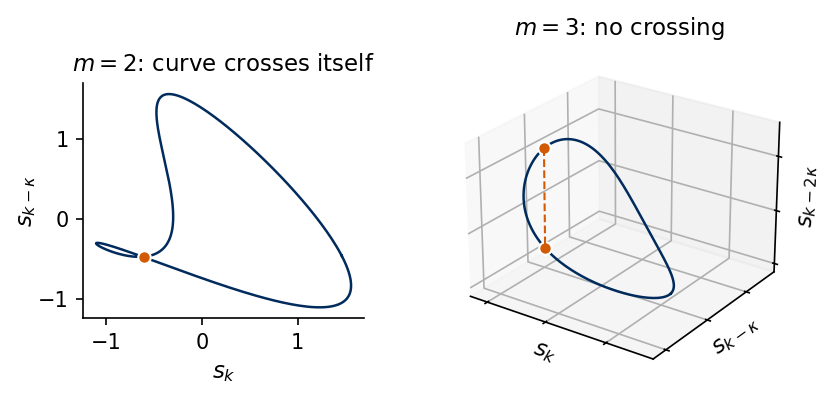

In [33]:
# a periodic signal (attractor = closed curve, D = 1) in delay coordinates m = 2 and m = 3
N_EMB, L_EMB = 400, 100                                     # samples per period, delay (a quarter period)
phase = 2 * np.pi * np.arange(N_EMB) / N_EMB                 # the state: one angle on the closed orbit
s_emb = np.cos(phase) + 0.6 * np.cos(2 * phase + 0.7)        # the measurement h of that state
y_emb = np.stack([s_emb, np.roll(s_emb, L_EMB), np.roll(s_emb, 2 * L_EMB)], axis=1)   # (s_k, s_{k-κ}, s_{k-2κ})

def self_crossings(P):
    """Pairs (i, j) of non-adjacent segments P_i P_{i+1} and P_j P_{j+1} of the closed curve P (n, 2) that cross."""
    A, B = P, np.roll(P, -1, axis=0)
    out = []
    for i in range(len(P)):
        for j in range(i + 2, len(P) - (i == 0)):
            d1, d2 = B[i] - A[i], B[j] - A[j]
            den = d1[0] * d2[1] - d1[1] * d2[0]
            if den == 0:
                continue
            r = A[j] - A[i]
            u, v = (r[0] * d2[1] - r[1] * d2[0]) / den, (r[0] * d1[1] - r[1] * d1[0]) / den
            if 0 <= u <= 1 and 0 <= v <= 1:
                out.append((i, j))
    return out

cross = self_crossings(y_emb[:, :2])
print("self-crossings of the curve in m = 2:", len(cross), "| at states (samples)", cross)
i_a, i_b = cross[0]
print(f"state a = sample {i_a}, state b = sample {i_b}: distance in m = 2 "
      f"{np.linalg.norm(y_emb[i_a, :2] - y_emb[i_b, :2]):.3f}, in m = 3 {np.linalg.norm(y_emb[i_a] - y_emb[i_b]):.3f}")
nums["crossing"] = {"a": int(i_a), "b": int(i_b), "d2": float(np.linalg.norm(y_emb[i_a, :2] - y_emb[i_b, :2])),
                    "d3": float(np.linalg.norm(y_emb[i_a] - y_emb[i_b]))}
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.3))
    ax1 = fig.add_axes([0.10, 0.20, 0.34, 0.68])
    ax1.plot(*np.vstack([y_emb[:, :2], y_emb[:1, :2]]).T, color=UJNavy, lw=1.2)
    ax1.plot(*y_emb[i_a, :2], "o", color=DSOrange, ms=6, mec="white")
    ax1.set_xlabel("$s_k$"); ax1.set_ylabel(r"$s_{k-\kappa}$", labelpad=0)
    ax1.set_title("$m=2$: curve crosses itself")
    ax2 = fig.add_axes([0.52, 0.0, 0.46, 1.0], projection="3d")
    ax2.plot(*np.vstack([y_emb, y_emb[:1]]).T, color=UJNavy, lw=1.2)
    for i in (i_a, i_b):
        ax2.plot(*y_emb[i], "o", color=DSOrange, ms=6, mec="white")
    ax2.plot(*y_emb[[i_a, i_b]].T, color=DSOrange, ls="--", lw=1.0)
    ax2.set_title("$m=3$: no crossing", pad=-2)
    ax2.set_xticklabels([]); ax2.set_yticklabels([]); ax2.set_zticklabels([])
    for setter, lab in zip((ax2.set_xlabel, ax2.set_ylabel, ax2.set_zlabel), ("$s_k$", r"$s_{k-\kappa}$", r"$s_{k-2\kappa}$")):
        setter(lab, labelpad=-12)
    ax2.view_init(elev=25, azim=-55)
    save(fig, "fig_embedding_crossing"); plt.show()


### Delay from the mutual information

A simple choice of $\kappa$ is the first zero of the ACF, at which neighbouring coordinates are linearly uncorrelated. Fraser and Swinney proposed a measure of general statistical dependence instead, the mutual information between $s_k$ and $s_{k-\kappa}$ [A. M. Fraser and H. L. Swinney, Phys. Rev. A **33**, 1134 (1986), [doi:10.1103/PhysRevA.33.1134](https://doi.org/10.1103/PhysRevA.33.1134)]. We divide the range of $s$ into 16 equal bins, estimate the probability $p_i$ of bin $i$ and the joint probability $p_{ij}(\kappa)$ that $s_{k-\kappa}$ falls in bin $i$ and $s_k$ in bin $j$, and compute
$$
\mathrm{MI}(\kappa)=\sum_{i,j}p_{ij}(\kappa)\,\ln\frac{p_{ij}(\kappa)}{p_i\,p_j}\quad\text{(in nats)} .
$$
$\mathrm{MI}(\kappa)\ge0$, and $\mathrm{MI}(\kappa)=0$ only for independent variables. The delay is the first local minimum of $\mathrm{MI}(\kappa)$, where the new coordinate adds the most new information while it is still dynamically related to the old one. The delay and the embedding dimension set the length of the input window of the forecasting models, so we compute both on the first $N_{\rm fit}=2500$ samples, the part of the record on which those models are fitted. The validation and test blocks never enter these choices. All other statistics of this notebook characterise the signals and choose no model setting, and they use all 4000 samples. The JAX function below builds all joint histograms with one `vmap` over the lags, using the same $N-\kappa_{\max}$ pairs for every lag.

In [34]:
@partial(jax.jit, static_argnums=(1, 2))
def mutual_information(x, max_lag, bins=16):
    """MI(κ) = sum_ij p_ij(κ) ln[p_ij(κ) / (p_i p_j)] for κ = 0..max_lag, from a bins x bins histogram of the
    pairs (x_n, x_{n+κ}), n = 0..N-max_lag-1 (the same pairs count for every lag)."""
    lo, hi = x.min(), x.max()
    s = jnp.clip(((x - lo) / (hi - lo) * bins).astype(jnp.int32), 0, bins - 1)     # bin index of each sample
    n = x.shape[0] - max_lag
    def mi(lag):
        a = jax.lax.dynamic_slice(s, (0,), (n,))
        b = jax.lax.dynamic_slice(s, (lag,), (n,))
        p = jnp.zeros((bins, bins)).at[a, b].add(1.0) / n                         # joint histogram p_ij
        pa, pb = p.sum(1, keepdims=True), p.sum(0, keepdims=True)                  # marginals p_i, p_j
        safe = jnp.where(p > 0, p, 1.0)
        return jnp.sum(jnp.where(p > 0, p * jnp.log(safe / (pa * pb)), 0.0))
    return jax.vmap(mi)(jnp.arange(max_lag + 1))

def first_local_min(c):
    for j in range(1, len(c) - 1):
        if c[j] < c[j - 1] and c[j] <= c[j + 1]:
            return j
    return None

N_FIT = N_TRAIN - N_VAL                          # delay and dimension choose the input window: fitting part only
MI = {k: np.asarray(mutual_information(jnp.asarray(S[k][:N_FIT]), 100)) for k in KEYS}
LAG = {}
for k in KEYS:
    LAG[k] = first_local_min(MI[k])
    print(f"{LABEL[k]:22s} first MI minimum at κ = {LAG[k]:3d} samples ({LAG[k]*DT[k]:.2f} {UNIT[k]}s) | "
          f"first ACF zero at {CT[k][0]} samples | MI(0) = {MI[k][0]:.3f} nats, MI(κ*) = {MI[k][LAG[k]]:.3f} nats")
nums["mi_zero"] = {k: float(MI[k][0]) for k in KEYS}
nums["mi_first_min"] = {k: float(MI[k][LAG[k]]) for k in KEYS}


Lorenz $x$             first MI minimum at κ =  10 samples (0.20 time units) | first ACF zero at 89 samples | MI(0) = 2.624 nats, MI(κ*) = 0.775 nats
MG $\tau_{\rm MG}=15$  first MI minimum at κ =   8 samples (8.00 time units) | first ACF zero at 11 samples | MI(0) = 2.664 nats, MI(κ*) = 0.945 nats
MG $\tau_{\rm MG}=25$  first MI minimum at κ =  15 samples (15.00 time units) | first ACF zero at 18 samples | MI(0) = 2.612 nats, MI(κ*) = 0.288 nats
MG $\tau_{\rm MG}=35$  first MI minimum at κ =  21 samples (21.00 time units) | first ACF zero at 24 samples | MI(0) = 2.663 nats, MI(κ*) = 0.182 nats
Santa Fe               first MI minimum at κ =   2 samples (2.00 samples) | first ACF zero at 2 samples | MI(0) = 2.259 nats, MI(κ*) = 0.180 nats


The two criteria agree for Mackey–Glass and Santa Fe within a few samples, and differ by a factor of nine for Lorenz $x$, where the first MI minimum is at $\kappa=10$ (0.20 time units) and the ACF zero at 89 samples. The ACF zero of Lorenz $x$ measures the memory of the lobe, which is far longer than the time over which the state changes appreciably within one rotation.

### Embedding dimension from false nearest neighbours

If $m$ is too small, the reconstruction folds the attractor onto itself, and points that are far apart on the attractor appear as neighbours. Kennel, Brown and Abarbanel detect this directly [M. B. Kennel, R. Brown and H. D. I. Abarbanel, Phys. Rev. A **45**, 3403 (1992), [doi:10.1103/PhysRevA.45.3403](https://doi.org/10.1103/PhysRevA.45.3403)]. For every delay vector $\mathbf y_i^{(m)}$ we find its nearest neighbour $\mathbf y_j^{(m)}$, excluding all $j$ with $|i-j|\le w$ (Theiler window, here $w=50$ samples), because points close in time are trivially close in space. The neighbour is **false** if the added coordinate separates the two points strongly,
$$
\frac{|s_{i-m\kappa}-s_{j-m\kappa}|}{\|\mathbf y_i^{(m)}-\mathbf y_j^{(m)}\|}>R_{\rm tol}=15,
$$
and Kennel et al. add an absolute test, $\|\mathbf y_i^{(m+1)}-\mathbf y_j^{(m+1)}\|/\sigma_s>A_{\rm tol}=2$, with $\sigma_s$ the standard deviation of the signal. The fraction of false neighbours is plotted against $m$, and it drops to a low level once the attractor is unfolded.

The neighbour search is a dense distance computation in JAX over batches of points, which we first check against the $k$-d tree of `scipy.spatial.cKDTree`.

In [35]:
def delay_embed(x, m, lag):
    """Rows y_n = (x_n, x_{n-κ}, ..., x_{n-(m-1)κ}) for n = (m-1)κ .. N-1; shape (N-(m-1)κ, m)."""
    n = len(x) - (m - 1) * lag
    return np.stack([x[(m - 1) * lag - j * lag:(m - 1) * lag - j * lag + n] for j in range(m)], axis=1)

@partial(jax.jit, static_argnums=2)
def nearest_neighbour(Y, w, batch=500):
    """For every row i of Y the index j of its nearest neighbour with |i - j| > w (Theiler window) and the distance."""
    n = Y.shape[0]
    idx = jnp.arange(n)
    def one(i):
        d2 = jnp.sum((Y - Y[i]) ** 2, axis=1)
        d2 = jnp.where(jnp.abs(idx - i) <= w, jnp.inf, d2)
        j = jnp.argmin(d2)
        return j, jnp.sqrt(d2[j])
    return jax.lax.map(one, idx, batch_size=batch)

# sanity check of the neighbour search against a k-d tree (scipy) without Theiler window
Ytest = delay_embed(S["lorenz"], 3, 10)
j_jax, d_jax = nearest_neighbour(jnp.asarray(Ytest), 0)
d_kd, j_kd = cKDTree(Ytest).query(Ytest, k=2)
print("nearest-neighbour distances JAX vs cKDTree, max difference:", float(np.abs(np.asarray(d_jax) - d_kd[:, 1]).max()))

def fnn_fractions(x, lag, m_max=10, w=50, r_tol=15.0, a_tol=2.0):
    """False-nearest-neighbour fractions for m = 1..m_max (Kennel et al.). Returns the ratio test alone and
    the ratio test OR the absolute test."""
    sig = x.std()
    ratio, both = [], []
    for m in range(1, m_max + 1):
        Y = delay_embed(x, m + 1, lag)               # first m columns: y_n^(m); last column: the added x_{n-mκ}
        j, r = (np.asarray(a) for a in nearest_neighbour(jnp.asarray(Y[:, :m]), w))
        extra = np.abs(Y[:, m] - Y[j, m])            # |x_{i-mκ} - x_{j-mκ}|
        test1 = extra > r_tol * r
        test2 = np.sqrt(r ** 2 + extra ** 2) / sig > a_tol
        ratio.append(test1.mean()); both.append((test1 | test2).mean())
    return np.array(ratio), np.array(both)

FNN = {k: fnn_fractions(S[k][:N_FIT], LAG[k]) for k in KEYS}
FNN_THRESHOLD = 0.05
EMB_M = {k: int(np.argmax(FNN[k][0] < FNN_THRESHOLD)) + 1 for k in KEYS}
for k in KEYS:
    print(f"{LABEL[k]:22s} κ = {LAG[k]:3d}  ratio test {np.round(FNN[k][0], 3)}")
    print(f"{'':22s}          both tests {np.round(FNN[k][1], 3)}  -> m = {EMB_M[k]}")

nearest-neighbour distances JAX vs cKDTree, max difference: 2.220446049250313e-16


Lorenz $x$             κ =  10  ratio test [0.95  0.173 0.064 0.035 0.024 0.011 0.008 0.005 0.002 0.   ]
                                both tests [0.95  0.173 0.067 0.042 0.035 0.028 0.04  0.049 0.051 0.067]  -> m = 4
MG $\tau_{\rm MG}=15$  κ =   8  ratio test [0.139 0.002 0.    0.    0.    0.    0.    0.    0.    0.   ]
                                both tests [0.139 0.002 0.    0.    0.    0.    0.    0.    0.    0.   ]  -> m = 2
MG $\tau_{\rm MG}=25$  κ =  15  ratio test [0.98  0.304 0.092 0.043 0.032 0.025 0.022 0.017 0.015 0.014]
                                both tests [0.98  0.304 0.095 0.05  0.051 0.054 0.054 0.061 0.06  0.069]  -> m = 4
MG $\tau_{\rm MG}=35$  κ =  21  ratio test [0.992 0.42  0.115 0.019 0.003 0.    0.    0.    0.    0.   ]
                                both tests [0.992 0.421 0.133 0.051 0.058 0.061 0.054 0.061 0.064 0.065]  -> m = 4
Santa Fe               κ =   2  ratio test [0.975 0.152 0.017 0.004 0.002 0.002 0.    0.    0.    0.   ]
               

The ratio test drops below 5% at $m=4$ for Lorenz, $\tau_{\rm MG}=25$ and $\tau_{\rm MG}=35$, at $m=2$ for the periodic $\tau_{\rm MG}=15$ (a closed curve needs two dimensions to avoid self-crossings) and at $m=3$ for Santa Fe. The absolute test has a weakness for short records, as the combined fraction stops decreasing at 3 to 5% and grows again with $m$ for Lorenz and Mackey–Glass. The distance between nearest neighbours grows with $m$ because each added coordinate adds to it, and with $N=4000$ points a fixed fraction of the neighbours sits at distances above $2\sigma_s$. We therefore choose $m$ as the smallest dimension at which the ratio test falls below 5% and report the combined fractions for comparison. For Lorenz, $m=4$ is consistent with the Sauer–Yorke–Casdagli bound $m>2d_A\approx4.1$ only marginally, and $m=3$ already gives 6.4% false neighbours. For Santa Fe both variants give $m=3$, and the local-Jacobian spectrum of Section 8 is computed with both $m=3$ and $m=4$.

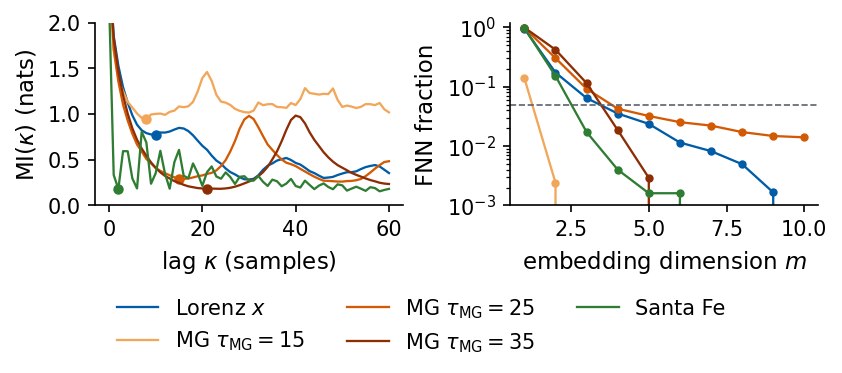

In [36]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained")
    for k in KEYS:
        axs[0].plot(np.arange(61), MI[k][:61], color=COL[k], lw=1.1, label=LABEL[k])
        axs[0].plot(LAG[k], MI[k][LAG[k]], "o", color=COL[k], ms=4)
        axs[1].plot(np.arange(1, 11), FNN[k][0], "-o", color=COL[k], lw=1.1, ms=3)
    axs[0].set_xlabel(r"lag $\kappa$ (samples)"); axs[0].set_ylabel(r"$\mathrm{MI}(\kappa)$ (nats)"); axs[0].set_ylim(0, 2.0)
    axs[1].axhline(FNN_THRESHOLD, color=UJGray, ls="--", lw=0.8)
    axs[1].set_yscale("log"); axs[1].set_ylim(1e-3, 1.2)
    axs[1].set_xlabel("embedding dimension $m$"); axs[1].set_ylabel("FNN fraction")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside lower center", ncol=3, fontsize=10)
    save(fig, "fig_mi_fnn"); plt.show()

The left panel shows $\mathrm{MI}(\kappa)$ with its first minimum marked by a dot, the right panel the fraction of false neighbours of the ratio test against $m$ on a logarithmic scale, with the 5% threshold dashed.

### Lorenz attractor from one coordinate

The figure compares the true state $(x,y,z)$ with three-dimensional delay reconstructions from $x$ alone, with the MI delay $\kappa=10$ and with the ACF delay $\kappa=89$.

### Mutual information from a histogram

The mutual information is estimated from a two-dimensional histogram. The range of the signal is cut into 16 intervals of equal width. For a lag $\kappa$ we take every pair $(s_{k-\kappa},s_k)$ of the record, here $s_k=x(k\Delta t)$ of Lorenz-63, and count how many pairs fall into interval $i$ for the first value and interval $j$ for the second. Divided by the number of pairs, these counts are the joint probabilities $p_{ij}(\kappa)$, and the sums over one index give the probabilities $p_i$ and $p_j$ of a single value. If the two values were independent, the joint probability would factorise, $p_{ij}=p_i\,p_j$, and every logarithm in $\mathrm{MI}(\kappa)$ would vanish. The figure shows the histogram for Lorenz $x$ at a short lag, at the selected delay and at a long lag. The number of intervals is a choice. With the 2400 pairs of the first 2500 samples, 16 intervals per value give $16\times16=256$ cells and about 9 pairs per cell on average, enough to estimate each $p_{ij}$, while many more cells would stay nearly empty.

lag  1: I from the histogram = 1.850 nats, from the JAX estimate = 1.853 nats
lag 10: I from the histogram = 0.780 nats, from the JAX estimate = 0.775 nats
lag 60: I from the histogram = 0.359 nats, from the JAX estimate = 0.355 nats


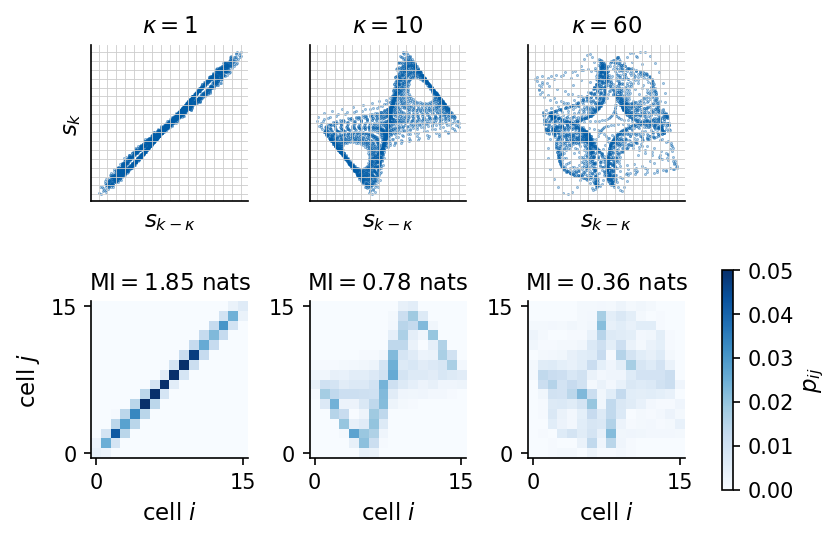

In [37]:
# joint histogram p_ij of the pairs (x_k, x_{k+κ}) of Lorenz x for three delays, and MI(κ) from it
def joint_hist(x, lag, bins=16):
    """p_ij of the pairs (x_k, x_{k+lag}) on a bins x bins grid over the range of x, and I = sum p ln p/(p_i p_j)."""
    edges = np.linspace(x.min(), x.max(), bins + 1)
    H, _, _ = np.histogram2d(x[:-lag], x[lag:], bins=[edges, edges])
    p = H / H.sum()
    pi, pj = p.sum(1, keepdims=True), p.sum(0, keepdims=True)
    nz = p > 0
    return p, float(np.sum(p[nz] * np.log(p[nz] / (pi * pj)[nz]))), edges

x_l = S["lorenz"][:N_FIT]                          # the samples on which the delay is chosen
lags_demo = (1, LAG["lorenz"], 60)
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.6), layout="constrained")
    for col, lag in enumerate(lags_demo):
        p, I_np, edges = joint_hist(x_l, lag)
        ax = axs[0, col]                                   # top: the pairs and the grid of cells
        ax.plot(x_l[:-lag], x_l[lag:], ".", ms=0.8, color=UJBlue, alpha=0.5)
        for e in edges:
            ax.axvline(e, color="0.8", lw=0.4); ax.axhline(e, color="0.8", lw=0.4)
        ax.set_title(rf"$\kappa={lag}$"); ax.set_xlabel(r"$s_{k-\kappa}$"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_aspect("equal")
        ax = axs[1, col]                                   # bottom: fraction of pairs per cell
        im = ax.imshow(p.T, origin="lower", cmap="Blues", vmin=0, vmax=0.05)
        ax.set_title(rf"$\mathrm{{MI}}={I_np:.2f}$ nats"); ax.set_xlabel("cell $i$"); ax.set_xticks([0, 15]); ax.set_yticks([0, 15])
        print(f"lag {lag:2d}: I from the histogram = {I_np:.3f} nats, from the JAX estimate = {MI['lorenz'][lag]:.3f} nats")
        nums.setdefault("mi_demo_lorenz", {})[int(lag)] = I_np
    axs[0, 0].set_ylabel(r"$s_k$"); axs[1, 0].set_ylabel("cell $j$")
    fig.colorbar(im, ax=axs[1, :], shrink=0.9, label="$p_{ij}$")
    save(fig, "fig_mi_histogram"); plt.show()


The whole curve $\mathrm{MI}(\kappa)$ of Lorenz $x$ shows where the three histograms sit. The information shared by $s_{k-\kappa}$ and $s_k$ falls steeply over the first few samples and has its first minimum at $\kappa=10$. It rises again a little and then decays slowly towards zero, so a later lag can have a lower value, but there the coordinates no longer describe one rotation of the attractor.

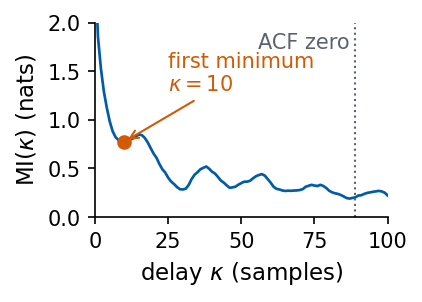

In [38]:
# MI(κ) of Lorenz x against the delay κ: first minimum, the three lags of the histograms, and the ACF zero
T_axis = np.arange(len(MI["lorenz"]))
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(2.7, 1.9), layout="constrained")
    ax.plot(T_axis, MI["lorenz"], color=UJBlue)
    ax.plot(LAG["lorenz"], MI["lorenz"][LAG["lorenz"]], "o", color=DSOrange, ms=6, zorder=3)
    ax.annotate(f"first minimum\n$\\kappa={LAG['lorenz']}$", (LAG["lorenz"], MI["lorenz"][LAG["lorenz"]]),
                xytext=(25, 1.3), fontsize=10, color=DSOrange, arrowprops=dict(arrowstyle="->", color=DSOrange))
    ax.axvline(CT["lorenz"][0], color=UJGray, ls=":", lw=1.0)
    ax.text(CT["lorenz"][0] - 2, 1.9, "ACF zero", ha="right", va="top", fontsize=10, color=UJGray)
    ax.set_xlabel(r"delay $\kappa$ (samples)"); ax.set_ylabel(r"$\mathrm{MI}(\kappa)$ (nats)")
    ax.set_xlim(0, 100); ax.set_ylim(0, 2.0)
    save(fig, "fig_mi_lorenz"); plt.show()


At $\kappa=1$ the pairs lie on the diagonal, because $x$ hardly changes in one sample, and knowing $x_k$ almost fixes $x_{k+1}$. At the selected delay the histogram has spread over a curved band, the pairs still depend on each other but each value adds new information. At $\kappa=60$ the histogram has spread further and $\mathrm{MI}$ has dropped to less than a fifth of its value at $\kappa=1$, although the two values are not yet independent. The two estimates of $\mathrm{MI}$ differ slightly because the JAX function uses the same number of pairs for every lag.

### False nearest neighbours

A delay plot is a projection of the attractor onto $m$ coordinates. If $m$ is too small, the projected orbit crosses itself, and two points from distant parts of the orbit appear next to each other. Adding one more delay coordinate separates them. Such a pair is called a pair of false nearest neighbours. For every point we find its nearest neighbour in $\mathbb R^m$, at distance $r$, and compute how much the added coordinate separates them. The neighbour is false if this extra distance exceeds 15 times $r$ or if the total distance exceeds twice the standard deviation of the signal [M. B. Kennel, R. Brown and H. D. I. Abarbanel, Phys. Rev. A **45**, 3403 (1992), [doi:10.1103/PhysRevA.45.3403](https://doi.org/10.1103/PhysRevA.45.3403)]. The figure shows one such pair for Lorenz $x$, close in the plane $(x_k,x_{k-\kappa})$ and far apart once $x_{k-2\kappa}$ is added.

pair 459, 773: distance in m = 2 is 0.20, in m = 3 it is 17.77 (ratio of the added coordinate 87)


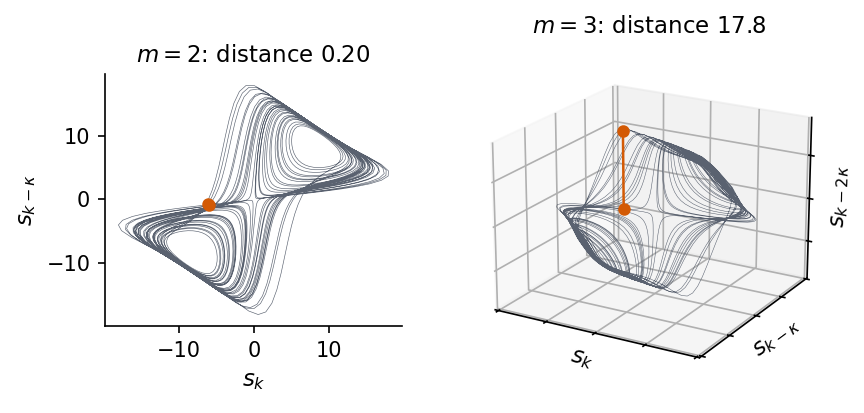

In [39]:
# one false nearest neighbour of Lorenz x: close in m = 2, far apart in m = 3
lag = LAG["lorenz"]
Y3 = delay_embed(x_l, 3, lag)                  # rows (x_n, x_{n-κ}, x_{n-2κ}), n = 2κ .. N-1
Y2 = Y3[:, :2]                                  # the same points in two coordinates
jn, rn = (np.asarray(a) for a in nearest_neighbour(jnp.asarray(Y2), 50))
extra = np.abs(Y3[:, 2] - Y3[jn, 2])
ratio = extra / np.maximum(rn, 1e-12)
a_pt = int(np.argmax(np.where(rn > 0.2, ratio, 0)))     # the most striking false neighbour with r > 0.2
b_pt = int(jn[a_pt])
print(f"pair {a_pt}, {b_pt}: distance in m = 2 is {rn[a_pt]:.2f}, in m = 3 it is "
      f"{np.linalg.norm(Y3[a_pt] - Y3[b_pt]):.2f} (ratio of the added coordinate {ratio[a_pt]:.0f})")
nums["fnn_demo"] = {"r2": float(rn[a_pt]), "r3": float(np.linalg.norm(Y3[a_pt] - Y3[b_pt]))}
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.4))
    ax = fig.add_axes([0.09, 0.2, 0.36, 0.7])
    ax.plot(Y2[:3000, 0], Y2[:3000, 1], color=UJGray, lw=0.3)
    ax.plot(*Y2[[a_pt, b_pt]].T, "o", color=DSOrange, ms=5)
    ax.set_xlabel("$s_k$"); ax.set_ylabel(r"$s_{k-\kappa}$"); ax.set_title(f"$m=2$: distance {rn[a_pt]:.2f}")
    ax3 = fig.add_axes([0.5, 0.0, 0.5, 1.0], projection="3d")
    ax3.plot(*Y3[:3000].T, color=UJGray, lw=0.25)
    ax3.plot(*Y3[[a_pt, b_pt]].T, "o-", color=DSOrange, ms=5, lw=1.2)
    ax3.set_title(f"$m=3$: distance {np.linalg.norm(Y3[a_pt] - Y3[b_pt]):.1f}", pad=-4)
    ax3.set_xticklabels([]); ax3.set_yticklabels([]); ax3.set_zticklabels([])
    for setter, lab in zip((ax3.set_xlabel, ax3.set_ylabel, ax3.set_zlabel), ("$s_k$", r"$s_{k-\kappa}$", r"$s_{k-2\kappa}$")):
        setter(lab, labelpad=-12)
    ax3.view_init(elev=20, azim=-60)
    save(fig, "fig_fnn_demo"); plt.show()


The pair marked in orange is a typical false neighbour. In two coordinates the orbit passes through the same region from two different lobes, and the two points look close. The third coordinate shows that they belong to different parts of the attractor. Counting such pairs for every point gives the fraction of false neighbours, and the embedding dimension is the first $m$ at which it falls below 5 per cent.

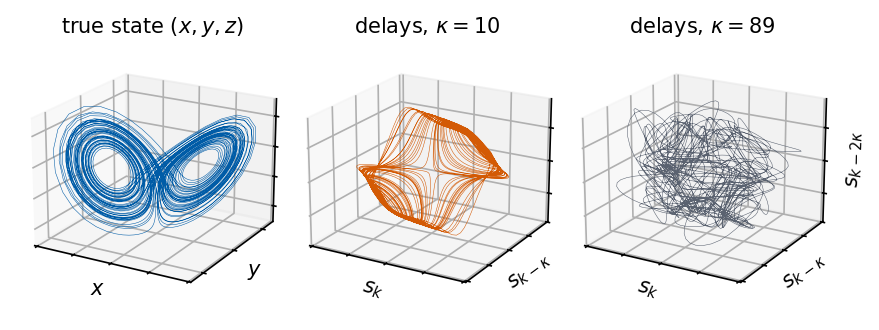

In [40]:
l_mi, l_acf = LAG["lorenz"], CT["lorenz"][0]
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.1))
    panels = [(lor_states[:, :3], "true state $(x, y, z)$", ("$x$", "$y$", "$z$")),
              (delay_embed(S["lorenz"], 3, l_mi), rf"delays, $\kappa={l_mi}$", ("$s_k$", r"$s_{k-\kappa}$", r"$s_{k-2\kappa}$")),
              (delay_embed(S["lorenz"], 3, l_acf), rf"delays, $\kappa={l_acf}$", ("$s_k$", r"$s_{k-\kappa}$", r"$s_{k-2\kappa}$"))]
    for c, (Y, title, labs) in enumerate(panels):
        ax = fig.add_axes([c / 3, 0.0, 1 / 3, 0.9], projection="3d")
        ax.plot(*Y[:3000].T, lw=0.25, color=UJBlue if c == 0 else DSOrange if c == 1 else UJGray)
        ax.set_title(title, fontsize=10, pad=-2)
        ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
        for setter, lab in zip((ax.set_xlabel, ax.set_ylabel, ax.set_zlabel), labs):
            setter(lab, labelpad=-12, fontsize=10)
        ax.view_init(elev=20, azim=-60)
    save(fig, "fig_takens_lorenz"); plt.show()

With $\kappa=10$ the two lobes and the switching between them are clearly visible, a smoothly deformed image of the attractor. With $\kappa=89$ the three coordinates are almost unrelated within the chaotic motion and the reconstruction is a tangle in which the geometry is lost.

<hr/>
## 7. Deterministic chaos in one dimension

### Phase space, flow and dissipation

A deterministic system is defined by a state $\mathbf u$ in a phase space and a rule that maps the present state to the future one. For a flow the rule is a differential equation $\dot{\mathbf u}=\mathbf F(\mathbf u)$, for a map it is $\mathbf u_{n+1}=\mathbf f(\mathbf u_n)$. A small volume $V$ of initial conditions changes under the flow at the rate $\dot V/V=\nabla\cdot\mathbf F$. For Lorenz-63 the divergence is constant, $\nabla\cdot\mathbf F=-(\sigma+1+\beta)=-13.667$, so every volume shrinks by the factor $e^{-13.667}$ per time unit. A system that contracts volumes is called dissipative. Its long-time motion lies on a set of zero volume, the attractor, which can still have a complicated, fractal structure. Chaos on such an attractor needs two ingredients, which the simplest example already shows.

### Logistic map

The logistic map [R. M. May, Nature **261**, 459 (1976), [doi:10.1038/261459a0](https://doi.org/10.1038/261459a0)]
$$
x_{n+1}=f(x_n)=r\,x_n(1-x_n),\qquad x_n\in[0,1],\ 0<r\le4,
$$
is a model of a population with limited resources. Two nearby initial conditions $x_0$ and $x_0+\delta_0$ separate after $n$ steps by $\delta_n\approx\delta_0\prod_{k<n}|f'(x_k)|$, by the chain rule. The Lyapunov exponent is the average logarithmic growth rate per step,
$$
\lambda=\lim_{N\to\infty}\frac1N\sum_{n=0}^{N-1}\ln|f'(x_n)|=\big\langle\ln|r(1-2x_n)|\big\rangle .
$$
$\lambda<0$ means that nearby orbits approach each other (a stable fixed point or cycle), $\lambda>0$ that they separate exponentially (chaos). For $r=4$ the substitution $x=\sin^2(\pi\theta)$ turns the map into $\theta_{n+1}=2\theta_n$ mod 1, which doubles every distance, so $\lambda=\ln2$. We iterate the map in JAX for 1201 values of $r$ at once with `vmap`, discard 1000 transient steps, keep 300 iterates for the bifurcation diagram and average $\ln|f'|$ over 20000 steps.

lambda(r=4) = 0.6931 (200000 iterates), ln 2 = 0.6931
first r on the grid with lambda > 1e-3: r = 3.570


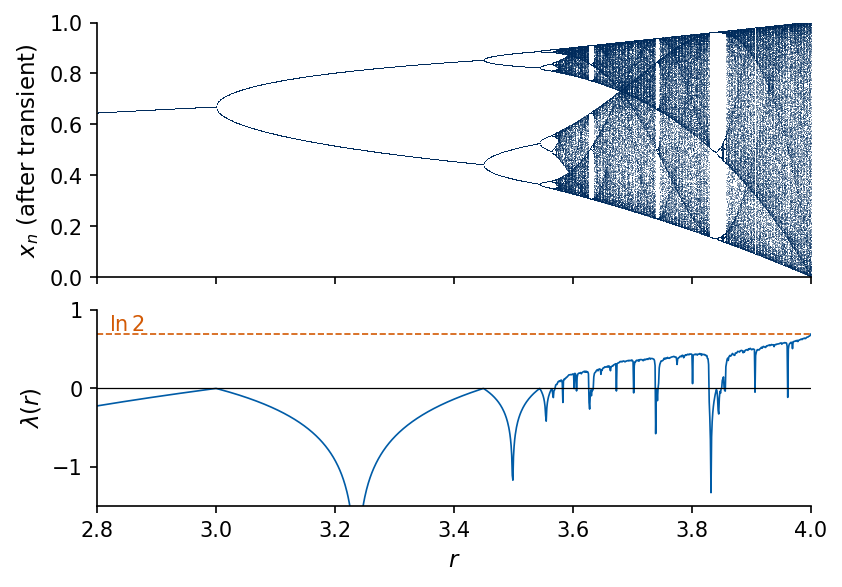

In [41]:
@partial(jax.jit, static_argnames=("n_transient", "n_keep", "n_lyap"))
def logistic_orbit_and_lyap(r, x0=0.3, n_transient=1000, n_keep=300, n_lyap=20000):
    """Iterate x_{n+1} = r x_n (1 - x_n). Returns the last n_keep iterates after the transient and
    lambda = (1/n_lyap) sum_n ln |f'(x_n)| = <ln |r (1 - 2 x_n)|> along the orbit."""
    f = lambda x: r * x * (1.0 - x)
    x = jax.lax.fori_loop(0, n_transient, lambda i, x: f(x), x0)
    def body(x, _):
        return f(x), (x, jnp.log(jnp.abs(r * (1.0 - 2.0 * x))))
    _, (orbit, logd) = jax.lax.scan(body, x, None, length=n_lyap)
    return orbit[-n_keep:], logd.mean()

r_grid = jnp.linspace(2.8, 4.0, 1201)
orbits, lyap_r = jax.vmap(lambda r: logistic_orbit_and_lyap(r))(r_grid)
orbits, lyap_r = np.asarray(orbits), np.asarray(lyap_r)
lam4 = float(logistic_orbit_and_lyap(4.0, n_lyap=200000)[1])
print(f"lambda(r=4) = {lam4:.4f} (200000 iterates), ln 2 = {np.log(2):.4f}")
r_onset = float(r_grid[np.argmax(lyap_r > 1e-3)])
print(f"first r on the grid with lambda > 1e-3: r = {r_onset:.3f}")
nums["logistic_lambda_r4"] = lam4; nums["logistic_r_onset"] = r_onset

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 3.8), sharex=True, layout="constrained",
                            gridspec_kw=dict(height_ratios=[1.3, 1]))
    rr = np.repeat(np.asarray(r_grid), orbits.shape[1])
    axs[0].plot(rr, orbits.ravel(), ",", color=UJNavy, alpha=0.4, rasterized=True)
    axs[0].set_ylabel("$x_n$ (after transient)"); axs[0].set_ylim(0, 1)
    axs[1].plot(np.asarray(r_grid), lyap_r, color=UJBlue, lw=0.8)
    axs[1].axhline(0, color="k", lw=0.6); axs[1].axhline(np.log(2), color=DSOrange, ls="--", lw=0.8)
    axs[1].text(2.82, np.log(2) + 0.05, r"$\ln 2$", color=DSOrange, fontsize=10)
    axs[1].set_ylim(-1.5, 1.0); axs[1].set_xlabel("$r$"); axs[1].set_ylabel(r"$\lambda(r)$"); axs[1].set_xlim(2.8, 4.0)
    save(fig, "fig_logistic_lyapunov"); plt.show()

The upper panel is the bifurcation diagram, the set of values visited after the transient for each $r$. A single fixed point splits at $r=3$ into a cycle of period two, then four, and so on, and the cascade ends near $r\approx3.57$, beyond which the orbits fill whole intervals, interrupted by windows of periodic motion. The lower panel shows $\lambda(r)$ on the same $r$ axis. $\lambda$ touches zero at every period doubling, stays negative in the periodic windows, and is positive where the diagram is filled. The first grid point with $\lambda>10^{-3}$ is $r=3.570$, and at $r=4$ we obtain $\lambda=0.6931=\ln2$.

### Stretching and folding

At $r=4$ we follow two orbits that start $\delta_0=10^{-10}$ apart.

separation reaches 0.1 after n = 31 iterates; fitted growth rate 0.674 per iterate (ln 2 = 0.693); ln(0.1/d0)/ln 2 = 29.9
separation stays below 0.01 for the first 28 iterates


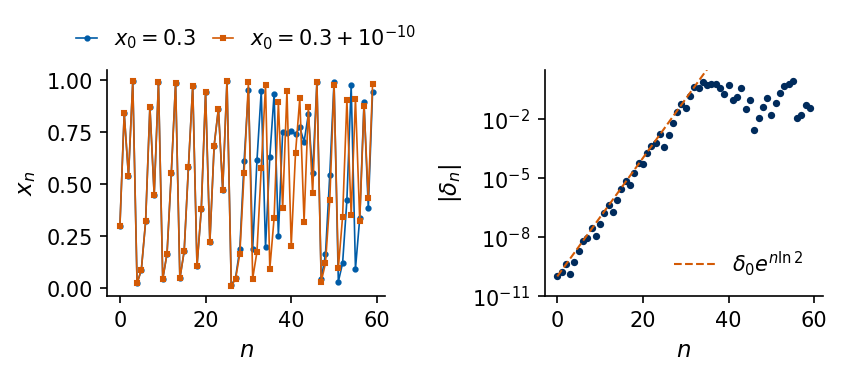

In [42]:
def logistic_orbit(x0, r=4.0, n=60):
    return np.asarray(jax.lax.scan(lambda x, _: (r * x * (1 - x), x), x0, None, length=n)[1])
d0 = 1e-10
a, b = logistic_orbit(0.3), logistic_orbit(0.3 + d0)
sep = np.abs(a - b)
n_sat = int(np.argmax(sep > 0.1))
slope = np.polyfit(np.arange(5, n_sat - 3), np.log(sep[5:n_sat - 3]), 1)[0]
print(f"separation reaches 0.1 after n = {n_sat} iterates; fitted growth rate {slope:.3f} per iterate (ln 2 = {np.log(2):.3f});"
      f" ln(0.1/d0)/ln 2 = {np.log(0.1 / d0) / np.log(2):.1f}")
nums["logistic_sep_n"] = n_sat
nums["logistic_rate"] = float(slope)
nums["logistic_close_n"] = int(np.argmax(sep > 0.01))       # first iterate with a separation above 0.01
nums["logistic_estimate"] = float(np.log(0.1 / d0) / np.log(2))
print(f"separation stays below 0.01 for the first {nums['logistic_close_n']} iterates")
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained")
    axs[0].plot(a, "-o", color=UJBlue, ms=2, lw=0.8, label="$x_0=0.3$")
    axs[0].plot(b, "-s", color=DSOrange, ms=2, lw=0.8, label="$x_0=0.3+10^{-10}$")
    axs[0].set_xlabel("$n$"); axs[0].set_ylabel("$x_n$"); axs[0].legend(fontsize=10, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 1.0), handlelength=1.0, columnspacing=0.8)
    n = np.arange(len(sep))
    axs[1].semilogy(n, sep, "o", color=UJNavy, ms=2.5)
    axs[1].semilogy(n, d0 * 2.0 ** n, "--", color=DSOrange, lw=1.0, label=r"$\delta_0 e^{n\ln 2}$")
    axs[1].set_ylim(1e-11, 3); axs[1].set_xlabel("$n$"); axs[1].set_ylabel(r"$|\delta_n|$"); axs[1].legend(fontsize=10)
    save(fig, "fig_logistic_separation"); plt.show()

The orbits are indistinguishable for about 25 steps and unrelated afterwards. The separation $|\delta_n|$ (right panel) grows like $\delta_0e^{n\ln2}$ (fitted rate 0.674 per step) and saturates when it reaches the size of the interval, after 31 steps, close to the estimate $\ln(0.1/\delta_0)/\ln2=29.9$ for reaching 0.1. The two ingredients of chaos are visible in the map itself. Where $|f'|>1$ the map **stretches** distances, which produces the sensitivity to initial conditions. The interval $[0,1]$ is nevertheless mapped into itself, because the parabola **folds** the stretched interval back onto itself, which keeps the motion bounded. Stretching without folding would only give an orbit escaping to infinity, folding without stretching a stable orbit. The same mechanism acts in the Lorenz attractor, which stretches along the unstable direction, contracts along the strongly stable one, and folds the two lobes into each other.

<hr/>
## 8. Lyapunov spectrum of a flow

### Variational equation and the Benettin algorithm

In $n$ dimensions a small perturbation $\delta\mathbf u$ of a trajectory $\mathbf u(t)$ obeys the variational equation
$$
\delta\dot{\mathbf u}=J(\mathbf u(t))\,\delta\mathbf u,\qquad J_{ij}=\frac{\partial F_i}{\partial u_j},
$$
with the Jacobian evaluated along the trajectory. A small sphere of perturbations becomes an ellipsoid whose semi-axes grow as $e^{\lambda_it}$, and the rates $\lambda_1\ge\lambda_2\ge\dots\ge\lambda_n$ are the Lyapunov exponents. By Oseledets' multiplicative ergodic theorem [V. I. Oseledets, Trans. Moscow Math. Soc. **19**, 197 (1968), [mathnet.ru/eng/mmo214](https://www.mathnet.ru/eng/mmo214)] they are the same for almost all initial conditions on the attractor. Their sum is the average volume contraction rate, $\sum_i\lambda_i=\langle\nabla\cdot\mathbf F\rangle$, and a bounded flow that is not a fixed point has one zero exponent, the direction along the trajectory.

Benettin et al. computed the whole spectrum by following $k$ perturbation vectors at once [G. Benettin, L. Galgani, A. Giorgilli and J.-M. Strelcyn, Meccanica **15**, 9 (1980), [doi:10.1007/BF02128236](https://doi.org/10.1007/BF02128236)]. Left alone, all vectors would turn towards the most unstable direction. Every interval $T_r$ we therefore orthonormalise them by a QR decomposition, $V=QR$, continue with the columns of $Q$, and accumulate the logarithms of the diagonal of $R$, which measure the growth of the successive volumes,
$$
\lambda_i=\frac{1}{K\,T_r}\sum_{j=1}^{K}\ln|R^{(j)}_{ii}| .
$$

### Lorenz-63 spectrum

Our signal is generated by the RK4 map $\boldsymbol\Phi_h$ with $h=0.01$, and we compute the exponents of this map. Automatic differentiation of one RK4 step with `jax.jacfwd` gives the $3\times3$ matrix $D\boldsymbol\Phi_h$ that propagates the perturbations, with QR every $T_r=0.1$ time units for 20000 time units. Ten independent segments of 2000 time units give the standard errors.

In [43]:
H = 0.01                                              # RK4 step of the Lorenz generator
lorenz_map = lambda u: rk4_step(lorenz_rhs, u, H)     # one RK4 step, R^3 -> R^3
jac_map = jax.jacfwd(lorenz_map)                      # its Jacobian, (3, 3)

@partial(jax.jit, static_argnums=(2, 3))
def benettin_lorenz(u, Q, n_blocks, steps_per_block=10):
    """Benettin QR: propagate the orthonormal frame Q (3, 3) with the Jacobian of the RK4 map for
    `steps_per_block` steps, re-orthonormalise by QR, record ln |R_ii|. Returns final (u, Q) and logs (n_blocks, 3)."""
    def block(carry, _):
        u, Q = carry
        def step(c, _):
            u, Q = c
            return (lorenz_map(u), jac_map(u) @ Q), None
        (u, Q), _ = jax.lax.scan(step, (u, Q), None, length=steps_per_block)
        Q, R = jnp.linalg.qr(Q)
        return (u, Q), jnp.log(jnp.abs(jnp.diag(R)))
    return jax.lax.scan(block, (u, Q), None, length=n_blocks)

T_BLOCK = 10 * H                                      # time between QR steps (0.1 time units)
n_blocks = 200000                                     # 20000 time units
t0 = time.time()
(_, _), logs_lor = benettin_lorenz(jnp.asarray(lor_states[-1]), jnp.eye(3), n_blocks)
logs_lor = np.asarray(logs_lor)
lam_lor = logs_lor.sum(0) / (n_blocks * T_BLOCK)
seg = logs_lor.reshape(10, -1, 3).sum(1) / (n_blocks // 10 * T_BLOCK)      # 10 independent segments of 2000 time units
err_lor = seg.std(0, ddof=1) / np.sqrt(10)
print(f"Benettin, T = {n_blocks*T_BLOCK:.0f} time units ({time.time()-t0:.1f} s)")
for i in range(3):
    print(f"  lambda_{i+1} = {lam_lor[i]: .4f} +- {err_lor[i]:.4f} per time unit")
print(f"  sum = {lam_lor.sum():.4f}; -(sigma + 1 + beta) = {-(sigma + 1 + beta):.4f}")
# the sum of exponents of the RK4 map is the time average of ln |det DPhi| / h
dets = jax.vmap(lambda u: jnp.log(jnp.abs(jnp.linalg.det(jac_map(u)))))(jnp.asarray(lor_states))
print(f"  <ln|det DPhi_h|>/h along the stored trajectory = {float(dets.mean()) / H:.4f}")
nums["lorenz_lyap"] = lam_lor.tolist(); nums["lorenz_lyap_err"] = err_lor.tolist(); nums["lorenz_lyap_sum"] = float(lam_lor.sum())

Benettin, T = 20000 time units (1.5 s)
  lambda_1 =  0.9068 +- 0.0009 per time unit
  lambda_2 =  0.0001 +- 0.0001 per time unit
  lambda_3 = -14.5734 +- 0.0009 per time unit
  sum = -13.6666; -(sigma + 1 + beta) = -13.6667


  <ln|det DPhi_h|>/h along the stored trajectory = -13.6666


We obtain $\lambda_1=0.907\pm0.001$, $\lambda_2=0.0001\pm0.0001$ and $\lambda_3=-14.573\pm0.001$ per time unit. The sum $-13.6666$ matches $-(\sigma+1+\beta)=-13.6667$, and the average of $\ln|\det D\boldsymbol\Phi_h|/h$ along the trajectory gives the same number, which tests the computation independently of the QR procedure. The zero exponent is resolved to $10^{-4}$.

### Mackey–Glass as a high-dimensional map

The state of the delay equation is the history segment, which the RK4 scheme stores as the vector $(x_{i-L},\dots,x_i)\in\mathbb R^{L+1}$, with $L=150$, 250 and 350 for $\tau_{\rm MG}=15$, 25 and 35. One RK4 step is a map of this vector, and the same Benettin algorithm applies to it. A full Jacobian of size $351\times351$ is unnecessary, because we only need its action on $k$ vectors. `jax.jvp` computes the product of the Jacobian with a tangent vector at the cost of about one extra step, and `vmap` does this for all $k=12$ vectors. We orthonormalise once per time unit (10 steps), discard 5000 time units and average over 200000 time units. We first check that the map, written as a separate function, reproduces the generator output.

### The linearised flow and its eigenproblem

The Benettin algorithm never forms the matrix that the exponents describe. We now construct it explicitly for short times. The linearised flow $M_t$ maps a small initial error to the error at time $t$,
$$
\delta(t)=M_t\,\delta_0,\qquad (M_t)_{ij}=\frac{\partial x_i(t)}{\partial x_j(0)} .
$$
With the RK4 map $\mathbf x_{n+1}=\Phi(\mathbf x_n)$ the chain rule gives the product of the step Jacobians along the trajectory, $M_t=J(\mathbf x_{n-1})\cdots J(\mathbf x_1)J(\mathbf x_0)$ for $t=nh$. The squared length of the error is a quadratic form,
$$
|\delta(t)|^2=\delta_0^{\top}\tilde M_t\,\delta_0,\qquad \tilde M_t\coloneqq M_t^{\top}M_t ,
$$
and $\tilde M_t$ is symmetric with non-negative eigenvalues, $\tilde M_t\mathbf v_i=\sigma_i^2\mathbf v_i$. An initial error $\varepsilon\mathbf v_i$ has length $\varepsilon\sigma_i$ at time $t$, so $\sigma_i$ is its growth factor, and the finite-time exponents are $\lambda_i(t)=\ln\sigma_i(t)/t$. As $t$ grows they approach the Lyapunov exponents. We check three things. The product of step Jacobians must equal the derivative of the whole map computed by automatic differentiation. The finite-time exponents must approach the Benettin values. Their sum must equal the divergence of the Lorenz flow, $\nabla\cdot\mathbf F=-(\sigma+1+\beta)=-41/3$, because $\sigma_1\sigma_2\sigma_3=|\det M_t|=e^{-41t/3}$ for any trajectory.

In [44]:
# explicit linearised flow M_t of Lorenz-63: product of RK4 step Jacobians, and the eigenproblem of M_t^T M_t
@partial(jax.jit, static_argnums=1)
def linearised_flow(u0, n_steps):
    """M_t = J(x_{n-1}) ... J(x_0) for t = n_steps * H, and ln|det M_t| summed over the RK4 steps."""
    def step(c, _):
        u, M, logdet = c
        J = jac_map(u)
        return (lorenz_map(u), J @ M, logdet + jnp.log(jnp.abs(jnp.linalg.det(J)))), None
    (u, M, logdet), _ = jax.lax.scan(step, (u0, jnp.eye(3), 0.0), None, length=n_steps)
    return M, logdet

# check 1: the product of step Jacobians equals the derivative of the composed map (automatic differentiation)
u_test = jnp.asarray(lor_states[-1])
flow_50 = lambda u: jax.lax.fori_loop(0, 50, lambda i, v: lorenz_map(v), u)
M_prod, _ = linearised_flow(u_test, 50)
print("t = 0.5: max |product of step Jacobians - jacfwd of the flow| =",
      float(jnp.abs(M_prod - jax.jacfwd(flow_50)(u_test)).max()))

# check 2 and 3: finite-time exponents from the eigenvalues of M_t^T M_t, averaged over 100 starting points
starts = jnp.asarray(lor_states[::40][:100])
FTLE = {}
for t_ft in (1.0, 2.0, 5.0, 10.0):
    n = int(round(t_ft / H))
    Ms, logdets = jax.vmap(lambda u: linearised_flow(u, n))(starts)
    sig2 = np.sort(np.asarray(jnp.linalg.eigvalsh(jnp.swapaxes(Ms, 1, 2) @ Ms)), axis=1)[:, ::-1]   # sigma_i^2, descending
    lam12 = 0.5 * np.log(sig2[:, :2]) / t_ft
    lam3 = np.asarray(logdets) / t_ft - lam12.sum(1)          # smallest exponent from the determinant
    FTLE[t_ft] = np.column_stack([lam12, lam3]).mean(0)
    print(f"t = {t_ft:4.1f}: lambda(t) = ({FTLE[t_ft][0]:.3f}, {FTLE[t_ft][1]:.3f}, {FTLE[t_ft][2]:.3f}),"
          f"  sum = {FTLE[t_ft].sum():.4f}")
print(f"Benettin, long run: ({lam_lor[0]:.3f}, {lam_lor[1]:.4f}, {lam_lor[2]:.3f}),  sum = {lam_lor.sum():.4f}"
      f"  | divergence -(sigma + 1 + beta) = {-(10 + 1 + 8/3):.4f}")
nums["ftle_lorenz"] = {str(t): [float(v) for v in FTLE[t]] for t in FTLE}


t = 0.5: max |product of step Jacobians - jacfwd of the flow| = 4.440892098500626e-16


t =  1.0: lambda(t) = (1.935, -0.794, -14.807),  sum = -13.6666


t =  2.0: lambda(t) = (1.375, -0.362, -14.679),  sum = -13.6666


t =  5.0: lambda(t) = (1.083, -0.127, -14.623),  sum = -13.6666


t = 10.0: lambda(t) = (0.998, -0.062, -14.602),  sum = -13.6666
Benettin, long run: (0.907, 0.0001, -14.573),  sum = -13.6666  | divergence -(sigma + 1 + beta) = -13.6667


The product of step Jacobians agrees with the derivative of the composed map to round-off, so $M_t$ is the matrix of the definition. The sum of the three finite-time exponents equals $-41/3$ at every time, as the volume contraction of the Lorenz flow requires, and the long Benettin run gives the same sum. The finite-time exponents move towards the Benettin values as $t$ grows, slowly, because a finite stretch of trajectory visits only part of the attractor and the average over starting points converges only as $t\to\infty$. For long times the smallest eigenvalue of $\tilde M_t$, of order $e^{-2\cdot14.6\,t}$, falls below the round-off of the largest one, of order $e^{2\cdot0.9\,t}$, and can no longer be computed from $\tilde M_t$. This is why the smallest exponent is taken here from the determinant, and why the Benettin algorithm re-orthonormalises the tangent vectors at short intervals instead of forming $M_t$ for long times.

In [45]:
def mg_step_factory(tau, h=0.1, beta=0.2, gamma=0.1, n=10):
    """The RK4 step of the Mackey-Glass generator as a map of the delay window
    buf = (x_{i-lag}, ..., x_i) in R^{lag+1}, lag = tau/h. The same arithmetic as in `mackey_glass`."""
    f = lambda x, xd: beta * xd / (1.0 + xd ** n) - gamma * x
    def step(buf):
        x, xd0, xd1 = buf[-1], buf[0], buf[1]
        xdh = 0.5 * (xd0 + xd1)
        k1 = f(x, xd0); k2 = f(x + 0.5 * h * k1, xdh); k3 = f(x + 0.5 * h * k2, xdh); k4 = f(x + h * k3, xd1)
        return jnp.concatenate([buf[1:], (x + h / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4))[None]])
    return step

# check: iterating the map from the constant history reproduces the generator output
step25 = mg_step_factory(25)
buf = jnp.full(251, 1.2)
xs_check = np.asarray(jax.lax.scan(lambda b, _: (step25(b), step25(b)[-1]), buf, None, length=3000 + 200 * 10)[1])
orbit = np.concatenate([np.full(251, 1.2), xs_check])          # same indexing as in mackey_glass
print("max |map orbit - mackey_glass(25)| over the first 200 samples:", np.abs(orbit[3000::10][:200] - S["mg25"][:200]).max())

max |map orbit - mackey_glass(25)| over the first 200 samples: 0.0


In [46]:
K_EXP = 12                                             # number of leading exponents
MG_TRANSIENT, MG_T = 5000, 200000                       # time units

def benettin_mg(tau, key, k=K_EXP):
    step = mg_step_factory(tau)
    lag = int(round(tau / 0.1))
    tangent = jax.vmap(lambda buf, v: jax.jvp(step, (buf,), (v,))[1], in_axes=(None, 1), out_axes=1)

    @partial(jax.jit, static_argnums=2)
    def run(buf, V, n_blocks):
        def block(carry, _):
            buf, V = carry
            def inner(c, _):
                buf, V = c
                return (step(buf), tangent(buf, V)), None        # state and k tangent vectors, 10 steps = 1 time unit
            (buf, V), _ = jax.lax.scan(inner, (buf, V), None, length=10)
            Q, R = jnp.linalg.qr(V)
            return (buf, Q), jnp.log(jnp.abs(jnp.diag(R)))
        return jax.lax.scan(block, (buf, V), None, length=n_blocks)

    V0 = jnp.linalg.qr(jax.random.normal(key, (lag + 1, k)))[0]
    (buf, V), _ = run(jnp.full(lag + 1, 1.2), V0, MG_TRANSIENT)
    (buf, V), logs = run(buf, V, MG_T)
    return np.asarray(logs)                                       # (MG_T, k), one row per time unit

LYAP_MG, ERR_MG, LOGS_MG = {}, {}, {}
for k, tau in (("mg15", 15), ("mg25", 25), ("mg35", 35)):
    t0 = time.time()
    LOGS_MG[k] = benettin_mg(tau, jax.random.key(tau))
    LYAP_MG[k] = LOGS_MG[k].mean(0)                               # per time unit (blocks of 1 time unit)
    seg = LOGS_MG[k].reshape(10, -1, K_EXP).mean(1)
    ERR_MG[k] = seg.std(0, ddof=1) / np.sqrt(10)
    print(f"{LABEL[k]:22s} lag = {int(tau/0.1)}, state dimension {int(tau/0.1)+1}, {time.time()-t0:.1f} s")
    print("   lambda_i     :", np.round(LYAP_MG[k][:6], 5))
    print("   standard err.:", np.round(ERR_MG[k][:6], 5))
nums["mg_lyap"] = {k: LYAP_MG[k].tolist() for k in LYAP_MG}
nums["mg_lyap_err"] = {k: ERR_MG[k].tolist() for k in ERR_MG}

MG $\tau_{\rm MG}=15$  lag = 150, state dimension 151, 7.1 s
   lambda_i     : [-0.      -0.01269 -0.02695 -0.07977 -0.09197 -0.10121]
   standard err.: [1.e-05 1.e-05 2.e-05 0.e+00 1.e-05 1.e-05]


MG $\tau_{\rm MG}=25$  lag = 250, state dimension 251, 12.7 s
   lambda_i     : [ 0.00995  0.      -0.00561 -0.02753 -0.0385  -0.04679]
   standard err.: [2.1e-04 1.0e-05 2.2e-04 2.8e-04 2.9e-04 2.4e-04]


MG $\tau_{\rm MG}=35$  lag = 350, state dimension 351, 14.0 s
   lambda_i     : [ 0.00294  0.00026 -0.00019 -0.00726 -0.01869 -0.02361]
   standard err.: [0.00036 0.00017 0.00022 0.00017 0.00029 0.00013]


For $\tau_{\rm MG}=15$ the leading exponent is zero within $10^{-5}$ and all others are negative, as for a stable periodic orbit. For $\tau_{\rm MG}=25$ we find $\lambda_1=0.0099\pm0.0002$ per time unit and a second exponent equal to zero, the flow direction. For $\tau_{\rm MG}=35$ we obtain $\lambda_1=0.0029\pm0.0004$, and the next two exponents are zero within their errors. The chaos of $\tau_{\rm MG}=35$ is weaker in $\lambda_1$ than that of $\tau_{\rm MG}=25$, although its attractor is larger (Section 9).

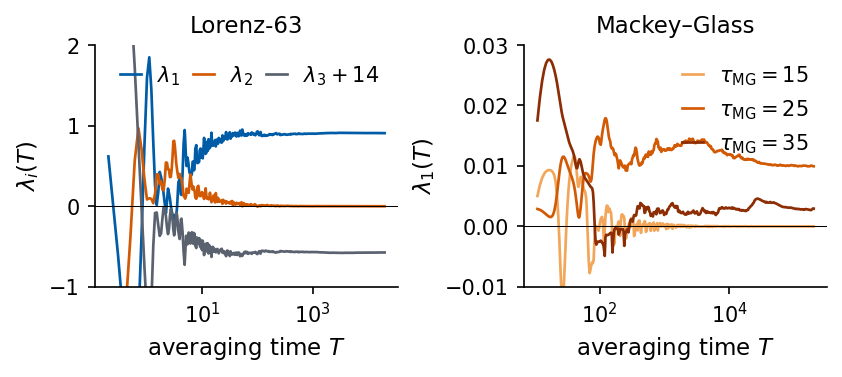

In [47]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained")
    T = np.arange(1, n_blocks + 1) * T_BLOCK
    run_lor = np.cumsum(logs_lor, axis=0) / T[:, None]
    sl = np.unique(np.logspace(0, np.log10(n_blocks) - 1e-9, 400).astype(int))
    axs[0].semilogx(T[sl], run_lor[sl, 0], color=UJBlue, label=r"$\lambda_1$")
    axs[0].semilogx(T[sl], run_lor[sl, 1], color=DSOrange, label=r"$\lambda_2$")
    axs[0].semilogx(T[sl], (run_lor[sl, 2] + 14.0) , color=UJGray, label=r"$\lambda_3+14$")
    axs[0].axhline(0, color="k", lw=0.5)
    axs[0].set_ylim(-1.0, 2.0); axs[0].set_xlabel("averaging time $T$"); axs[0].set_ylabel(r"$\lambda_i(T)$")
    axs[0].set_title("Lorenz-63"); axs[0].legend(fontsize=10, loc="upper right", ncol=3, handlelength=1.0, columnspacing=0.6)
    Tm = np.arange(1, MG_T + 1)
    slm = np.unique(np.logspace(1, np.log10(MG_T) - 1e-9, 400).astype(int))
    for k, tau in (("mg15", 15), ("mg25", 25), ("mg35", 35)):
        run = np.cumsum(LOGS_MG[k][:, 0]) / Tm
        axs[1].semilogx(Tm[slm], run[slm], color=COL[k], label=rf"$\tau_{{\rm MG}}={tau}$")
    axs[1].axhline(0, color="k", lw=0.5); axs[1].set_ylim(-0.01, 0.03)
    axs[1].set_xlabel("averaging time $T$"); axs[1].set_ylabel(r"$\lambda_1(T)$"); axs[1].set_title("Mackey–Glass")
    axs[1].legend(fontsize=10, loc="upper right", ncol=1, handlelength=1.0)
    save(fig, "fig_lyap_convergence"); plt.show()

The convergence plot shows the running averages $\lambda_i(T)=\frac1T\sum\ln|R_{ii}|$ against the averaging time $T$ on a logarithmic axis (for Lorenz the third exponent is shifted by 14 to fit the scale). Lorenz converges within about 100 time units. The Mackey–Glass exponents need $10^4$ time units, a hundred Lyapunov times of $\tau_{\rm MG}=25$, and the estimates for $\tau_{\rm MG}=35$ still wander by about $\pm0.001$ after $10^4$ time units.

### Exponents from data

For the laser we know no equations, and the exponents must come from the delay vectors. Rosenstein, Collins and De Luca estimate $\lambda_1$ directly [M. T. Rosenstein, J. J. Collins and C. J. De Luca, Physica D **65**, 117 (1993), [doi:10.1016/0167-2789(93)90009-P](https://doi.org/10.1016/0167-2789(93)90009-P)]. For each $\mathbf y_i$ we take its nearest neighbour $\mathbf y_{j(i)}$ outside the Theiler window and follow the distance of the two points $k$ steps later,
$$
\langle\ln d(k)\rangle=\frac{1}{N_{\rm pairs}}\sum_i\ln\big\|\mathbf y_{i+k}-\mathbf y_{j(i)+k}\big\| .
$$
In the range where the distance grows exponentially the curve is a straight line with slope $\lambda_1$ per sample. Before the range the pairs align with the unstable direction, after it the distance saturates at the size of the attractor. We first apply the method to Lorenz $x$, where we know the answer, and then to Santa Fe, with the embeddings of Section 6.

In [48]:
def rosenstein_curve(x, m, lag, w, k_max):
    """<ln d(k)> = mean over i of ln ||y_{i+k} - y_{j(i)+k}||, j(i) the nearest neighbour of y_i with |i - j| > w."""
    Y = delay_embed(x, m, lag)
    n = len(Y)
    j, _ = nearest_neighbour(jnp.asarray(Y), w)
    j = np.asarray(j); i = np.arange(n)
    out = []
    for k in range(k_max + 1):
        ok = (i + k < n) & (j + k < n)
        d = np.linalg.norm(Y[i[ok] + k] - Y[j[ok] + k], axis=1)
        out.append(np.log(d[d > 0]).mean())
    return np.array(out)

def slope(curve, k0, k1):
    return np.polyfit(np.arange(k0, k1 + 1), curve[k0:k1 + 1], 1)[0]

ROS = {}
ROS["lorenz"] = rosenstein_curve(S["lorenz"], EMB_M["lorenz"], LAG["lorenz"], 50, 150)
ROS["santafe"] = rosenstein_curve(S["santafe"], EMB_M["santafe"], LAG["santafe"], 50, 150)
FIT = {"lorenz": (25, 100), "santafe": (8, 40)}
lam_ros = {k: slope(ROS[k], *FIT[k]) for k in ROS}
print(f"Lorenz (m = {EMB_M['lorenz']}, κ = {LAG['lorenz']}): slope over k = 25..100 = {lam_ros['lorenz']:.4f} per sample"
      f" = {lam_ros['lorenz']/DT['lorenz']:.3f} per time unit (Benettin {lam_lor[0]:.3f})")
for k0, k1 in ((0, 25), (0, 50), (25, 100), (50, 100)):
    print(f"   Lorenz fit k = {k0:3d}..{k1:3d}: {slope(ROS['lorenz'], k0, k1)/DT['lorenz']:.3f} per time unit")
print(f"Santa Fe (m = {EMB_M['santafe']}, κ = {LAG['santafe']}): slope over k = 8..40 = {lam_ros['santafe']:.4f} per sample")
for k0, k1 in ((0, 8), (0, 40), (8, 40), (0, 150)):
    print(f"   Santa Fe fit k = {k0:3d}..{k1:3d}: {slope(ROS['santafe'], k0, k1):.4f} per sample")
# robustness of the Santa Fe slope against the embedding dimension
for m in (3, 4, 5, 6):
    c = rosenstein_curve(S["santafe"], m, LAG["santafe"], 50, 40)
    print(f"   Santa Fe m = {m}: slope k = 8..40 = {slope(c, 8, 40):.4f} per sample")
nums["rosenstein"] = {"lorenz_per_time": float(lam_ros["lorenz"] / DT["lorenz"]), "santafe_per_sample": float(lam_ros["santafe"])}

Lorenz (m = 4, κ = 10): slope over k = 25..100 = 0.0205 per sample = 1.026 per time unit (Benettin 0.907)
   Lorenz fit k =   0.. 25: 1.457 per time unit
   Lorenz fit k =   0.. 50: 1.421 per time unit
   Lorenz fit k =  25..100: 1.026 per time unit
   Lorenz fit k =  50..100: 0.953 per time unit
Santa Fe (m = 3, κ = 2): slope over k = 8..40 = 0.0291 per sample
   Santa Fe fit k =   0..  8: 0.0805 per sample
   Santa Fe fit k =   0.. 40: 0.0347 per sample
   Santa Fe fit k =   8.. 40: 0.0291 per sample
   Santa Fe fit k =   0..150: 0.0147 per sample
   Santa Fe m = 3: slope k = 8..40 = 0.0291 per sample


   Santa Fe m = 4: slope k = 8..40 = 0.0285 per sample


   Santa Fe m = 5: slope k = 8..40 = 0.0288 per sample


   Santa Fe m = 6: slope k = 8..40 = 0.0289 per sample


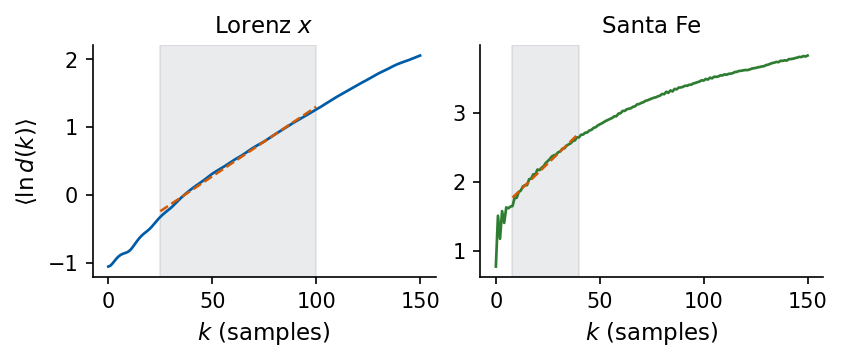

In [49]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained")
    for ax, k, unit in ((axs[0], "lorenz", 0.02), (axs[1], "santafe", 1.0)):
        kk = np.arange(len(ROS[k]))
        ax.plot(kk, ROS[k], color=COL[k])
        k0, k1 = FIT[k]
        b = np.polyfit(np.arange(k0, k1 + 1), ROS[k][k0:k1 + 1], 1)
        ax.plot(np.arange(k0, k1 + 1), np.polyval(b, np.arange(k0, k1 + 1)), "--", color=DSOrange, lw=1.2)
        ax.axvspan(k0, k1, color=UJGray, alpha=0.12)
        ax.set_xlabel("$k$ (samples)"); ax.set_title(LABEL[k])
    axs[0].set_ylabel(r"$\langle\ln d(k)\rangle$")
    save(fig, "fig_rosenstein"); plt.show()

For Lorenz $x$ ($m=4$, $\kappa=10$) the slope over $k=25$–100 samples (0.5 to 2 time units) is 1.03 per time unit, 13% above the Benettin value 0.907, and fits starting at $k=0$ give 1.4 to 1.5. The initial steep part of the curve comes from the alignment of the separation with the unstable direction and from the oscillation of $x$, and it must be excluded. For Santa Fe the curve rises steeply during the first pulsation period (about 8 samples), then grows nearly linearly, and bends over beyond about 40 samples. Over $k=8$–40 we find $\lambda_1=0.029$ per sample, and this slope changes by less than 0.001 when $m$ goes from 3 to 6. The value depends strongly on the fit range. Starting at $k=0$ gives 0.080 for the first 8 samples, and a fit over the first 150 samples, which reach into the saturation, gives 0.0147.

Sano and Sawada estimate the whole spectrum from data [M. Sano and Y. Sawada, Phys. Rev. Lett. **55**, 1082 (1985), [doi:10.1103/PhysRevLett.55.1082](https://doi.org/10.1103/PhysRevLett.55.1082)]. Around each point a matrix $A_i$ is fitted by least squares to the evolution of its $K$ nearest neighbours, $\mathbf y_{j+1}-\mathbf y_{i+1}\approx A_i(\mathbf y_j-\mathbf y_i)$, and the Benettin QR procedure is applied to the product of these local Jacobians. We use $K=63$ neighbours and standardised data, with the embedding $m=4$, $\kappa=2$ and, for comparison, with our embedding of Section 6.

In [50]:
def local_jacobian_spectrum(x, m, lag, K, step=1):
    """Sano-Sawada estimate. For each y_i: least-squares matrix A_i with y_{j+step} - y_{i+step} ~ A_i (y_j - y_i)
    over the K nearest neighbours j; then Benettin QR on the product of the A_i. Data are standardised first.
    Returns the m exponents per sample, sorted."""
    Y = delay_embed((x - x.mean()) / x.std(), m, lag)
    N = len(Y)
    _, nb = cKDTree(Y).query(Y, k=K + 1)
    Q = np.eye(m); acc = np.zeros(m); count = 0
    for i in range(0, N - step - 1, step):
        j = nb[i, 1:]; j = j[j + step < N]
        A = np.linalg.lstsq(Y[j] - Y[i], Y[j + step] - Y[i + step], rcond=None)[0].T
        Q, R = np.linalg.qr(A @ Q)
        acc += np.log(np.abs(np.diag(R))); count += 1
    return np.sort(acc / (count * step))[::-1]

t0 = time.time()
ss_m4 = local_jacobian_spectrum(S["santafe"], 4, 2, 63)
ss_ours = local_jacobian_spectrum(S["santafe"], EMB_M["santafe"], LAG["santafe"], 63)
ss_lor = local_jacobian_spectrum(S["lorenz"], EMB_M["lorenz"], LAG["lorenz"], 63) / DT["lorenz"]
print(f"({time.time()-t0:.1f} s)")
print("Santa Fe, m = 4, κ = 2, K = 63:", np.round(ss_m4, 4))
print(f"Santa Fe, m = {EMB_M['santafe']}, κ = {LAG['santafe']}, K = 63:", np.round(ss_ours, 4))
print(f"Lorenz x, m = {EMB_M['lorenz']}, κ = {LAG['lorenz']}, K = 63 (per time unit):", np.round(ss_lor, 3))
nums["sano_santafe_m4"] = ss_m4.tolist(); nums["sano_santafe_ours"] = ss_ours.tolist(); nums["sano_lorenz"] = ss_lor.tolist()

(1.3 s)
Santa Fe, m = 4, κ = 2, K = 63: [ 0.0651 -0.0044 -0.3822 -1.5587]
Santa Fe, m = 3, κ = 2, K = 63: [ 0.0793 -0.0302 -0.9303]
Lorenz x, m = 4, κ = 10, K = 63 (per time unit): [ 1.012  0.171 -2.189 -6.632]


With $m=4$ and $\kappa=2$ the leading exponent of the laser is $\lambda_1=0.065$ per sample. The same algorithm applied to Lorenz $x$ gives $\lambda_1=1.01$ per time unit (12% high), a spurious second exponent $0.17$ in place of zero, and $\lambda_3=-2.2$ in place of $-14.6$. Strongly contracting directions are almost empty of neighbours and cannot be fitted from 4000 points. For the laser the two methods differ by a factor of two, 0.029 per sample from Rosenstein and 0.065 from the local Jacobians. Both are estimates with method-dependent biases, and we keep the method next to every number.

<hr/>
## 9. Kaplan–Yorke dimension and prediction horizon

The exponents also measure the size of the attractor. The sum $\Sigma_k=\lambda_1+\dots+\lambda_k$ is the growth rate of $k$-dimensional volumes. Let $j$ be the largest index with $\Sigma_j\ge0$. Volumes of dimension $j$ do not shrink and volumes of dimension $j+1$ do, so the attractor has a dimension between $j$ and $j+1$. Kaplan and Yorke interpolated linearly between the two [J. L. Kaplan and J. A. Yorke, Lect. Notes Math. **730**, 204 (1979), [doi:10.1007/BFb0064319](https://doi.org/10.1007/BFb0064319)],
$$
D_{\rm KY}=j+\frac{\Sigma_j}{|\lambda_{j+1}|} ,
$$
the Kaplan–Yorke (KY) or Lyapunov dimension. Exponents that are zero within their statistical error would make the result jump between integers depending on the sign of noise, so we set exponents with $|\lambda_i|$ below three standard errors to zero before applying the formula.

In [51]:
def kaplan_yorke(lams, tol=0.0):
    """D_KY = j + Sigma_j / |lambda_{j+1}|, j the largest index with Sigma_j = lambda_1 + ... + lambda_j >= 0.
    Exponents with |lambda| < tol are set to zero first (they cannot be told apart from zero)."""
    lams = np.where(np.abs(lams) < tol, 0.0, np.sort(lams)[::-1])
    cs = np.cumsum(lams)
    if cs[0] < 0:
        return 0.0
    j = int(np.max(np.nonzero(cs >= 0)[0])) + 1          # number of leading exponents with Sigma_j >= 0
    if j == len(lams):
        return np.nan                                       # not enough exponents computed
    return j + cs[j - 1] / abs(lams[j])

DKY = {"lorenz": kaplan_yorke(lam_lor, tol=3 * err_lor.max())}
for k in ("mg15", "mg25", "mg35"):
    DKY[k] = kaplan_yorke(LYAP_MG[k], tol=3 * ERR_MG[k][:4].max())
DKY["santafe"] = kaplan_yorke(ss_m4)
DKY_raw = {"lorenz": kaplan_yorke(lam_lor), **{k: kaplan_yorke(LYAP_MG[k]) for k in LYAP_MG}}
print(f"Lorenz   D_KY = {DKY['lorenz']:.4f}")
for k, tau in (("mg15", 15), ("mg25", 25), ("mg35", 35)):
    print(f"MG {tau}    D_KY = {DKY[k]:.3f} (tolerance {3*ERR_MG[k][:4].max():.1e}; without tolerance {DKY_raw[k]:.3f})")
print(f"Santa Fe D_KY = {DKY['santafe']:.3f} from the local-Jacobian spectrum with m = 4")
DKY_SF_M3 = kaplan_yorke(ss_ours)                                  # embedding of Section 6, m = 3
DKY_SF_M4_ZERO = kaplan_yorke(np.array([ss_m4[0], 0.0, *ss_m4[2:]]))   # m = 4 with lambda_2 set to zero
print(f"Santa Fe D_KY with our embedding (m = {EMB_M['santafe']}): {DKY_SF_M3:.3f}")
print(f"Santa Fe D_KY with m = 4 and lambda_2 set to zero: {DKY_SF_M4_ZERO:.3f}")
nums["dky"] = {k: float(v) for k, v in DKY.items()}
nums["dky_santafe_m3"] = float(DKY_SF_M3); nums["dky_santafe_m4_lam2_zero"] = float(DKY_SF_M4_ZERO)

Lorenz   D_KY = 2.0622
MG 15    D_KY = 1.000 (tolerance 4.7e-05; without tolerance 0.000)
MG 25    D_KY = 3.158 (tolerance 8.4e-04; without tolerance 3.158)
MG 35    D_KY = 3.406 (tolerance 1.1e-03; without tolerance 3.416)
Santa Fe D_KY = 2.159 from the local-Jacobian spectrum with m = 4
Santa Fe D_KY with our embedding (m = 3): 2.053
Santa Fe D_KY with m = 4 and lambda_2 set to zero: 2.170


Lorenz-63 has $D_{\rm KY}=2.062$, a little more than a surface. The periodic orbit at $\tau_{\rm MG}=15$ has $D_{\rm KY}=1.000$, a closed curve. For $\tau_{\rm MG}=25$ we find 3.158 and for $\tau_{\rm MG}=35$ 3.41, so the attractor of the delay system grows with the delay even though $\lambda_1$ decreases. At $\tau_{\rm MG}=35$ the value is sensitive to $\lambda_1$, which enters $\Sigma_3$ and has a standard error of 0.0004. For the laser the local-Jacobian spectrum gives $D_{\rm KY}=2.16$ with $m=4$ and 2.05 with our $m=3$. The local-Jacobian method gives no standard errors, so the three-standard-error rule cannot be applied to the laser. Setting the small second exponent at $m=4$ to zero gives 2.17, and the spread from 2.05 to 2.17 is a lower bound on the uncertainty of the laser dimension.


### A map whose dimension can be checked

The straight line that Kaplan and Yorke draw between $\Sigma_j$ and $\Sigma_{j+1}$ is a choice, and the dissipative baker's map tests it, because its dimension can be computed in two independent ways [J. D. Farmer, E. Ott and J. A. Yorke, Physica D **7**, 153 (1983), [doi:10.1016/0167-2789(83)90125-2](https://doi.org/10.1016/0167-2789(83)90125-2)]. The map acts on the unit square of points $(q,w)$ with a constant $0<c<\tfrac12$,
$$
q_{n+1}=2q_n\ \mathrm{mod}\ 1,\qquad w_{n+1}=c\,w_n+\tfrac12\,b_n,\qquad b_n=\begin{cases}0, & q_n<\tfrac12,\\ 1, & q_n\ge\tfrac12 .\end{cases}
$$
The left half of the square is stretched horizontally by the factor 2 and squeezed vertically by the factor $c$ into the strip $0\le w<c$, and the right half into the strip $\tfrac12\le w<\tfrac12+c$. Away from the cut at $q=\tfrac12$ the Jacobian is $\mathrm{diag}(2,c)$, so $\lambda_1=\ln2$ and $\lambda_2=\ln c$ for every orbit, $\Sigma_1>0>\Sigma_2=\ln(2c)$, and the Kaplan–Yorke formula gives $D_{\rm KY}=1+\ln2/\ln(1/c)$. After $n$ steps the square has become $2^n$ horizontal strips of height $c^n$, placed in $w$ like the intervals of a Cantor set. Boxes of side $\varepsilon=c^n$ then number $N_\varepsilon\propto2^nc^{-n}$, and the box-counting dimension $D_B=\lim_{\varepsilon\to0}\ln N_\varepsilon/\ln(1/\varepsilon)$ is again $1+\ln2/\ln(1/c)$. The vertical factor alone is a Cantor set of dimension $\ln2/\ln(1/c)$. For $c=1/3$ this is $\ln2/\ln3$, the dimension of the middle-thirds Cantor set.

A third dimension weights the boxes by how often the motion visits them. With $p_i(\varepsilon)$ the fraction of time that a long orbit spends in box $i$ of side $\varepsilon$, the information dimension is
$$
D_1\coloneqq\lim_{\varepsilon\to0}\frac{-\sum_ip_i(\varepsilon)\ln p_i(\varepsilon)}{\ln(1/\varepsilon)} .
$$
The numerator is the Shannon entropy of the visiting frequencies. If all $N_\varepsilon$ occupied boxes are visited equally often, it equals $\ln N_\varepsilon$ and $D_1=D_B$. Boxes that are visited rarely lower $D_1$ below $D_B$. Kaplan and Yorke conjectured that $D_{\rm KY}=D_1$ for typical attractors, a statement proven for some classes of systems and open in general [J.-P. Eckmann and D. Ruelle, Rev. Mod. Phys. **57**, 617 (1985), [doi:10.1103/RevModPhys.57.617](https://doi.org/10.1103/RevModPhys.57.617)].

We check these statements numerically for $c=1/3$. The exponents come from the Jacobian of the map, computed with `jax.jacfwd` at points of the attractor. The dimensions come from counting boxes. A plain iteration of the map in floating point fails here, since doubling $q$ shifts its binary digits one place to the left, and the cell below shows that a double-precision $q_0$ between $\tfrac12$ and 1 becomes 0 after about fifty steps. The digit $b_n$ that enters $w$ is the $(n+1)$-th binary digit of $q_0$, and for almost every $q_0$ these digits behave like independent tosses of a fair coin. We therefore draw the digits $b_n$ at random, 40 of them for each of $2\times10^6$ points, which places every point on the attractor with the frequencies of a typical long orbit, since $c^{40}\approx8\times10^{-20}$ erases the starting value of $w$. The current $q_n$ consists of the digits not used yet, so it is uniform on $[0,1)$ and independent of $w_n$. The attractor is then the product of the interval in $q$ with the Cantor set in $w$, which gives $D_B=1+D_B^{(w)}$ and $D_1=1+D_1^{(w)}$, and we count boxes of side $\varepsilon=3^{-n}$ along $w$ alone.

In [52]:
# dissipative baker's map with c = 1/3: Lyapunov exponents from the Jacobian
C_B = 1.0 / 3.0
def baker(u):
    """(q, w) -> (2q mod 1, c w + b/2), with b = 1 on the right half q >= 1/2."""
    q, w = u
    b = (q >= 0.5).astype(u.dtype)
    return jnp.array([2.0 * q - b, C_B * w + 0.5 * b])
jac_baker = jax.jacfwd(baker)

# floating-point doubling loses one binary digit per step: steps until q becomes exactly 0
steps_to_zero = []
for q in np.random.default_rng(0).uniform(0.5, 1.0, 5):
    n = 0
    while q != 0.0:
        q = 2.0 * q - float(q >= 0.5); n += 1
    steps_to_zero.append(n)
print("float64 iteration of 2q mod 1 from five random q_0 in [1/2, 1): exactly 0 after", steps_to_zero, "steps")

# points of the attractor: 40 random digits b_n per point (c^40 ~ 8e-20), q uniform and independent of w
M_B, N_DIG = 2_000_000, 40
keys_b = jax.random.split(jax.random.key(2026), N_DIG)
w_att = np.asarray(jax.lax.scan(lambda w, k: (C_B * w + 0.5 * jax.random.bernoulli(k, 0.5, (M_B,)), None),
                                jnp.zeros(M_B), keys_b)[0])
q_att = np.asarray(jax.random.uniform(jax.random.key(2027), (M_B,)))

# exponents: mean of ln |diagonal of the Jacobian| over 10^4 points of the attractor (the Jacobian is diagonal)
J_b = np.asarray(jax.vmap(jac_baker)(jnp.stack([q_att[:10000], w_att[:10000]], 1)))
lam_baker = np.log(np.abs(np.diagonal(J_b, axis1=1, axis2=2))).mean(0)
dky_baker = kaplan_yorke(lam_baker)
print(f"lambda_1 = {lam_baker[0]:.6f} (ln 2 = {np.log(2):.6f}), lambda_2 = {lam_baker[1]:.6f} (ln c = {np.log(C_B):.6f})")
print(f"D_KY = {dky_baker:.6f}; 1 + ln 2 / ln 3 = {1 + np.log(2) / np.log(3):.6f}; Cantor set ln 2 / ln 3 = {np.log(2) / np.log(3):.6f}")

float64 iteration of 2q mod 1 from five random q_0 in [1/2, 1): exactly 0 after [50, 53, 52, 53, 53] steps


lambda_1 = 0.693147 (ln 2 = 0.693147), lambda_2 = -1.098612 (ln c = -1.098612)
D_KY = 1.630930; 1 + ln 2 / ln 3 = 1.630930; Cantor set ln 2 / ln 3 = 0.630930


occupied boxes N_eps for n = 1..12: [3, 6, 12, 24, 48, 96, 192, 384, 768, 1536, 3072, 6144]
fit over n = 3..10: D_B = 1 + 0.6309 = 1.6309, D_1 = 1 + 0.6309 = 1.6309  (1 + ln 2/ln 3 = 1.6309)


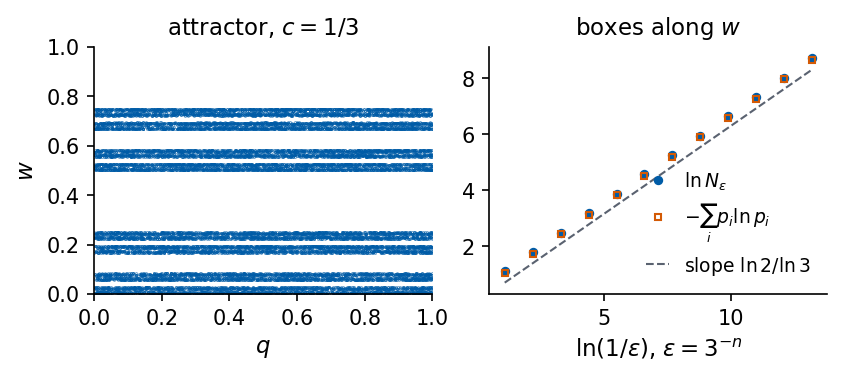

In [53]:
# box counting and information dimension along w, boxes of side eps = 3^-n
NS_B = np.arange(1, 13)
logN_b, H_b = [], []
for n in NS_B:
    _, counts = np.unique(np.floor(w_att * 3.0**n).astype(np.int64), return_counts=True)
    p = counts / counts.sum()                                  # visiting frequencies p_i of the occupied boxes
    logN_b.append(np.log(len(counts))); H_b.append(-(p * np.log(p)).sum())
logN_b, H_b = np.array(logN_b), np.array(H_b)
ln_inv_eps = NS_B * np.log(3.0)                                # ln(1/eps)
FIT_B = (NS_B >= 3) & (NS_B <= 10)
d_box_w = np.polyfit(ln_inv_eps[FIT_B], logN_b[FIT_B], 1)[0]
d_inf_w = np.polyfit(ln_inv_eps[FIT_B], H_b[FIT_B], 1)[0]
print("occupied boxes N_eps for n = 1..12:", np.exp(logN_b).round().astype(int).tolist())
print(f"fit over n = 3..10: D_B = 1 + {d_box_w:.4f} = {1 + d_box_w:.4f}, D_1 = 1 + {d_inf_w:.4f} = {1 + d_inf_w:.4f}"
      f"  (1 + ln 2/ln 3 = {1 + np.log(2) / np.log(3):.4f})")
nums["baker"] = {"c": C_B, "lyap": lam_baker.tolist(), "dky": float(dky_baker), "D_B": float(1 + d_box_w),
                 "D_1": float(1 + d_inf_w), "float_steps_to_zero": steps_to_zero, "n_points": M_B}

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained")
    axs[0].scatter(q_att[:20000], w_att[:20000], s=0.05, color=UJBlue, rasterized=True)
    axs[0].set_xlim(0, 1); axs[0].set_ylim(0, 1); axs[0].set_xlabel("$q$"); axs[0].set_ylabel("$w$")
    axs[0].set_title(r"attractor, $c=1/3$")
    axs[1].plot(ln_inv_eps, logN_b, "o", color=UJBlue, ms=3.5, label=r"$\ln N_\varepsilon$")
    axs[1].plot(ln_inv_eps, H_b, "s", color=DSOrange, ms=2.5, mfc="none", label=r"$-\sum_i p_i\ln p_i$")
    axs[1].plot(ln_inv_eps, np.log(2) / np.log(3) * ln_inv_eps, "--", color=UJGray, lw=1.0, label=r"slope $\ln2/\ln3$")
    axs[1].set_xlabel(r"$\ln(1/\varepsilon)$, $\varepsilon=3^{-n}$"); axs[1].set_title("boxes along $w$")
    axs[1].legend(loc="lower right", fontsize=9, handlelength=1.2)
    save(fig, "fig_baker_dimension"); plt.show()

The exponents from the Jacobian are $\ln2=0.693$ and $\ln(1/3)=-1.099$, and the Kaplan–Yorke formula gives $D_{\rm KY}=1.631$. The right panel shows the logarithm of the number of occupied boxes along $w$ and the entropy of the visiting frequencies against $\ln(1/\varepsilon)$. Both lie on straight lines of slope $\ln2/\ln3$ (dashed), and the fits over $n=3$ to 10 give $D_B=1.631$ and $D_1=1.631$. The number of occupied boxes doubles from one $n$ to the next, while the boxes shrink by the factor 3, which is the Cantor construction seen through the boxes. In this example the three dimensions agree, because the two branches of the map are visited equally often and every strip carries the same share of the motion. The left panel shows the attractor itself, horizontal lines that are uniform in $q$ and arranged in $w$ as a Cantor set, whose two first-level pieces lie inside the strips $0\le w<\tfrac13$ and $\tfrac12\le w<\tfrac56$.

### Prediction horizon

The leading exponent sets the prediction horizon. An initial error $\delta_0$ grows on average as $\delta(t)\approx\delta_0e^{\lambda_1t}$, and it reaches a tolerance $\Delta$ after
$$
T_{\rm pred}=\frac{1}{\lambda_1}\ln\frac{\Delta}{\delta_0} .
$$
The Lyapunov time $T_\lambda=1/\lambda_1$ is the time for an $e$-fold growth. A thousand times better initial data extend the horizon by only $\ln(1000)\,T_\lambda\approx6.9\,T_\lambda$. We test the formula on Lorenz-63 with 200 pairs of trajectories that start at points of the attractor and differ by $|\delta_0|=10^{-8}$ in a random direction.

one pair: slope of ln|delta| for 2 < t < 15 = 0.930 per time unit (lambda_1 = 0.907); |delta| exceeds 1 at t = 19.5


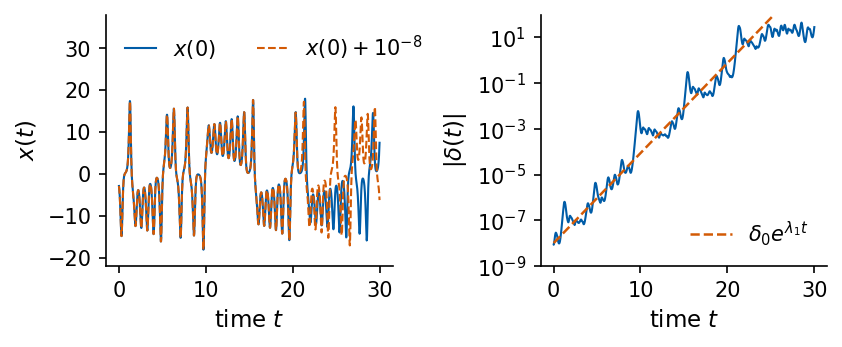

In [54]:
# two Lorenz trajectories that start 1e-8 apart (along x), followed for 30 time units
u_a = jnp.asarray(lor_states[0]); u_b = u_a + jnp.array([1e-8, 0.0, 0.0])
def follow(u, n):
    out = []
    for _ in range(n):
        u = lorenz_map(lorenz_map(u)); out.append(u)
    return np.asarray(jnp.stack(out))
n_tw = 1500
tr_a, tr_b = follow(u_a, n_tw), follow(u_b, n_tw)
t_tw = np.arange(1, n_tw + 1) * 0.02
dist = np.linalg.norm(tr_a - tr_b, axis=1)
fit = (t_tw > 2) & (t_tw < 15)
slope_one = np.polyfit(t_tw[fit], np.log(dist[fit]), 1)[0]
t_apart = t_tw[np.argmax(dist > 1.0)]
print(f"one pair: slope of ln|delta| for 2 < t < 15 = {slope_one:.3f} per time unit (lambda_1 = {lam_lor[0]:.3f});"
      f" |delta| exceeds 1 at t = {t_apart:.1f}")
nums["twin"] = {"slope": float(slope_one), "t_apart": float(t_apart)}
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.2), layout="constrained")
    axs[0].plot(t_tw, tr_a[:, 0], color=UJBlue, lw=1.0, label="$x(0)$")
    axs[0].plot(t_tw, tr_b[:, 0], "--", color=DSOrange, lw=1.0, label=r"$x(0)+10^{-8}$")
    axs[0].set_xlabel("time $t$"); axs[0].set_ylabel("$x(t)$"); axs[0].legend(loc="upper left", fontsize=10, ncol=2, handlelength=1.5)
    axs[0].set_ylim(-22, 38)
    axs[1].semilogy(t_tw, dist, color=UJBlue, lw=1.0)
    axs[1].semilogy(t_tw, 1e-8 * np.exp(lam_lor[0] * t_tw), "--", color=DSOrange, lw=1.2, label=r"$\delta_0 e^{\lambda_1 t}$")
    axs[1].set_xlabel("time $t$"); axs[1].set_ylabel(r"$|\delta(t)|$"); axs[1].set_ylim(1e-9, 1e2)
    axs[1].legend(loc="lower right", fontsize=10)
    save(fig, "fig_lorenz_twin"); plt.show()

growth rate of <ln|delta|> for 2 < t < 15: 0.897 per time unit (lambda_1 = 0.907)
<ln|delta|> reaches ln(Delta) for Delta = 1.0 at t = 20.44; T_pred = ln(Delta/delta0)/lambda_1 = 20.31 time units = 1016 samples
saturation level exp<ln|delta|> over the last 5 time units: 12.2


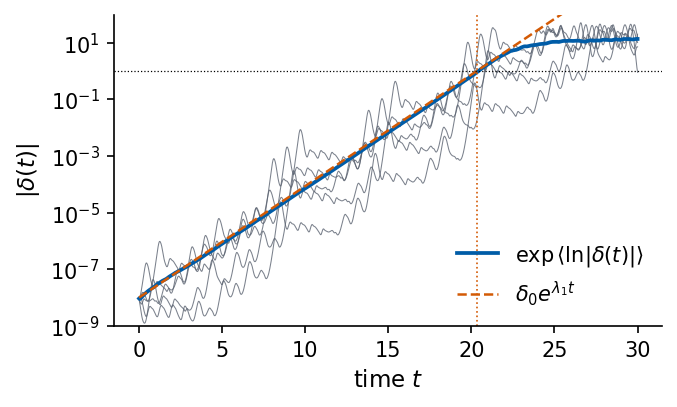

In [55]:
@partial(jax.jit, static_argnums=2)
def twin_separation(u0, d0, n_samples):
    """Two Lorenz trajectories from u0 and u0 + d0 (RK4, h = 0.01); |delta| every 0.02 time units."""
    def one(c, _):
        a, b = c
        for _ in range(2):
            a, b = lorenz_map(a), lorenz_map(b)
        return (a, b), jnp.linalg.norm(a - b)
    return jax.lax.scan(one, (u0, u0 + d0), None, length=n_samples)[1]

DELTA0 = 1e-8
n_pairs, n_t = 200, 1500                                       # 200 starting points, 30 time units
key_dirs = jax.random.normal(jax.random.key(3), (n_pairs, 3))
d0s = DELTA0 * key_dirs / jnp.linalg.norm(key_dirs, axis=1, keepdims=True)    # random directions, |d0| = 1e-8
starts = jnp.asarray(lor_states[::20][:n_pairs])
seps = np.asarray(jax.vmap(twin_separation, in_axes=(0, 0, None))(starts, d0s, n_t))   # (200, 1500)
tt = np.arange(1, n_t + 1) * 0.02
mean_log = np.log(seps).mean(0)
fit_win = (tt > 2) & (tt < 15)
growth = np.polyfit(tt[fit_win], mean_log[fit_win], 1)[0]
DELTA = 1.0
t_cross = tt[np.argmax(mean_log > np.log(DELTA))]
t_pred = np.log(DELTA / DELTA0) / lam_lor[0]
print(f"growth rate of <ln|delta|> for 2 < t < 15: {growth:.3f} per time unit (lambda_1 = {lam_lor[0]:.3f})")
print(f"<ln|delta|> reaches ln(Delta) for Delta = {DELTA} at t = {t_cross:.2f}; "
      f"T_pred = ln(Delta/delta0)/lambda_1 = {t_pred:.2f} time units = {t_pred/0.02:.0f} samples")
print(f"saturation level exp<ln|delta|> over the last 5 time units: {np.exp(mean_log[-250:].mean()):.1f}")
nums["error_growth"] = {"rate": float(growth), "t_cross": float(t_cross), "t_pred": float(t_pred),
                        "delta0": DELTA0, "Delta": DELTA}
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.6), layout="constrained")
    for p in range(5):
        ax.semilogy(tt, seps[p], color=UJGray, lw=0.5, alpha=0.8)
    ax.semilogy(tt, np.exp(mean_log), color=UJBlue, lw=1.8, label=r"$\exp\langle\ln|\delta(t)|\rangle$")
    ax.semilogy(tt, DELTA0 * np.exp(lam_lor[0] * tt), "--", color=DSOrange, lw=1.2, label=r"$\delta_0 e^{\lambda_1 t}$")
    ax.axhline(DELTA, color="k", lw=0.6, ls=":"); ax.axvline(t_pred, color=DSOrange, lw=0.8, ls=":")
    ax.set_xlabel("time $t$"); ax.set_ylabel(r"$|\delta(t)|$"); ax.set_ylim(1e-9, 1e2); ax.legend(loc="lower right", fontsize=10)
    save(fig, "fig_error_growth"); plt.show()

Grey lines are five individual pairs, the blue line is $\exp\langle\ln|\delta(t)|\rangle$ over the 200 pairs, and the dashed line is $\delta_0e^{\lambda_1t}$ with the Benettin $\lambda_1$. Single pairs grow irregularly, because the local growth rate varies along the attractor. The average grows at 0.897 per time unit for $2<t<15$, close to $\lambda_1=0.907$, and reaches $\Delta=1$ at $t=20.4$, against $T_{\rm pred}=\ln(10^8)/\lambda_1=20.3$ time units (1016 samples). The error then saturates at the size of the attractor ($\approx12$).

<hr/>
## 10. Chaos and noise in one record

An irregular record can come from a deterministic law with a few variables or from a linear process driven by noise. The two answers lead to different models, so we decide between them from the record alone before any forecasting model is fitted. Every statistic is computed for the chaotic records and for coloured noise with the same autocorrelation function, and for two linear random processes whose answer is known. These statistics characterise the signals and choose no model setting, so they use all 4000 samples, with the delay $\kappa$ and the dimension $m$ chosen in Section 6 on the first 2500 samples.

### Same correlations, different dynamics

The ACF and the PSD are second-order statistics, and many different processes share them. We make this concrete by constructing a random signal with the same periodogram as Lorenz $x$. We take the DFT $X_q$ of the data, keep the amplitudes $|X_q|$, replace the phases by independent random phases, and transform back. Such a signal is called a phase-randomised surrogate [J. Theiler, S. Eubank, A. Longtin, B. Galdrikian and J. D. Farmer, Physica D **58**, 77 (1992), [doi:10.1016/0167-2789(92)90102-S](https://doi.org/10.1016/0167-2789(92)90102-S)].

In [56]:
def phase_randomised(x, key):
    """Fourier-transform surrogate. X_q = FFT of the demeaned series; keep |X_q|, replace the phases by independent
    uniform phases on [0, 2 pi) (zero phase at f = 0 and, for even N, at the Nyquist frequency, so that the inverse
    transform is real); inverse FFT and add the mean back. The periodogram is unchanged."""
    N = x.shape[0]
    X = jnp.fft.rfft(x - x.mean())                       # rfft stores q = 0..N/2; q < 0 follow from X_{-q} = conj(X_q)
    phi = jax.random.uniform(key, X.shape, minval=0.0, maxval=2 * jnp.pi)
    phi = phi.at[0].set(0.0)
    if N % 2 == 0:
        phi = phi.at[-1].set(0.0)
    return jnp.fft.irfft(jnp.abs(X) * jnp.exp(1j * phi), N) + x.mean()

x = S["lorenz"]
xs = np.asarray(phase_randomised(jnp.asarray(x), jax.random.key(7)))
P_x, P_s = np.asarray(periodogram_jax(x, 0.02)[1]), np.asarray(periodogram_jax(xs, 0.02)[1])
rho_s = np.asarray(acf_jax(jnp.asarray(xs), MAX_LAG))
print(f"max |S_data - S_surrogate| / max S = {np.abs(P_x - P_s).max() / P_x.max():.1e}")
nums["phase_acf_diff"] = {}
for kmax in (100, 400):
    nums["phase_acf_diff"][kmax] = float(np.abs(RHO['lorenz'][:kmax+1] - rho_s[:kmax+1]).max())
    print(f"max |rho_data - rho_surrogate| over lags 0..{kmax} = {nums['phase_acf_diff'][kmax]:.3f}")
def acf_circular(z):
    """ACF with the wrap-around pairs (z_{k+n} with k + n taken modulo N), the inverse DFT of the periodogram."""
    zc = z - z.mean()
    return np.fft.ifft(np.abs(np.fft.fft(zc)) ** 2).real / np.sum(zc ** 2)
circ_diff = np.abs(acf_circular(x) - acf_circular(xs))[:401].max()
nums["phase_circ_acf_diff"] = float(circ_diff)
print(f"circular ACF with wrap-around pairs: max |data - surrogate| over lags 0..400 = {circ_diff:.1e}")

max |S_data - S_surrogate| / max S = 2.8e-16
max |rho_data - rho_surrogate| over lags 0..100 = 0.013
max |rho_data - rho_surrogate| over lags 0..400 = 0.102
circular ACF with wrap-around pairs: max |data - surrogate| over lags 0..400 = 2.2e-16


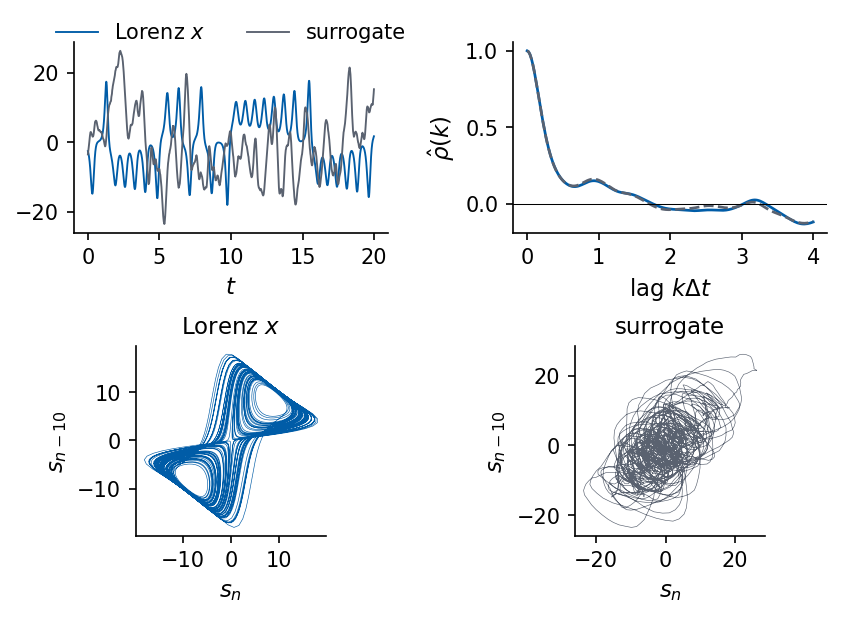

In [57]:
l = LAG["lorenz"]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 2, figsize=(5.5, 4.0), layout="constrained")
    t = np.arange(1000) * 0.02
    axs[0, 0].plot(t, x[:1000], color=COL["lorenz"], lw=0.9, label="Lorenz $x$")
    axs[0, 0].plot(t, xs[:1000], color=UJGray, lw=0.9, label="surrogate")
    axs[0, 0].set_xlabel("$t$"); axs[0, 0].legend(fontsize=10, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.2))
    lags = np.arange(201) * 0.02
    axs[0, 1].plot(lags, RHO["lorenz"][:201], color=COL["lorenz"], label="data")
    axs[0, 1].plot(lags, rho_s[:201], color=UJGray, ls="--", label="surrogate")
    axs[0, 1].set_xlabel(r"lag $k\Delta t$"); axs[0, 1].set_ylabel(r"$\hat\rho(k)$"); axs[0, 1].axhline(0, color="k", lw=0.5)
    for ax, y, c, title in ((axs[1, 0], x, COL["lorenz"], "Lorenz $x$"), (axs[1, 1], xs, UJGray, "surrogate")):
        ax.plot(y[l:], y[:-l], color=c, lw=0.3)
        ax.set_xlabel("$s_n$"); ax.set_ylabel(f"$s_{{n-{l}}}$"); ax.set_title(title); ax.set_aspect("equal")
    save(fig, "fig_surrogate"); plt.show()

The periodograms agree to round-off. The ACFs agree to 0.013 up to lag 100, and the differences at larger lags (up to 0.10 at lag 400) come from the estimator $\hat\rho$, which ignores the wrap-around terms that the periodogram contains. The circular ACF, which includes the wrap-around pairs $(s_k,s_{k+n})$ with $k+n$ taken modulo $N$ and is the inverse DFT of the periodogram, agrees to $2.2\times10^{-16}$. The surrogate therefore keeps the circular ACF to round-off and the usual ACF only approximately. The time traces, however, look different, and the delay portraits $(s_n,s_{n-10})$ in the lower panels show the deterministic structure of Lorenz $x$ and an unstructured cloud for the surrogate. No statistic built from the autocorrelation function or the spectrum can tell the two signals apart. The difference lies in the geometry of the delay vectors, which the next two statistics measure.

### Two linear controls

Two linear random processes serve as controls. The autoregressive process of order one, AR(1), $s_n=0.8\,s_{n-1}+\eta_n$ with independent Gaussian $\eta_n$ of unit variance, is the simplest coloured noise. The autoregressive process of order two, AR(2), $s_n=a_1s_{n-1}+a_2s_{n-2}+\eta_n$ with $a_1=1.6$ and $a_2=-0.9$, is a noisy oscillator. Both roots of $z^2-a_1z-a_2$ have modulus 0.949, inside the unit circle, so the process is stationary, and the roots are complex, which makes the motion oscillate. We also build a phase-randomised surrogate of the laser record, which has the spectrum of the laser and Gaussian values. For the controls we use $m=3$ with $\kappa=1$ for AR(1) and $\kappa=2$ for AR(2), and each surrogate is embedded with the delay and dimension of its data.

In [58]:
# two linear random processes with known answers, and a phase-randomised surrogate of the laser record
A1, A2 = 1.6, -0.9                                   # AR(2): s_n = a1 s_{n-1} + a2 s_{n-2} + eps_n, eps ~ N(0, 1)
roots = np.roots([1.0, -A1, -A2])                     # z^2 - a1 z - a2 = 0; stationary if all |z| < 1
print("AR(2) characteristic roots", np.round(roots, 4), "| moduli", np.round(np.abs(roots), 4))

@partial(jax.jit, static_argnums=1)
def ar2_series(key, n, burn=1000):
    eps = jax.random.normal(key, (n + burn,))
    def step(c, e):
        s1, s2 = c
        s = A1 * s1 + A2 * s2 + e
        return (s, s1), s
    return jax.lax.scan(step, (0.0, 0.0), eps)[1][burn:]

PHI_C = 0.8                 # AR(1): s_n = 0.8 s_{n-1} + eta_n, eta ~ N(0, 1)
@partial(jax.jit, static_argnums=1)
def ar1_series(key, n, burn=1000):
    eps = jax.random.normal(key, (n + burn,))
    return jax.lax.scan(lambda s, e: (PHI_C * s + e,) * 2, 0.0, eps)[1][burn:]

S_AR = np.asarray(ar2_series(jax.random.key(5), N_SAMPLES))
S_AR1 = np.asarray(ar1_series(jax.random.key(6), N_SAMPLES))
LABEL.update({"ar2": "AR(2) control", "ar1": "AR(1) control", "lorsurr": "Lorenz surrogate", "sfsurr": "Santa Fe surrogate"})
COL.update({"ar2": UJNavy, "ar1": UJGray, "lorsurr": "#7FB3E0", "sfsurr": "#8FCB91"})
sfs = np.asarray(phase_randomised(jnp.asarray(S["santafe"]), jax.random.key(8)))   # same spectrum as the laser
# records compared in this section: (signal, delay kappa, embedding dimension m); surrogates use the delay of their data
CN = {"lorenz": (S["lorenz"], LAG["lorenz"], EMB_M["lorenz"]), "lorsurr": (xs, LAG["lorenz"], EMB_M["lorenz"]),
      "santafe": (S["santafe"], LAG["santafe"], EMB_M["santafe"]), "sfsurr": (sfs, LAG["santafe"], EMB_M["santafe"]),
      "ar1": (S_AR1, 1, 3)}
CN_KEYS = list(CN)


AR(2) characteristic roots [0.8+0.5099j 0.8-0.5099j] | moduli [0.9487 0.9487]


### False nearest neighbours of chaos and noise

The false-nearest-neighbour test of Section 6 counts how often two delay vectors that are neighbours in $m$ dimensions separate when the next delay is added. A deterministic record unfolds at some $m$, and the fraction of false neighbours drops there. We apply the ratio test alone and the ratio test combined with the absolute test to Lorenz $x$, the laser, their surrogates and AR(1), on the first 2500 samples as in Section 6.

Lorenz $x$           kappa = 10 | ratio test [0.95  0.173 0.064 0.035 0.024 0.011 0.008 0.005 0.002 0.   ]
                                | combined   [0.95  0.173 0.067 0.042 0.035 0.028 0.04  0.049 0.051 0.067]
Lorenz surrogate     kappa = 10 | ratio test [0.976 0.612 0.115 0.004 0.001 0.    0.    0.    0.    0.   ]
                                | combined   [0.976 0.623 0.162 0.129 0.133 0.159 0.19  0.233 0.341 0.458]
Santa Fe             kappa =  2 | ratio test [0.975 0.152 0.017 0.004 0.002 0.002 0.    0.    0.    0.   ]
                                | combined   [0.975 0.152 0.017 0.005 0.003 0.003 0.002 0.002 0.002 0.002]
Santa Fe surrogate   kappa =  2 | ratio test [0.988 0.561 0.059 0.003 0.    0.    0.    0.    0.    0.   ]
                                | combined   [0.988 0.562 0.067 0.008 0.009 0.011 0.015 0.021 0.031 0.042]
AR(1) control        kappa =  1 | ratio test [0.981 0.586 0.109 0.013 0.001 0.    0.    0.    0.    0.   ]
                                | com

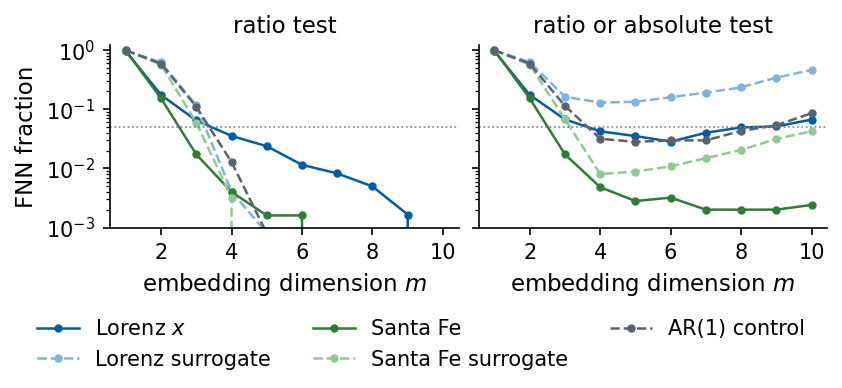

In [59]:
# false-nearest-neighbour fractions of chaotic records, their surrogates and AR(1), on the first N_FIT samples
FNN_CN = {k: fnn_fractions(s[:N_FIT], lag) for k, (s, lag, m) in CN.items()}
for k in CN_KEYS:
    print(f"{LABEL[k]:20s} kappa = {CN[k][1]:2d} | ratio test {np.round(FNN_CN[k][0], 3)}")
    print(f"{'':20s}            | combined   {np.round(FNN_CN[k][1], 3)}")
nums["fnn_chaos_noise"] = {k: {"ratio": FNN_CN[k][0].tolist(), "combined": FNN_CN[k][1].tolist()} for k in CN_KEYS}
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.5), layout="constrained", sharey=True)
    for k in CN_KEYS:
        ls = "--" if k in ("lorsurr", "sfsurr", "ar1") else "-"
        for ax, j in zip(axs, (0, 1)):
            ax.plot(np.arange(1, 11), FNN_CN[k][j], ls, marker="o", color=COL[k], lw=1.2, ms=3, label=LABEL[k])
    for ax, title in zip(axs, ("ratio test", "ratio or absolute test")):
        ax.axhline(FNN_THRESHOLD, color="0.5", ls=":", lw=0.8)
        ax.set_yscale("log"); ax.set_ylim(1e-3, 1.2); ax.set_xlabel("embedding dimension $m$"); ax.set_title(title)
    axs[0].set_ylabel("FNN fraction")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside lower center", ncol=3, fontsize=10)
    save(fig, "fig_chaos_noise_fnn"); plt.show()


At $m=2$ the ratio test finds 17% false neighbours for Lorenz $x$ and 15% for the laser, against 61% and 56% for their surrogates and 59% for AR(1). A chaotic record unfolds in few dimensions, while noise keeps folding. At larger $m$ the difference fades. By $m=4$ the ratio test falls below 5% for all five records, the noise included, because each added coordinate adds a random amount to the distance between neighbours, so the distance grows with $m$ and the ratio of the test shrinks with it. The absolute test was added for this reason. It keeps the Lorenz surrogate above 12% for all $m\ge3$, while the laser surrogate and AR(1) fall to between 1% and 3% at $m=4$, as low as Lorenz $x$. With a few thousand samples the false-neighbour fraction tells how many delays unfold a record that is known to be deterministic. Deciding whether it is deterministic needs a statistic that compares the record with noise directly.

### Nearest-neighbour forecast against the horizon

Determinism means that states which are close now stay close for a while. The simplest forecast that uses this finds, for the delay vector $\mathbf y_n$, its nearest neighbour $\mathbf y_j$ outside the Theiler window of 50 samples and predicts $\hat s_{n+\tau}=s_{j+\tau}$, the value that followed the neighbour $\tau$ steps later. This is the method of analogues [E. N. Lorenz, J. Atmos. Sci. **26**, 636 (1969), [doi:10.1175/1520-0469(1969)26<636:APARBN>2.0.CO;2](https://doi.org/10.1175/1520-0469(1969)26%3C636:APARBN%3E2.0.CO;2)]. We measure it by the normalised error $\mathrm{NE}(\tau)={\rm rms}(s_{n+\tau}-\hat s_{n+\tau})/\sigma$, with $\sigma$ the standard deviation of the targets. The forecast by the mean of the record has $\mathrm{NE}=1$, and the forecast by an unrelated value of the record has $\mathrm{NE}=\sqrt2$, because the difference of two independent values has twice the variance of one.

Lorenz $x$           (m, kappa) = (4, 10) | E(h) at h = 1, 5, 10, 20, 50: [0.054 0.088 0.142 0.27  0.471]
Lorenz surrogate     (m, kappa) = (4, 10) | E(h) at h = 1, 5, 10, 20, 50: [0.268 0.732 1.171 1.333 1.411]
Santa Fe             (m, kappa) = (3,  2) | E(h) at h = 1, 5, 10, 20, 50: [0.208 0.337 0.367 0.519 0.762]
Santa Fe surrogate   (m, kappa) = (3,  2) | E(h) at h = 1, 5, 10, 20, 50: [0.847 0.922 1.048 1.236 1.441]
AR(1) control        (m, kappa) = (3,  1) | E(h) at h = 1, 5, 10, 20, 50: [0.85  1.339 1.42  1.416 1.4  ]
AR(1) with a coinciding neighbour: E(1) = sqrt(2 (1 - phi^2)) = 0.849


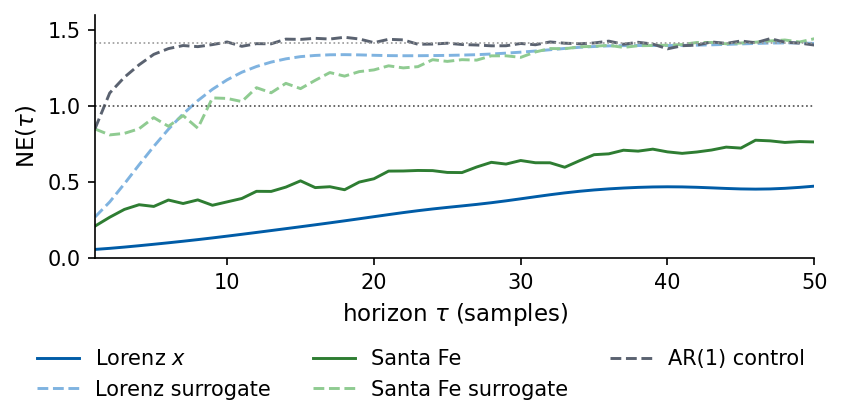

In [60]:
def nn_prediction_error(s, m, lag, h=1, w=50):
    """Normalised error of the nearest-neighbour predictor: s_{n+h} is predicted by s_{j+h}, j the nearest
    neighbour of the delay vector y_n with |n - j| > w. Returns rms(error) / std(target)."""
    Y = delay_embed(s, m, lag)[:-h]
    target = s[(m - 1) * lag + h:]
    j, _ = nearest_neighbour(jnp.asarray(Y), w)
    err = target - target[np.asarray(j)]
    return float(np.sqrt(np.mean(err ** 2)) / target.std())

NNE = {k: np.array([nn_prediction_error(s, m, lag, h) for h in range(1, TAU_MAX + 1)]) for k, (s, lag, m) in CN.items()}
for k in CN_KEYS:
    print(f"{LABEL[k]:20s} (m, kappa) = ({CN[k][2]}, {CN[k][1]:2d}) | E(h) at h = 1, 5, 10, 20, 50: "
          f"{np.round(NNE[k][[0, 4, 9, 19, 49]], 3)}")
print(f"AR(1) with a coinciding neighbour: E(1) = sqrt(2 (1 - phi^2)) = {np.sqrt(2 * (1 - PHI_C**2)):.3f}")
nums["nn_forecast_error"] = {k: NNE[k].tolist() for k in CN_KEYS}
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.7), layout="constrained")
    hh = np.arange(1, TAU_MAX + 1)
    for k in CN_KEYS:
        ls = "--" if k in ("lorsurr", "sfsurr", "ar1") else "-"
        ax.plot(hh, NNE[k], ls, color=COL[k], lw=1.4, label=LABEL[k])
    ax.axhline(1.0, color="0.3", lw=0.8, ls=":")
    ax.axhline(np.sqrt(2), color="0.6", lw=0.8, ls=":")
    ax.set_xlabel(r"horizon $\tau$ (samples)"); ax.set_ylabel(r"$\mathrm{NE}(\tau)$"); ax.set_ylim(0, 1.6); ax.set_xlim(1, TAU_MAX)
    fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncol=3, fontsize=10)
    save(fig, "fig_chaos_noise_nnforecast"); plt.show()


One step ahead the error is 0.054 for Lorenz $x$ and 0.27 for its surrogate, 0.21 for the laser and 0.85 for its surrogate, and 0.85 for AR(1), the value $\sqrt{2(1-\phi^2)}=0.849$ expected when the neighbour coincides with the present state and only the two independent kicks differ. The errors of the chaotic records grow smoothly with the horizon, to 0.47 and 0.76 at $\tau=50$. The errors of the noise records pass the level of the mean within about ten steps (1.17, 1.05 and 1.42 at $\tau=10$) and approach $\sqrt2$. The Lorenz surrogate is smooth, so its one-step error is moderate, while its error grows much faster than that of the data. The size of the gap between record and surrogate is judged by the hypothesis test of the next subsections.

### Shuffled surrogates

A difference between a record and one surrogate becomes evidence only through a hypothesis test, which needs a null hypothesis, a family of surrogates that realises it, and a statistic sensitive to what the null hypothesis lacks. The simplest null hypothesis states that the samples are independent draws from one distribution. A random permutation of the samples (a shuffle) keeps the values and destroys every time order, so it realises this null hypothesis. We compare the lag-one autocorrelation $\hat\rho(1)$ of Lorenz $x$ with 19 shuffles.

Lorenz x: rho(1) data = 0.9939; 19 shuffles: min -0.0163, max 0.0244, std 0.0120 (1/sqrt(N) = 0.0158)


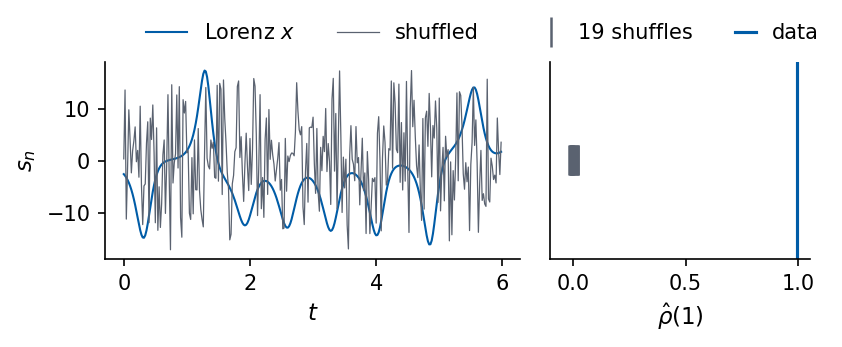

In [61]:
def rho1(s):
    """Lag-one autocorrelation rho_hat(1)."""
    s = s - s.mean()
    return float(np.dot(s[:-1], s[1:]) / np.dot(s, s))

M_SHUFFLE = 19
shuffles = [np.asarray(jax.random.permutation(k, jnp.asarray(x))) for k in jax.random.split(jax.random.key(11), M_SHUFFLE)]
r_data, r_sh = rho1(x), np.array([rho1(s) for s in shuffles])
print(f"Lorenz x: rho(1) data = {r_data:.4f}; 19 shuffles: min {r_sh.min():.4f}, max {r_sh.max():.4f}, std {r_sh.std():.4f}"
      f" (1/sqrt(N) = {1/np.sqrt(N_SAMPLES):.4f})")
nums["shuffle"] = {"rho1_data": r_data, "rho1_min": float(r_sh.min()), "rho1_max": float(r_sh.max())}
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.2), layout="constrained", gridspec_kw=dict(width_ratios=[1.6, 1]))
    t = np.arange(300) * 0.02
    axs[0].plot(t, x[:300], color=COL["lorenz"], lw=1.0, label="Lorenz $x$")
    axs[0].plot(t, shuffles[0][:300], color=UJGray, lw=0.6, label="shuffled")
    axs[0].set_xlabel("$t$"); axs[0].set_ylabel("$s_n$")
    axs[0].legend(fontsize=10, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0))
    axs[1].plot(r_sh, np.zeros_like(r_sh), "|", color=UJGray, ms=14, mew=1.2, label="19 shuffles")
    axs[1].axvline(r_data, color=COL["lorenz"], lw=1.5, label="data")
    axs[1].set_xlim(-0.1, 1.05); axs[1].set_yticks([]); axs[1].set_xlabel(r"$\hat\rho(1)$")
    axs[1].legend(fontsize=10, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, handlelength=1.0)
    save(fig, "fig_surrogate_shuffle"); plt.show()

The data give $\hat\rho(1)=0.994$, the shuffles scatter around zero with a standard deviation close to $1/\sqrt N=0.016$. The order of the samples matters, but every smooth signal passes this test. A rejection of independence says nothing about nonlinearity or determinism, so the null hypothesis is too weak.

### Phase-randomised surrogates

The next null hypothesis is the one relevant for forecasting. It states that the data are a realisation of a stationary linear Gaussian process,
$$
H_0:\quad s_n=\mu+\sum_{j\ge0}h_j\,\eta_{n-j},\qquad \eta_n\ \text{independent}\ \mathcal N(0,1),
$$
possibly observed through a static monotone function $\tilde h$, $\tilde s_n=\tilde h(s_n)$. Such a process is fully described by its mean and its spectrum, which is set by the coefficients $h_j$. A linear Gaussian process has random, independent Fourier phases, so its surrogates are generated in four operations. We compute $X_q$ with the FFT, keep $|X_q|$, draw phases $\phi_q$ uniformly on $[0,2\pi)$ with $\phi_{-q}=-\phi_q$ so that the inverse transform is real (and zero phase at $f=0$ and at $f_{\rm Ny}$), and apply the inverse FFT. The figure shows Lorenz $x$ and three surrogates (left) and the four periodograms, which lie on top of each other (right).

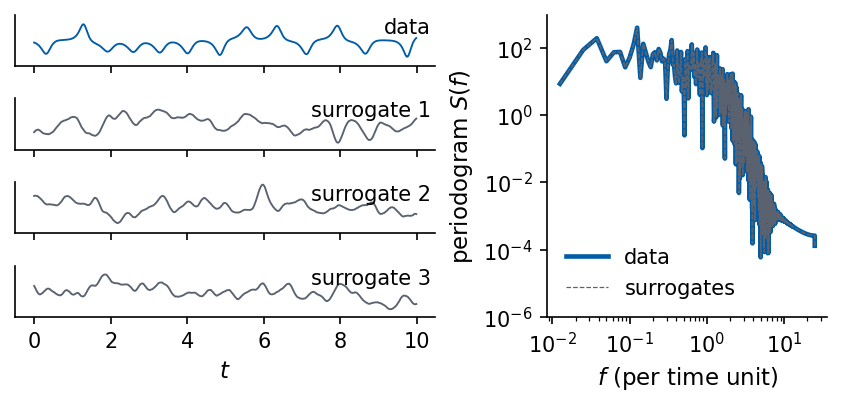

value distribution: data skewness / kurtosis vs surrogate 1: [0.098, -0.656, 0.158, 0.562]


In [62]:
keys3 = jax.random.split(jax.random.key(21), 3)
surr3 = [np.asarray(phase_randomised(jnp.asarray(x), k)) for k in keys3]
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.6), layout="constrained")
    gs = fig.add_gridspec(4, 2, width_ratios=[1.5, 1])
    t = np.arange(500) * 0.02
    for r, (y, c, lab) in enumerate([(x, COL["lorenz"], "data")] + [(s, UJGray, f"surrogate {i+1}") for i, s in enumerate(surr3)]):
        ax = fig.add_subplot(gs[r, 0])
        ax.plot(t, y[:500], color=c, lw=0.9)
        ax.set_yticks([]); ax.set_ylim(-28, 28)
        ax.text(0.99, 0.95, lab, transform=ax.transAxes, ha="right", va="top", fontsize=10)
        if r < 3:
            ax.set_xticklabels([])
        else:
            ax.set_xlabel("$t$")
    ax = fig.add_subplot(gs[:, 1])
    f, P = periodogram_jax(x, 0.02)
    ax.loglog(f[1:], P[1:], color=COL["lorenz"], lw=2.2, label="data")
    for i, s in enumerate(surr3):
        ax.loglog(f[1:], np.asarray(periodogram_jax(s, 0.02)[1])[1:], color=UJGray, lw=0.6, ls="--",
                  label="surrogates" if i == 0 else None)
    ax.set_ylim(1e-6, 1e3); ax.set_xlabel("$f$ (per time unit)"); ax.set_ylabel("periodogram $S(f)$")
    ax.legend(fontsize=10, loc="lower left")
    save(fig, "fig_surrogate_generation"); plt.show()
print("value distribution: data skewness / kurtosis vs surrogate 1:",
      [round(float(v), 3) for v in (scipy.stats.skew(x), scipy.stats.kurtosis(x), scipy.stats.skew(surr3[0]), scipy.stats.kurtosis(surr3[0]))])

The surrogate has the same spectrum as the data and nothing else. In particular its value distribution is close to Gaussian, while the distribution of Lorenz $x$ is bimodal (the kurtosis is $-0.66$ for the data and $+0.56$ for one surrogate). The amplitude-adjusted surrogates of the last subsection also keep the value distribution.

### Time-reversal asymmetry

A linear Gaussian process looks statistically the same when played backwards, because all its properties follow from $R(\tau)=R(-\tau)$. Many nonlinear systems are visibly irreversible. The Santa Fe laser builds up its pulsations slowly and loses them suddenly, and the reversed record would show sudden onsets and slow decays. A simple statistic that detects irreversibility is the skewness of the increments $d_k=s_{k+1}-s_k$,
$$
Q=\frac{\langle d_k^3\rangle}{\langle d_k^2\rangle^{3/2}} .
$$
Time reversal changes the sign of every increment and hence of $Q$, so a time-reversible process has $Q=0$ up to finite-sample fluctuations. A static monotone measurement function keeps a reversible process reversible, so $Q$ is a valid statistic under the extended null hypothesis.

Santa Fe, first 300 samples: Q forward = -0.110, Q time-reversed = 0.110


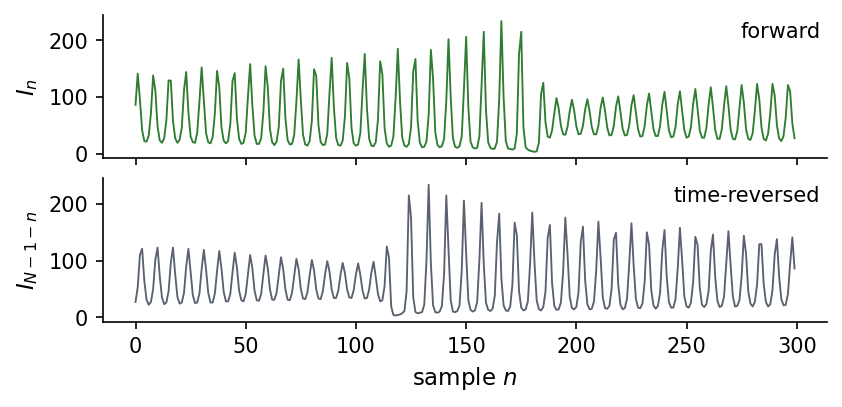

In [63]:
def q_stat(s):
    """Time-reversal asymmetry Q = <d^3> / <d^2>^{3/2}, d_k = s_{k+1} - s_k (skewness of the increments)."""
    d = jnp.diff(s)
    return jnp.mean(d ** 3) / jnp.mean(d ** 2) ** 1.5

seg = S["santafe"][:300]
print(f"Santa Fe, first 300 samples: Q forward = {float(q_stat(jnp.asarray(seg))):.3f}, "
      f"Q time-reversed = {float(q_stat(jnp.asarray(seg[::-1]))):.3f}")
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 2.6), sharex=True, layout="constrained")
    axs[0].plot(seg, color=COL["santafe"], lw=0.9); axs[0].set_ylabel("$I_n$")
    axs[0].text(0.99, 0.95, "forward", transform=axs[0].transAxes, ha="right", va="top", fontsize=10)
    axs[1].plot(seg[::-1], color=UJGray, lw=0.9); axs[1].set_ylabel("$I_{N-1-n}$")
    axs[1].text(0.99, 0.95, "time-reversed", transform=axs[1].transAxes, ha="right", va="top", fontsize=10)
    axs[1].set_xlabel("sample $n$")
    save(fig, "fig_time_reversal"); plt.show()

The figure shows the first 300 Santa Fe samples forward and reversed. On this segment $Q=-0.11$, and the reversed segment has $Q=+0.11$.

In [64]:
TEST_KEYS = ["lorenz", "mg25", "santafe", "ar2"]
TEST_S = {"lorenz": S["lorenz"], "mg25": S["mg25"], "santafe": S["santafe"], "ar2": S_AR}
LABEL["ar2"] = "AR(2) control"; COL["ar2"] = UJNavy
for k in TEST_KEYS:
    print(f"{LABEL[k]:22s} Q = {float(q_stat(jnp.asarray(TEST_S[k]))): .4f}")

Lorenz $x$             Q = -0.0041
MG $\tau_{\rm MG}=25$  Q =  0.2945
Santa Fe               Q = -0.0207
AR(2) control          Q = -0.0125


### Rank test

The test compares the value $Q_{\rm data}$ with the values $Q_1,\dots,Q_M$ of $M$ surrogates. Under $H_0$ the data and the surrogates are exchangeable, so each of the $M+1$ values is equally likely to be the largest or the smallest. We do not know the sign of the asymmetry in advance, so we use a two-sided test with $M=39$. We reject $H_0$ when $Q_{\rm data}$ is the smallest or the largest of the 40 values, which happens under $H_0$ with probability $2/40=0.05$. The rank is the position of $Q_{\rm data}$ among the 40 values (1 is the smallest). As a secondary number we report $z=(Q_{\rm data}-\bar Q_{\rm surr})/\sigma_{\rm surr}$, computed with 200 surrogates, which also give the histograms. The decision uses only the first 39 surrogates.

Lorenz $x$             Q_data = -0.0041 | surrogates mean -0.0013, std 0.0905 | z =    -0.0 | rank 19 of 40 | no rejection
MG $\tau_{\rm MG}=25$  Q_data =  0.2945 | surrogates mean  0.0103, std 0.0904 | z =     3.1 | rank 40 of 40 | reject H0
Santa Fe               Q_data = -0.0207 | surrogates mean  0.0027, std 0.0495 | z =    -0.5 | rank 18 of 40 | no rejection
AR(2) control          Q_data = -0.0125 | surrogates mean  0.0004, std 0.0243 | z =    -0.5 | rank 11 of 40 | no rejection


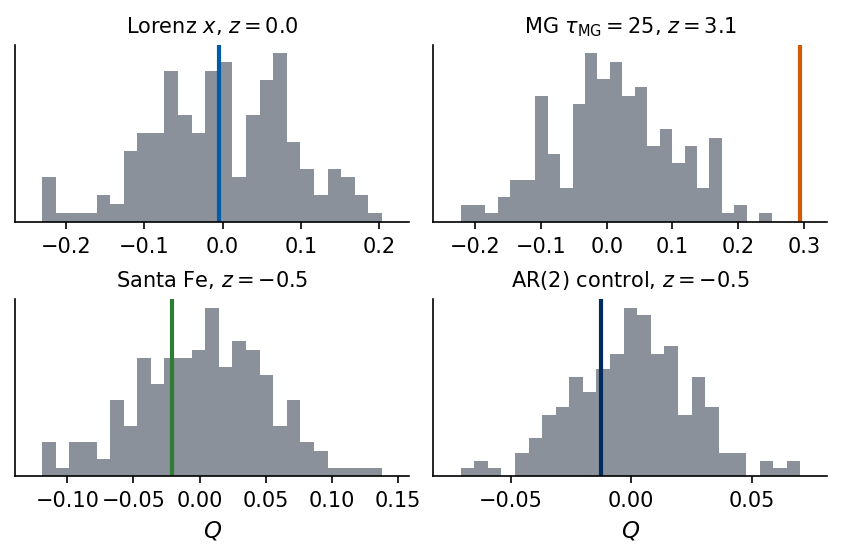

In [65]:
M_TEST = 39                 # two-sided rank test: reject if Q_data is the largest or the smallest of M + 1 values
M_PLOT = 200                # extra surrogates only to draw the histogram
surr_batch = jax.jit(jax.vmap(phase_randomised, in_axes=(None, 0)))
q_batch = jax.jit(jax.vmap(q_stat))
TEST = {}
for i, k in enumerate(TEST_KEYS):
    s = jnp.asarray(TEST_S[k])
    sur = surr_batch(s, jax.random.split(jax.random.key(100 + i), M_PLOT))
    q_d, q_s = float(q_stat(s)), np.asarray(q_batch(sur))
    q_m = q_s[:M_TEST]
    rank = int(np.sum(q_m < q_d)) + 1                     # position of the data among the M + 1 values (1 = smallest)
    reject = rank == 1 or rank == M_TEST + 1
    z = (q_d - q_s.mean()) / q_s.std(ddof=1)
    TEST[k] = {"Q_data": q_d, "Q_surr_mean": float(q_s.mean()), "Q_surr_std": float(q_s.std(ddof=1)), "z": float(z),
               "rank_of_40": rank, "reject": bool(reject), "q_surr": q_s}
    print(f"{LABEL[k]:22s} Q_data = {q_d: .4f} | surrogates mean {q_s.mean(): .4f}, std {q_s.std(ddof=1):.4f} | "
          f"z = {z: 7.1f} | rank {rank:2d} of {M_TEST + 1} | {'reject H0' if reject else 'no rejection'}")
nums["surrogate_test_Q"] = {k: {c: v for c, v in TEST[k].items() if c != "q_surr"} for k in TEST_KEYS}

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 2, figsize=(5.5, 3.6), layout="constrained")
    for ax, k in zip(axs.ravel(), TEST_KEYS):
        T = TEST[k]
        ax.hist(T["q_surr"], bins=25, color=UJGray, alpha=0.7)
        ax.axvline(T["Q_data"], color=COL[k], lw=2.0)
        lo = min(T["q_surr"].min(), T["Q_data"]); hi = max(T["q_surr"].max(), T["Q_data"])
        ax.set_xlim(lo - 0.08 * (hi - lo), hi + 0.08 * (hi - lo))
        ax.set_title(f"{LABEL[k]}, $z={round(T['z'], 1) + 0.0:.1f}$", fontsize=10)  # + 0.0 turns -0.0 into 0.0
        ax.set_yticks([])
    for ax in axs[1]:
        ax.set_xlabel("$Q$")
    save(fig, "fig_surrogate_test"); plt.show()

The histograms show $Q$ over 200 phase-randomised surrogates for each signal, and the vertical line marks the data value. Only the Mackey–Glass signal at $\tau_{\rm MG}=25$ is rejected, with $Q_{\rm data}=0.29$ above all 39 surrogates and $z=3.1$. For the AR(2) control $Q_{\rm data}$ has rank 11 of 40 and $H_0$ is kept, as it should be.

Lorenz $x$ and Santa Fe are not rejected, and the two cases teach different lessons. The Lorenz equations are invariant under $(x,y,z)\to(-x,-y,z)$, so $x$ and $-x$ have the same statistics. Every odd moment of the increments of $x$ vanishes, and $Q$ is zero for this observable whatever the dynamics ($Q_{\rm data}=-0.004$). For Santa Fe the irreversibility lives on the scale of the build-up cycle, while the one-sample increments are dominated by the fast, nearly symmetric pulsations. The next cell repeats the Santa Fe test with increments $d_k=s_{k+t}-s_k$ over $t$ samples.

In [66]:
def q_lagged(s, t):
    """Q at lag t, with increments d_k = s_{k+t} - s_k."""
    d = s[t:] - s[:-t]
    return jnp.mean(d ** 3) / jnp.mean(d ** 2) ** 1.5

s = jnp.asarray(S["santafe"])
sur = surr_batch(s, jax.random.split(jax.random.key(500), M_PLOT))
Z_LAG = {}
for t in range(1, 13):
    q_d = float(q_lagged(s, t))
    q_s = np.asarray(jax.vmap(lambda u: q_lagged(u, t))(sur))
    Z_LAG[t] = (q_d - q_s.mean()) / q_s.std(ddof=1)
    print(f"Santa Fe, lag {t:2d}: Q = {q_d: .3f}, z = {Z_LAG[t]: 6.1f}")
nums["santafe_Q_lag_z"] = {int(t): float(z) for t, z in Z_LAG.items()}

Santa Fe, lag  1: Q = -0.021, z =   -0.3


Santa Fe, lag  2: Q =  0.002, z =    0.0


Santa Fe, lag  3: Q =  0.004, z =    0.1


Santa Fe, lag  4: Q = -0.004, z =   -0.2


Santa Fe, lag  5: Q = -0.016, z =   -0.3


...

Santa Fe, lag  8: Q = -0.774, z =  -17.1


Santa Fe, lag  9: Q = -0.073, z =   -1.1


Santa Fe, lag 10: Q =  0.008, z =    0.2


Santa Fe, lag 11: Q =  0.011, z =    0.4


Santa Fe, lag 12: Q = -0.003, z =   -0.1


The asymmetry appears at increments over one pulsation period, with $z=-8.5$ at $t=7$ and $z=-17.1$ at $t=8$, while $|z|\le1.1$ at all other lags from 1 to 12. The increment $s_{k+t}-s_k$ with $t\approx7$–8 compares the same phase of two consecutive pulsations and follows the slow growth of the amplitude with its sudden drop at the collapse. Here we chose the lag after looking at the data, so this scan illustrates where the asymmetry lives and is no valid test at the 5% level. A non-rejection means that the chosen statistic sees no difference between data and surrogates. It does not show that the signal is linear, and a test is only as good as its statistic.

### Amplitude-adjusted surrogates and a prediction statistic

The phase-randomised surrogates have Gaussian value distributions, while the data do not. A rejection could then come from the static measurement function alone. Schreiber and Schmitz introduced the iterative amplitude-adjusted Fourier-transform (IAAFT) surrogates, which keep the exact value distribution and the spectrum up to a small error [T. Schreiber and A. Schmitz, Phys. Rev. Lett. **77**, 635 (1996), [doi:10.1103/PhysRevLett.77.635](https://doi.org/10.1103/PhysRevLett.77.635)]. Starting from a shuffle of the data, the algorithm alternates two projections. It imposes the Fourier amplitudes of the data while keeping the current phases, and then it replaces the values by the data values of the same rank.

As a statistic sensitive to determinism we use the one-step error $\mathrm{NE}(1)$ of the nearest-neighbour forecast. A deterministic signal is predicted well by its neighbours, a linear stochastic one much worse. The data error is expected to be smaller, so the test is one-sided with $M=19$ and we reject $H_0$ if the data error is the smallest of the 20 values (probability $1/20=0.05$ under $H_0$). For AR(2) we use $m=3$, $\kappa=2$. For AR(1) we use $m=3$, $\kappa=1$. For every record we report the largest deviation of the IAAFT Fourier amplitudes from those of the data over all 19 surrogates.

In [67]:
def iaaft(x, key, n_iter=200):
    """Iterative amplitude-adjusted Fourier-transform surrogate (Schreiber and Schmitz). Start from a random
    permutation of x; repeat (i) impose the Fourier amplitudes |X_q| of x keeping the current phases,
    (ii) impose the values of x by rank ordering. Ends with step (ii): exact value distribution, approximate spectrum."""
    N = x.shape[0]
    amp = jnp.abs(jnp.fft.rfft(x))
    x_sorted = jnp.sort(x)
    def body(_, s):
        S_ = jnp.fft.rfft(s)
        s = jnp.fft.irfft(amp * jnp.exp(1j * jnp.angle(S_)), N)
        return x_sorted[jnp.argsort(jnp.argsort(s))]          # the value of x with the same rank as s_n
    return jax.lax.fori_loop(0, n_iter, body, jax.random.permutation(key, x))

iaaft_batch = jax.jit(jax.vmap(iaaft, in_axes=(None, 0)))

NL_KEYS = TEST_KEYS + ["ar1"]                       # the four records of the Q test and the AR(1) control
NL_S = {**TEST_S, "ar1": S_AR1}
EMB_TEST = {"lorenz": (EMB_M["lorenz"], LAG["lorenz"]), "mg25": (EMB_M["mg25"], LAG["mg25"]),
            "santafe": (EMB_M["santafe"], LAG["santafe"]), "ar2": (3, 2), "ar1": (3, 1)}
M_NL = 19                   # one-sided test: reject if the data error is the smallest of M + 1 = 20 values
NL = {}
for i, k in enumerate(NL_KEYS):
    s = NL_S[k]
    sur = np.asarray(iaaft_batch(jnp.asarray(s), jax.random.split(jax.random.key(300 + i), M_NL)))
    assert np.allclose(np.sort(sur[0]), np.sort(s))                      # same values as the data
    amp_d = np.abs(np.fft.rfft(s))
    spec_err = max(np.abs(np.abs(np.fft.rfft(u)) - amp_d).max() for u in sur) / np.abs(np.fft.rfft(s - s.mean())).max()
    m, lag = EMB_TEST[k]
    e_d = nn_prediction_error(s, m, lag)
    e_s = np.array([nn_prediction_error(u, m, lag) for u in sur])
    rank = int(np.sum(e_s < e_d)) + 1
    NL[k] = {"err_data": e_d, "err_surr_min": float(e_s.min()), "err_surr_mean": float(e_s.mean()), "err_surr_max": float(e_s.max()),
             "z": float((e_d - e_s.mean()) / e_s.std(ddof=1)), "rank_of_20": rank, "reject": rank == 1,
             "spectrum_mismatch": float(spec_err), "err_surr": e_s.tolist()}
    print(f"{LABEL[k]:22s} (m, l) = ({m}, {lag}) | error data {e_d:.4f} | surrogates min {e_s.min():.4f} "
          f"mean {e_s.mean():.4f} | z = {NL[k]['z']: 7.1f} | rank {rank:2d} of 20 | "
          f"{'reject H0' if rank == 1 else 'no rejection'} | IAAFT spectrum mismatch {spec_err:.1e}")
nums["surrogate_test_nnpred"] = NL

Lorenz $x$             (m, l) = (4, 10) | error data 0.0544 | surrogates min 0.2186 mean 0.2319 | z =   -23.9 | rank  1 of 20 | reject H0 | IAAFT spectrum mismatch 6.1e-04


MG $\tau_{\rm MG}=25$  (m, l) = (4, 15) | error data 0.0815 | surrogates min 0.2224 mean 0.2305 | z =   -28.7 | rank  1 of 20 | reject H0 | IAAFT spectrum mismatch 1.2e-03


Santa Fe               (m, l) = (3, 2) | error data 0.2078 | surrogates min 0.6698 mean 0.6837 | z =   -52.1 | rank  1 of 20 | reject H0 | IAAFT spectrum mismatch 2.7e-02


AR(2) control          (m, l) = (3, 2) | error data 0.3644 | surrogates min 0.3582 mean 0.3661 | z =    -0.4 | rank  8 of 20 | no rejection | IAAFT spectrum mismatch 4.8e-04


AR(1) control          (m, l) = (3, 1) | error data 0.8496 | surrogates min 0.8415 mean 0.8568 | z =    -0.7 | rank  4 of 20 | no rejection | IAAFT spectrum mismatch 5.4e-04


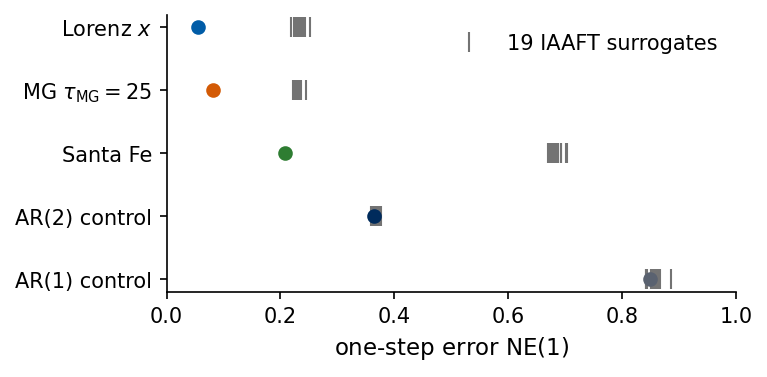

In [68]:
# the data error and the 19 IAAFT surrogate errors of the nearest-neighbour statistic, one row per record
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.0, 2.4), layout="constrained")
    for r, k in enumerate(NL_KEYS):
        ax.plot(NL[k]["err_surr"], np.full(M_NL, r), "|", color="0.45", ms=10, mew=1.0,
                label="19 IAAFT surrogates" if r == 0 else None)
        ax.plot(NL[k]["err_data"], r, "o", color=COL[k], ms=6, label=None)
    ax.set_yticks(range(len(NL_KEYS))); ax.set_yticklabels([LABEL[k] for k in NL_KEYS]); ax.invert_yaxis()
    ax.set_xlabel(r"one-step error $\mathrm{NE}(1)$"); ax.set_xlim(0, 1)
    ax.legend(fontsize=10, loc="upper right")
    save(fig, "fig_surrogate_nnpred"); plt.show()


With this statistic all three signals are rejected with large margins. The data errors are 0.054 (Lorenz $x$), 0.081 ($\tau_{\rm MG}=25$) and 0.21 (Santa Fe), against surrogate errors of at least 0.22, 0.22 and 0.67, and $z$ between $-24$ and $-52$. Neither control is rejected, the AR(2) process has rank 8 and the AR(1) process rank 4 of 20. Over all 19 surrogates of each record the IAAFT Fourier amplitudes differ from those of the data by at most 2.7% of the largest amplitude, the largest deviation occurring for the laser. Rank 1 of 20 is the smallest rank the test can return, and its probability 1/20 under $H_0$ assumes that data and surrogates are exchangeable, which IAAFT surrogates with their approximate spectrum satisfy only approximately. These statements hold for the chosen statistics, one set of surrogates and the records of 4000 samples. A rejection shows structure beyond the linear Gaussian null model, and nonlinear stochastic processes or nonstationary records could produce it too.

### The leading exponent from two estimators

The Rosenstein curve and the Sano–Sawada spectrum of Section 8 gave the laser a leading exponent of 0.029 and 0.065 per sample. Each estimator has one free choice, the fit range $k_0\le k\le k_1$ for Rosenstein and the number $K$ of neighbours for Sano–Sawada, and we scan both. The local slope of $\langle\ln d(k)\rangle$, averaged over one pulsation period of 7 samples, shows whether the curve has a range of constant slope. The rms widths $w_i$ of a neighbourhood along its principal directions, the singular values of the $K$ displacements $\mathbf y_j-\mathbf y_i$ divided by $\sqrt K$, show how much of each direction the local fit can see.

Santa Fe local slope per sample at k = {4: 0.0719, 8: 0.0493, 20: 0.0297, 40: 0.0199, 100: 0.0094}
Lorenz local slope per time unit at k = {10: 1.297, 25: 1.545, 50: 1.061, 100: 0.909}
Santa Fe: <ln d> from k = 0 to 150 grows by 3.05, a factor 21; initial distance exp<ln d(0)> = 2.17 intensity units (one quantisation step = 1)


Santa Fe, m = 4, kappa = 2, K =  16: [ 0.0764 -0.0259 -0.2928 -1.3719]
Santa Fe, m = 4, kappa = 2, K =  32: [ 0.07   -0.018  -0.3176 -1.548 ]
Santa Fe, m = 4, kappa = 2, K =  63: [ 0.0651 -0.0044 -0.3822 -1.5587]
Santa Fe, m = 4, kappa = 2, K = 128: [ 0.0658 -0.0088 -0.4074 -1.5095]
Santa Fe, m = 4, kappa = 2, K = 256: [ 0.0638 -0.0179 -0.4236 -1.3864]
rms widths of the K = 63 neighbourhoods (standardised units): {'santafe': [0.189, 0.1639, 0.0473, 0.0167], 'lorenz': [0.2149, 0.1771, 0.0396, 0.0081]} | Santa Fe quantisation step 0.0205


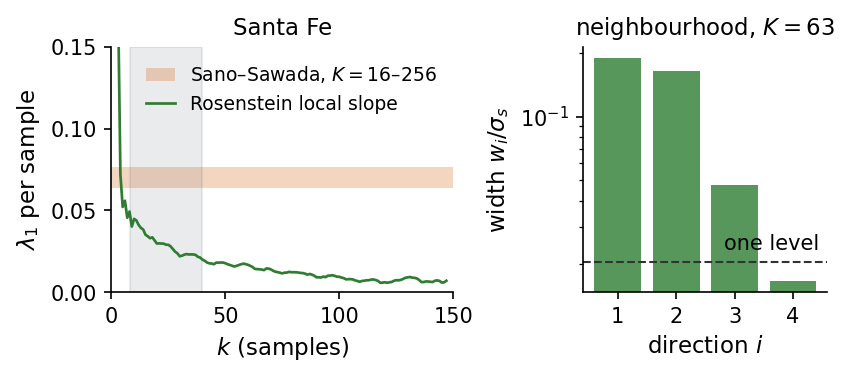

In [69]:
# Rosenstein: local slope of <ln d(k)>, averaged over one pulsation period (7 samples), and the size of the growth range
P_AVG = 7
def local_slope(curve, p=P_AVG):
    return np.convolve(np.gradient(curve), np.ones(p) / p, mode="same")
SLOPE_SF = local_slope(ROS["santafe"])
SLOPE_LOR = local_slope(ROS["lorenz"]) / DT["lorenz"]
K_SHOW_SL = (4, 8, 20, 40, 100)
print("Santa Fe local slope per sample at k =", {k: round(float(SLOPE_SF[k]), 4) for k in K_SHOW_SL})
print("Lorenz local slope per time unit at k =", {k: round(float(SLOPE_LOR[k]), 3) for k in (10, 25, 50, 100)})
growth_sf = ROS["santafe"][150] - ROS["santafe"][0]          # ln of the total growth of the mean pair distance
print(f"Santa Fe: <ln d> from k = 0 to 150 grows by {growth_sf:.2f}, a factor {np.exp(growth_sf):.0f}; "
      f"initial distance exp<ln d(0)> = {np.exp(ROS['santafe'][0]):.2f} intensity units (one quantisation step = 1)")

# Sano-Sawada: dependence on the number K of neighbours, and the shape of the neighbourhoods
K_SCAN = (16, 32, 63, 128, 256)
SS_K = {K: local_jacobian_spectrum(S["santafe"], 4, 2, K) for K in K_SCAN}
for K in K_SCAN:
    print(f"Santa Fe, m = 4, kappa = 2, K = {K:3d}: {np.round(SS_K[K], 4)}")
def neighbourhood_widths(s, m, lag, K, every=5):
    """Median over points of the singular values of the K neighbour displacements y_j - y_i (standardised data),
    divided by sqrt(K): the rms extent of a neighbourhood along its principal directions."""
    z = (s - s.mean()) / s.std()
    Y = delay_embed(z, m, lag)
    _, nb = cKDTree(Y).query(Y, k=K + 1)
    sv = [np.linalg.svd(Y[nb[i, 1:]] - Y[i], compute_uv=False) / np.sqrt(K) for i in range(0, len(Y), every)]
    return np.median(np.array(sv), axis=0)
WID = {"santafe": neighbourhood_widths(S["santafe"], 4, 2, 63), "lorenz": neighbourhood_widths(S["lorenz"], 4, 10, 63)}
Q_STEP = 1.0 / S["santafe"].std()                               # one intensity level in units of the standard deviation
print("rms widths of the K = 63 neighbourhoods (standardised units):",
      {k: np.round(v, 4).tolist() for k, v in WID.items()}, f"| Santa Fe quantisation step {Q_STEP:.4f}")
nums["lyap_two_estimators"] = {"slope_sf": {int(k): float(SLOPE_SF[k]) for k in K_SHOW_SL},
                               "ss_K": {int(K): v.tolist() for K, v in SS_K.items()},
                               "widths": {k: v.tolist() for k, v in WID.items()}, "q_step": float(Q_STEP),
                               "growth_sf": float(growth_sf)}
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained", gridspec_kw=dict(width_ratios=[1.4, 1]))
    kk = np.arange(len(SLOPE_SF))
    lo_ss, hi_ss = min(v[0] for v in SS_K.values()), max(v[0] for v in SS_K.values())
    axs[0].axhspan(lo_ss, hi_ss, color=DSOrange, alpha=0.25, lw=0, label=f"Sano–Sawada, $K={K_SCAN[0]}$–${K_SCAN[-1]}$")
    axs[0].plot(kk[3:-3], SLOPE_SF[3:-3], color=COL["santafe"], label="Rosenstein local slope")
    axs[0].axvspan(*FIT["santafe"], color=UJGray, alpha=0.12)
    axs[0].set_xlabel("$k$ (samples)"); axs[0].set_ylabel(r"$\lambda_1$ per sample"); axs[0].set_ylim(0, 0.15); axs[0].set_xlim(0, 150)
    axs[0].legend(fontsize=9, loc="upper right", handlelength=1.5); axs[0].set_title("Santa Fe")
    w = WID["santafe"]
    axs[1].bar(np.arange(1, 5), w, color=COL["santafe"], alpha=0.8)
    axs[1].axhline(Q_STEP, color="0.2", ls="--", lw=1.0); axs[1].text(4.45, Q_STEP * 1.15, "one level", ha="right", fontsize=10)
    axs[1].set_yscale("log"); axs[1].set_xticks(range(1, 5)); axs[1].set_xlabel("direction $i$")
    axs[1].set_ylabel(r"width $w_i/\sigma_s$"); axs[1].set_title("neighbourhood, $K=63$")
    save(fig, "fig_lyap_two_estimators"); plt.show()


The local slope of the laser curve has no plateau. It falls from 0.072 per sample at $k=4$ to 0.030 at $k=20$ and 0.020 at $k=40$, so the fitted value 0.029 of Section 8 depends on the fit range. The mean distance of neighbours starts at 2.2 intensity units, about two digitiser levels, and grows by a factor of only 21 before it saturates, about three $e$-folds, so the alignment of the separation with the unstable direction and the saturation at the size of the attractor overlap. Sano–Sawada gives a stable leading exponent, between 0.064 and 0.076 per sample for $K=16$ to 256, close to the early local slope of the Rosenstein curve. Its contracting exponents depend on $K$ ($\lambda_3$ from $-0.42$ to $-0.29$, $\lambda_4$ from $-1.56$ to $-1.37$). The reason is visible in the right panel. The laser attractor is thin, and its $K=63$ neighbourhoods have rms widths 0.19 and 0.16 standard deviations along two directions and only 0.047 and 0.017 along the other two, one to two digitiser levels (0.021 standard deviations). In these directions the least-squares maps fit mostly the rounding. Lorenz $x$ shows the same structure with widths 0.040 and 0.008 in the thin directions. The two estimators look at the record on different scales, single pairs over many steps against whole neighbourhoods over one step, and on a short, rounded record of a thin attractor they disagree.

### Correlation dimension against the embedding dimension

A deterministic attractor has a dimension that does not depend on the space in which we embed it, while noise fills every dimension it is given. Grassberger and Procaccia measure this with the correlation sum, the fraction of pairs of delay vectors closer than $r$ [P. Grassberger and I. Procaccia, Phys. Rev. Lett. **50**, 346 (1983), [doi:10.1103/PhysRevLett.50.346](https://doi.org/10.1103/PhysRevLett.50.346)],
$$
\mathcal C_m(r)=\frac{1}{N_c}\sum_{i<j,\;j-i>w}\mathbf 1\big(\|\mathbf y_i-\mathbf y_j\|<r\big) ,
$$
with $\mathbf 1(\cdot)$ equal to 1 when its condition holds and 0 otherwise and $N_c$ the number of pairs that enter the sum. Pairs closer in time than the Theiler window $w=50$ are excluded, because they are close only because the trajectory is continuous [J. Theiler, Phys. Rev. A **34**, 2427 (1986), [doi:10.1103/PhysRevA.34.2427](https://doi.org/10.1103/PhysRevA.34.2427)]. On a set of dimension $D_2$ the sum scales as $C_m(r)\propto r^{D_2}$ at small $r$, so $D_2$ is the slope of $\ln C_m$ against $\ln r$. We standardise every record, embed it with $m=1,\dots,8$, and fit the slope over the radii with $10^{-4}<C_m<10^{-2}$. Next to the five records of the earlier tests we add Lorenz $x$ with independent Gaussian measurement noise of 5% of its standard deviation.

Lorenz $x$           D2(m), m = 1..8: [1.   1.77 2.05 2.11 2.12 2.13 2.12 2.13]


Lorenz + 5% noise    D2(m), m = 1..8: [1.   1.99 2.66 3.01 3.13 3.1  2.96 2.97]


Lorenz surrogate     D2(m), m = 1..8: [0.99 2.   3.01 4.01 4.94 5.63 6.01 6.76]


Santa Fe             D2(m), m = 1..8: [-0.    1.9   2.32  2.42  2.49  2.46  2.47  2.46]


AR(1) control        D2(m), m = 1..8: [1.   1.99 2.96 3.87 4.68 5.44 6.22 6.94]
(15 s); Eckmann-Ruelle bound 2 log10 N = 7.2


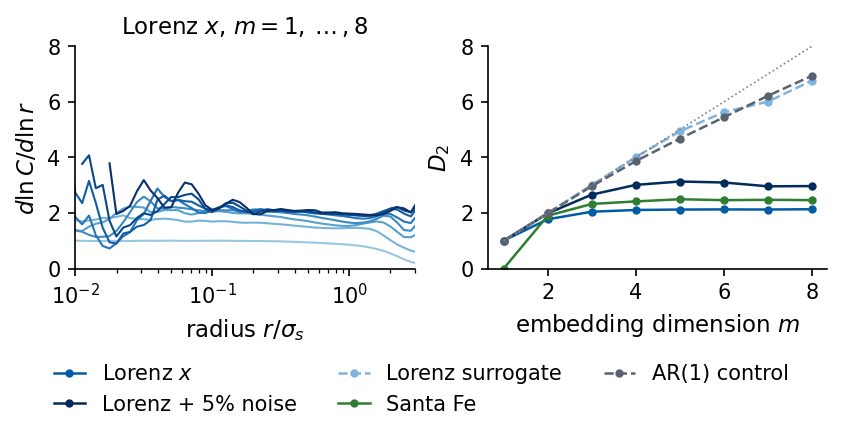

In [70]:
LOG_R = np.linspace(np.log(1e-3), np.log(10.0), 81)            # radii r in units of the standard deviation
DLOG = LOG_R[1] - LOG_R[0]

@partial(jax.jit, static_argnums=1)
def correlation_sum(Y, w=50):
    """C(r) = fraction of pairs (i, j) with j > i + w (Theiler window) and ||y_i - y_j|| < r, for r = exp(LOG_R).
    Each pair distance is put into its logarithmic bin, and a cumulative sum turns the histogram into C(r)."""
    n = Y.shape[0]
    idx = jnp.arange(n)
    def one(i):
        d = jnp.sqrt(jnp.sum((Y - Y[i]) ** 2, axis=1))
        ok = idx > i + w
        b = jnp.clip(jnp.ceil((jnp.log(jnp.maximum(d, 1e-300)) - LOG_R[0]) / DLOG).astype(jnp.int32), 0, len(LOG_R))
        return jnp.zeros(len(LOG_R) + 1).at[b].add(ok)
    hist = jax.lax.map(one, idx, batch_size=250).sum(0)
    return jnp.cumsum(hist)[:-1] / hist.sum()                  # bin b holds distances in (r_{b-1}, r_b]

def d2_estimate(C, c_lo=1e-4, c_hi=1e-2):
    """Slope of ln C against ln r over the radii with c_lo < C(r) < c_hi."""
    sel = (C > c_lo) & (C < c_hi)
    return float(np.polyfit(LOG_R[sel], np.log(C[sel]), 1)[0])

noisy_lorenz = S["lorenz"] + 0.05 * S["lorenz"].std() * np.asarray(jax.random.normal(jax.random.key(9), (N_SAMPLES,)))
LABEL["lornoise"] = "Lorenz + 5% noise"; COL["lornoise"] = "#002B5C"
CD_SET = {"lorenz": (S["lorenz"], LAG["lorenz"]), "lornoise": (noisy_lorenz, LAG["lorenz"]),
          "lorsurr": (xs, LAG["lorenz"]), "santafe": (S["santafe"], LAG["santafe"]), "ar1": (S_AR1, 1)}
M_CD = np.arange(1, 9)
CSUM, D2 = {}, {}
t0 = time.time()
for k, (s, lag) in CD_SET.items():
    z = (s - s.mean()) / s.std()
    CSUM[k] = {int(m): np.asarray(correlation_sum(jnp.asarray(delay_embed(z, m, lag)))) for m in M_CD}
    D2[k] = np.array([d2_estimate(CSUM[k][int(m)]) for m in M_CD])
    print(f"{LABEL[k]:20s} D2(m), m = 1..8: {np.round(D2[k], 2)}")
print(f"({time.time() - t0:.0f} s); Eckmann-Ruelle bound 2 log10 N = {2 * np.log10(N_SAMPLES):.1f}")
nums["corr_dim"] = {k: D2[k].tolist() for k in CD_SET}
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.8), layout="constrained")
    cmap = plt.get_cmap("Blues")
    for m in M_CD:
        C = CSUM["lorenz"][int(m)]
        ok = C > 1e-6
        slope_r = np.gradient(np.log(np.where(ok, C, 1e-6)), LOG_R)
        axs[0].plot(np.exp(LOG_R[ok]), slope_r[ok], color=cmap(0.3 + 0.7 * m / M_CD[-1]), lw=1.0)
    axs[0].set_xscale("log"); axs[0].set_xlim(1e-2, 3); axs[0].set_ylim(0, 8)
    axs[0].set_xlabel(r"radius $r/\sigma_s$"); axs[0].set_ylabel(r"$d\ln C/d\ln r$"); axs[0].set_title("Lorenz $x$, $m=1,\\dots,8$")
    for k in CD_SET:
        ls = "--" if k in ("lorsurr", "ar1") else "-"
        axs[1].plot(M_CD, D2[k], ls, marker="o", ms=3, color=COL[k], lw=1.2, label=LABEL[k])
    axs[1].plot(M_CD, M_CD, ":", color="0.5", lw=0.8)
    axs[1].set_xlabel("embedding dimension $m$"); axs[1].set_ylabel("$D_2$"); axs[1].set_ylim(0, 8)
    fig.legend(*axs[1].get_legend_handles_labels(), loc="outside lower center", ncol=3, fontsize=10, handlelength=1.5)
    save(fig, "fig_corr_dim"); plt.show()


The local slopes of Lorenz $x$ rise with $m$ and then collect on a plateau near 2 over about a decade of radii, and the fitted $D_2$ saturates at 2.13, close to $D_{\rm KY}=2.06$. The laser saturates at 2.46 (its $D_2=0$ at $m=1$ reflects the 243 discrete levels, which make every small radius contain the same pairs). The Lorenz surrogate and AR(1) grow with $m$ nearly as $D_2=m$, to 6.76 and 6.94 at $m=8$. Measurement noise of 5% raises the Lorenz value to between 2.97 and 3.13 for $m\ge4$, since the fit range lies at radii where the noise already fills all directions.

### Limits of the diagnostics

Three limits apply to every result of this section. Measurement noise fills the small scales, which raises the correlation dimension, shortens the scaling range of the Rosenstein curve and fills the thin directions of the local maps. The surrogate test rejects one null hypothesis, a stationary linear Gaussian process seen through a static monotone measurement, and a nonlinear random process, a nonstationary record or a measuring device with memory can produce a rejection as well. A finite record limits every dimension estimate. Eckmann and Ruelle showed that dimensions estimated from $N$ points cannot exceed about $2\log_{10}N$, here 7.2 [J.-P. Eckmann and D. Ruelle, Physica D **56**, 185 (1992), [doi:10.1016/0167-2789(92)90023-G](https://doi.org/10.1016/0167-2789(92)90023-G)], and the noise records at $m=8$ approach this bound, while the deterministic plateaus near two lie far below it.

<hr/>
## 11. Summary table

The table collects the characterisation of the five signals. Correlation times and the delay $\kappa$ are in samples. The leading exponent comes from the Benettin algorithm for the model signals and from the Rosenstein fit over $k=8$–40 for Santa Fe, where the local-Jacobian estimate is printed below the table. The Lyapunov time $T_\lambda=1/\lambda_1$ is in samples and set to infinity where $\lambda_1$ is zero within its error. The same table is written as a LaTeX tabular for the slides, where R and SS denote the Rosenstein and Sano–Sawada estimates.

In [71]:
PSD_CHAR = {"lorenz": "broadband", "mg15": "lines", "mg25": "broad peaks", "mg35": "broad peaks", "santafe": "peak + harmonics"}
lam1_sample = {"lorenz": lam_lor[0] * DT["lorenz"], "mg15": LYAP_MG["mg15"][0], "mg25": LYAP_MG["mg25"][0],
               "mg35": LYAP_MG["mg35"][0], "santafe": lam_ros["santafe"]}
METHOD = {"lorenz": "Benettin", "mg15": "Benettin", "mg25": "Benettin", "mg35": "Benettin", "santafe": "Rosenstein"}
rows = []
for k in KEYS:
    l1 = lam1_sample[k]
    chaotic = l1 > 3 * (err_lor[0] * DT["lorenz"] if k == "lorenz" else ERR_MG[k][0] if k in ERR_MG else 0)
    rows.append({"signal": LABEL[k], "ACF zero": CT[k][0], "ACF 1/e": CT[k][1], "PSD": PSD_CHAR[k],
                 "delay κ": LAG[k], "m": EMB_M[k], "lambda_1 per sample": l1,
                 "lambda_1 per time unit": l1 / DT[k] if k != "santafe" else np.nan,
                 "method": METHOD[k], "D_KY": DKY[k], "T_lambda (samples)": 1 / l1 if chaotic else np.inf})
summary = pd.DataFrame(rows).set_index("signal")
display(summary.round(4))
print(f"Santa Fe, local-Jacobian (Sano-Sawada) lambda_1 = {ss_m4[0]:.4f} per sample, T_lambda = {1/ss_m4[0]:.1f} samples")
for k in KEYS:
    print(f"{LABEL[k]:22s} mean error growth over the horizon of {TAU_MAX} steps, exp(lambda_1 * {TAU_MAX}) = {np.exp(lam1_sample[k] * TAU_MAX):.2f}")
print(f"Santa Fe with the local-Jacobian lambda_1: exp(lambda_1 * {TAU_MAX}) = {np.exp(ss_m4[0] * TAU_MAX):.1f}")
nums["summary"] = {k: {c: (v if isinstance(v, str) else float(v)) for c, v in r.items()} for k, r in zip(KEYS, rows)}

,ACF zero,ACF 1/e,PSD,delay κ,m,lambda_1 per sample,lambda_1 per time unit,method,D_KY,T_lambda (samples)
signal,,,,,,,,,,
Lorenz $x$,89,15,broadband,10,4,0.0181,0.9068,Benettin,2.0622,55.1413
MG $\tau_{\rm MG}=15$,11,9,lines,8,2,-0.0000,-0.0000,Benettin,1.0000,inf
MG $\tau_{\rm MG}=25$,18,12,broad peaks,15,4,0.0099,0.0099,Benettin,3.1576,100.5282
MG $\tau_{\rm MG}=35$,24,15,broad peaks,21,4,0.0029,0.0029,Benettin,3.4058,339.6271
Santa Fe,2,2,peak + harmonics,2,3,0.0291,NaN,Rosenstein,2.1590,34.3358


Santa Fe, local-Jacobian (Sano-Sawada) lambda_1 = 0.0651 per sample, T_lambda = 15.4 samples
Lorenz $x$             mean error growth over the horizon of 50 steps, exp(lambda_1 * 50) = 2.48
MG $\tau_{\rm MG}=15$  mean error growth over the horizon of 50 steps, exp(lambda_1 * 50) = 1.00
MG $\tau_{\rm MG}=25$  mean error growth over the horizon of 50 steps, exp(lambda_1 * 50) = 1.64
MG $\tau_{\rm MG}=35$  mean error growth over the horizon of 50 steps, exp(lambda_1 * 50) = 1.16
Santa Fe               mean error growth over the horizon of 50 steps, exp(lambda_1 * 50) = 4.29
Santa Fe with the local-Jacobian lambda_1: exp(lambda_1 * 50) = 26.0


In [72]:
def tex_num(v, d):
    return "--" if not np.isfinite(v) else f"{v:.{d}f}"
SIGNAL_TEX = {"lorenz": "Lorenz $x$", "mg15": "MG, $\\tau_{\\rm MG}=15$", "mg25": "MG, $\\tau_{\\rm MG}=25$",
              "mg35": "MG, $\\tau_{\\rm MG}=35$", "santafe": "Santa Fe"}
lines = ["\\begin{tabular}{lrrlrrrrr}", "\\toprule",
         "signal & $\\rho=0$ & $\\rho=1/e$ & PSD & $\\kappa$ & $m$ & $\\lambda_1$/sample & $D_{\\rm KY}$ & $T_\\lambda$ \\\\",
         "\\midrule"]
for k in KEYS:
    r = nums["summary"][k]
    l1 = f"{r['lambda_1 per sample']:.4f}" if k != "mg15" else "$\\approx 0$"
    if k == "santafe":
        l1 += f" (R), {ss_m4[0]:.3f} (SS)"
    T = "$\\infty$" if not np.isfinite(r["T_lambda (samples)"]) else f"{r['T_lambda (samples)']:.0f}"
    lines.append(f"{SIGNAL_TEX[k]} & {r['ACF zero']:.0f} & {r['ACF 1/e']:.0f} & {r['PSD']} & {r['delay κ']:.0f} & "
                 f"{r['m']:.0f} & {l1} & {r['D_KY']:.2f} & {T} \\\\")
lines += ["\\bottomrule", "\\end{tabular}"]
with open(f"{OUT}/table_lab033_summary.tex", "w") as fh:
    fh.write("\n".join(lines) + "\n")
print("\n".join(lines))

\begin{tabular}{lrrlrrrrr}
\toprule
signal & $\rho=0$ & $\rho=1/e$ & PSD & $\kappa$ & $m$ & $\lambda_1$/sample & $D_{\rm KY}$ & $T_\lambda$ \\
\midrule
Lorenz $x$ & 89 & 15 & broadband & 10 & 4 & 0.0181 & 2.06 & 55 \\
MG, $\tau_{\rm MG}=15$ & 11 & 9 & lines & 8 & 2 & $\approx 0$ & 1.00 & $\infty$ \\
MG, $\tau_{\rm MG}=25$ & 18 & 12 & broad peaks & 15 & 4 & 0.0099 & 3.16 & 101 \\
MG, $\tau_{\rm MG}=35$ & 24 & 15 & broad peaks & 21 & 4 & 0.0029 & 3.41 & 340 \\
Santa Fe & 2 & 2 & peak + harmonics & 2 & 3 & 0.0291 (R), 0.065 (SS) & 2.16 & 34 \\
\bottomrule
\end{tabular}


<hr/>
## 12. Consequences for forecasting

The forecasting labs use horizons of 1 to 50 steps, and the Lyapunov times give the scale against which to read them. For Lorenz $x$ the Lyapunov time is 55 samples, so the longest horizon is about one $T_\lambda$, over which an initial error grows on average by the factor $e^{50/T_\lambda}=2.5$. For $\tau_{\rm MG}=25$ ($T_\lambda\approx100$ samples) and $\tau_{\rm MG}=35$ ($T_\lambda\approx340$ samples) all horizons lie well within one Lyapunov time (error growth by the factors 1.64 and 1.16 over 50 steps), and the limit to forecasting comes from how well a model learns the dynamics. The periodic $\tau_{\rm MG}=15$ has no finite Lyapunov time, and a model that captures its line spectrum can forecast it at all horizons. The laser has the shortest Lyapunov time, 34 samples from the Rosenstein estimate and 15 from the local Jacobians, so the horizon of 50 steps spans 1.5 to 3.2 Lyapunov times and an initial error grows by a factor between 4.3 and 26 over it. Forecasts of the laser must lose skill within the tested range.

The embedding sets the length of the input window. A model that receives the delay vector with $m$ entries at spacing $\kappa$ sees a window of $(m-1)\kappa+1$ samples, 31 samples for Lorenz $x$, 46 for $\tau_{\rm MG}=25$, 64 for $\tau_{\rm MG}=35$ and 5 for Santa Fe. Shorter windows leave states unresolved, and for Mackey–Glass the window must reach back over the delay of the equation.

The exponents and the dimensions point to nonlinear models. All three chaotic signals have a positive leading Lyapunov exponent and attractors with $D_{\rm KY}$ between 2 and 3.5. In the logistic map of Section 7 such sensitivity arises from stretching and folding, and a linear model fitted to these signals can reproduce their spectra but no folding. Linear autoregressive models are therefore baselines for these signals, and the gain of a nonlinear model, such as the nonlinear vector autoregression or a recurrent network, is expected where the folding acts, at the lobe switches of Lorenz and at the collapses of the laser. The surrogate test of Section 10 supports the same conclusion with a hypothesis test, in which the nearest-neighbour prediction error rejects the linear Gaussian null model for all three chaotic signals.

<hr/>
## Summary

We characterised three signals that serve as benchmarks for forecasting. Constant, periodic and quasi-periodic signals are forecast exactly from their past, white noise at best by its mean and the random walk by its last value. For AR(1) persistence errs more than the conditional mean, NMSE 0.399 against 0.359 for $\phi=0.8$, although both forecasts have the same correlation with the target. Chaotic signals are deterministic, and their forecasts are still limited by the exponential growth of small errors. Lorenz-63 is a three-mode model of convection whose two convective fixed points lose stability at $\rho_c=24.737$. Mackey–Glass is a delay equation with an infinite-dimensional state, here periodic at $\tau_{\rm MG}=15$ and chaotic at 25 and 35. The Santa Fe record is the intensity of a chaotic NH$_3$ laser described by the Maxwell–Bloch equations.

The ACF and the PSD are a Fourier pair, which holds also for the finite-sample estimates. The periodogram needs a window against leakage and averaging (Welch) against its large variance. The periodic Mackey–Glass signal has a line spectrum with the strongest line at period $\approx3\tau_{\rm MG}$ and its fundamental at twice that period. The chaotic signals have broadband spectra, Santa Fe with a pulsation peak at 7.26 samples.

Delay vectors $(s_n,s_{n-\kappa},\dots,s_{n-(m-1)\kappa})$ reconstruct the state space (Takens). The mutual information gives the delay $\kappa$ and false nearest neighbours the dimension $m$. Chaos arises from stretching and folding, as the logistic map shows with $\lambda=\ln2$ at $r=4$. The Benettin QR algorithm with JAX derivatives of the integration step gives the Lorenz spectrum $(0.907,0,-14.573)$ with the exact Liouville sum and the Mackey–Glass spectra in state spaces of up to 351 dimensions. From data, Rosenstein and Sano–Sawada estimates of $\lambda_1$ for the laser differ by a factor of two, and the method must be stated with the number. The Kaplan–Yorke dimension turns the spectrum into an attractor dimension, 2.06 for Lorenz and 3.16 and 3.41 for the chaotic Mackey–Glass signals. For the dissipative baker's map the Kaplan–Yorke, box-counting and information dimensions all equal $1+\ln2/\ln3=1.631$, which confirms the interpolation of Kaplan and Yorke in a case where the answer is known. The Lyapunov time sets the prediction horizon $T_{\rm pred}=\lambda_1^{-1}\ln(\Delta/\delta_0)$, confirmed by the error growth of nearby Lorenz trajectories.

Section 10 turns the difference between chaos and coloured noise with the same spectrum into a hypothesis test. Phase-randomised and amplitude-adjusted surrogates realise the linear Gaussian null model, a statistic such as the time-reversal asymmetry or the nearest-neighbour prediction error measures what the null model lacks, and the rank of the data among the surrogates decides. The prediction error rejects the null model for all three chaotic signals and keeps it for linear AR(2) and AR(1) controls, while the time-reversal asymmetry at lag one rejects only Mackey–Glass, which shows that the result depends on the statistic. False nearest neighbours separate chaos from noise only at small $m$, the nearest-neighbour forecast separates them at every horizon, and the correlation dimension saturates near 2.1 for Lorenz and 2.5 for the laser while it grows with $m$ for noise. On the laser the Rosenstein and Sano–Sawada estimates of $\lambda_1$ differ because the curve of neighbour distances has no scaling range and the thin directions of the neighbourhoods hold only the rounding of the digitiser.